# Phân cụm khách hàng sàn thương mại điện tử

Bài thực nghiệm giữa kỳ môn Phân tích và Khai phá dữ liệu.

- Mã sinh viên: 24022391 (a = 1, b = 4, c = 3)
- Số bản ghi: N = 220; số thuộc tính đầu vào: 12
- Số bản ghi ngoại lai chủ động tạo: tối thiểu 11

Notebook được chia theo các câu a–e và cần chạy tuần tự từ cell đầu tiên. Bộ sinh ngẫu nhiên được khởi tạo một lần với `np.random.default_rng(42)`, nên chạy lại toàn bộ notebook sẽ cho cùng dữ liệu.

In [1]:
import re
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, davies_bouldin_score, silhouette_score
from sklearn.preprocessing import OneHotEncoder, RobustScaler, StandardScaler

SEED = 42
STUDENT_ID = "24022391"
N_CUSTOMERS = 220
N_INPUT_FEATURES = 12
MIN_OUTLIER_IDS = 11

PROJECT_DIR = Path.cwd().resolve()
if PROJECT_DIR.name == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent
DATA_DIR = PROJECT_DIR / "data"
METADATA_DIR = PROJECT_DIR / "metadata"
FIGURE_DIR = PROJECT_DIR / "figures"
RESULT_DIR = PROJECT_DIR / "results"
for directory in [DATA_DIR, METADATA_DIR, FIGURE_DIR, RESULT_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid")
# Cảnh báo về rò rỉ bộ nhớ của KMeans với MKL trên Windows; không ảnh hưởng kết quả phân cụm.
warnings.filterwarnings("ignore", message="KMeans is known to have a memory leak")
print("Project directory:", PROJECT_DIR)

Project directory: T:\Datamining-\customer_segmentation


## Câu a — Thiết kế và sinh dữ liệu

### a.1. Thiết kế thuộc tính

Mỗi bản ghi là một khách hàng, kèm `customer_id` dùng để định danh và đối chiếu giữa các phiên bản dữ liệu. `customer_id` không phải thuộc tính đầu vào của thuật toán. Đơn vị tiền tệ là **nghìn đồng**.

| Thuộc tính | Ý nghĩa | Kiểu | Lý do lựa chọn |
|---|---|---|---|
| `tenure_months` | Thời gian tham gia sàn (tháng) | int | Phân biệt khách lâu năm với khách mới |
| `recency_days` | Số ngày kể từ lần mua gần nhất | int | Thành phần R trong mô hình RFM, phản ánh mức độ còn hoạt động |
| `orders_6m` | Số đơn trong 6 tháng gần nhất | int | Thành phần F (tần suất mua) |
| `total_spend_6m` | Tổng chi tiêu 6 tháng | float | Thành phần M (giá trị tiền tệ) |
| `avg_order_value` | Giá trị đơn trung bình | float | Tách khách mua ít nhưng giá trị cao với khách mua nhiều đơn nhỏ |
| `sessions_30d` | Số phiên truy cập trong 30 ngày | int | Mức độ tương tác, không đồng nghĩa với mua hàng |
| `discount_usage_rate` | Tỷ lệ đơn có dùng mã giảm giá | float [0, 1] | Nhận diện mức nhạy cảm với khuyến mãi |
| `return_rate` | Tỷ lệ đơn bị hoàn trả | float [0, 1] | Chất lượng giao dịch, rủi ro vận hành |
| `category_diversity` | Số danh mục sản phẩm đã mua (1–8) | int | Độ rộng nhu cầu mua sắm |
| `cart_abandonment_rate` | Tỷ lệ giỏ hàng bị bỏ dở | float [0, 1] | Phân biệt khách chỉ xem với khách chuyển đổi thành đơn |
| `favorite_category` | Danh mục mua nhiều nhất | category (8 mức) | Đặc điểm sở thích, hỗ trợ diễn giải cụm |
| `preferred_device` | Thiết bị mua sắm chủ yếu | category (3 mức) | Hành vi kênh mua hàng |

In [2]:
NUMERIC_FEATURES = [
    "tenure_months", "recency_days", "orders_6m", "total_spend_6m",
    "avg_order_value", "sessions_30d", "discount_usage_rate", "return_rate",
    "category_diversity", "cart_abandonment_rate",
]
CATEGORICAL_FEATURES = ["favorite_category", "preferred_device"]
INPUT_FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES
COUNT_FEATURES = ["tenure_months", "recency_days", "orders_6m", "sessions_30d", "category_diversity"]
RATE_FEATURES = ["discount_usage_rate", "return_rate", "cart_abandonment_rate"]

CATEGORIES = [
    "Fashion", "Electronics", "Home & Living", "Beauty & Health",
    "Groceries", "Sports & Outdoor", "Books & Stationery", "Mother & Baby",
]
DEVICES = ["Mobile App", "Mobile Web", "Desktop"]

assert len(INPUT_FEATURES) == N_INPUT_FEATURES

### a.2. Cơ chế sinh dữ liệu

Dữ liệu được sinh từ bốn nhóm hành vi tiềm ẩn. Mỗi nhóm có bộ tham số phân phối riêng, nhưng các phân phối được chọn đủ rộng để các nhóm giao thoa nhau:

| Nhóm | Số khách | Đặc trưng chính |
|---|---|---|
| Loyal | 55 | Nhiều đơn, giá trị đơn cao, recency thấp, ít bỏ giỏ |
| Discount Seeker | 60 | Tỷ lệ dùng giảm giá cao, giá trị đơn thấp hơn, chi tiêu vừa phải |
| Browser | 55 | Truy cập nhiều, ít đơn, tỷ lệ bỏ giỏ cao |
| Inactive | 50 | Ít truy cập, ít đơn, recency cao |

Phân phối sử dụng:

- `tenure_months`: Normal, làm tròn và cắt trong [1, 120].
- `orders_6m` = 1 + Poisson(λ theo nhóm).
- `avg_order_value`: Lognormal, vì giá trị tiền tệ thường lệch phải.
- `sessions_30d`: Poisson với cường độ nhân thêm hệ số Gamma(3, 1/3), tức phân phối Negative Binomial. Hệ số này tạo khác biệt giữa các cá nhân trong cùng nhóm, làm các nhóm chồng lấn hơn.
- `recency_days`: Exponential với thang đo 180 / (orders_6m + 1) × hệ số nhóm. Khách mua nhiều thì lần mua gần nhất có xu hướng gần hơn.
- Các tỷ lệ: Beta, nên luôn nằm trong [0, 1].
- `category_diversity` = 1 + Poisson, cắt tối đa 8 (số danh mục của sàn).
- Hai biến phân loại: phân phối categorical với xác suất khác nhau theo nhóm.

Quy ước đơn giản hóa để dữ liệu nhất quán logic:

1. Tập khách hàng chỉ gồm khách có ít nhất 1 đơn trong 6 tháng, nên `orders_6m ≥ 1` và `recency_days ≤ 180`. Nhờ vậy `avg_order_value` luôn xác định.
2. `total_spend_6m = orders_6m × avg_order_value` (định nghĩa của giá trị đơn trung bình).
3. `recency_days ≤ 30 × tenure_months`: không thể mua trước khi tham gia sàn.
4. Nếu `recency_days ≤ 30` thì `sessions_30d ≥ 1`: có mua trong 30 ngày thì phải có ít nhất một phiên truy cập.
5. Các tỷ lệ được sinh như xu hướng hành vi liên tục, không suy ra từ số đơn rời rạc. Với khách chỉ có 1–2 đơn, tỷ lệ thực tế sẽ thô hơn.

Nhãn `true_segment` chỉ được lưu trong metadata để kiểm chứng giả lập. Nhãn này không nằm trong dữ liệu đầu vào và không được dùng ở bước tiền xử lý hay chọn mô hình.

In [3]:
SEGMENT_SIZES = {"Loyal": 55, "Discount Seeker": 60, "Browser": 55, "Inactive": 50}

# Xác suất danh mục theo thứ tự CATEGORIES; xác suất thiết bị theo thứ tự DEVICES.
SEGMENT_PARAMS = {
    "Loyal": dict(
        tenure=(36, 14), extra_orders=11.0, aov_median=650, aov_sigma=0.35,
        recency_factor=0.8, session_rate=16, discount_beta=(2, 6), return_beta=(1.5, 18),
        extra_categories=3.5, cart_beta=(2, 7),
        category_probs=[0.15, 0.20, 0.18, 0.12, 0.15, 0.08, 0.06, 0.06],
        device_probs=[0.60, 0.15, 0.25],
    ),
    "Discount Seeker": dict(
        tenure=(22, 12), extra_orders=6.0, aov_median=380, aov_sigma=0.35,
        recency_factor=1.0, session_rate=14, discount_beta=(7, 3), return_beta=(2, 12),
        extra_categories=2.5, cart_beta=(4, 5),
        category_probs=[0.25, 0.08, 0.12, 0.20, 0.18, 0.07, 0.04, 0.06],
        device_probs=[0.55, 0.30, 0.15],
    ),
    "Browser": dict(
        tenure=(15, 10), extra_orders=1.5, aov_median=450, aov_sigma=0.45,
        recency_factor=1.2, session_rate=24, discount_beta=(3, 5), return_beta=(2, 10),
        extra_categories=1.2, cart_beta=(7, 3),
        category_probs=[0.22, 0.25, 0.10, 0.12, 0.05, 0.12, 0.09, 0.05],
        device_probs=[0.35, 0.35, 0.30],
    ),
    "Inactive": dict(
        tenure=(24, 16), extra_orders=0.4, aov_median=400, aov_sigma=0.50,
        recency_factor=1.4, session_rate=4, discount_beta=(2, 4), return_beta=(1.5, 12),
        extra_categories=0.4, cart_beta=(4, 4),
        category_probs=[0.18, 0.14, 0.14, 0.12, 0.12, 0.10, 0.10, 0.10],
        device_probs=[0.30, 0.40, 0.30],
    ),
}

assert sum(SEGMENT_SIZES.values()) == N_CUSTOMERS
for params in SEGMENT_PARAMS.values():
    assert np.isclose(sum(params["category_probs"]), 1) and np.isclose(sum(params["device_probs"]), 1)

In [4]:
def generate_segment(size, params, rng):
    # Sinh khách hàng của một nhóm tiềm ẩn theo bộ tham số của nhóm đó.
    tenure = np.clip(np.round(rng.normal(*params["tenure"], size)), 1, 120).astype(int)
    orders = 1 + rng.poisson(params["extra_orders"], size)
    avg_order_value = rng.lognormal(np.log(params["aov_median"]), params["aov_sigma"], size).round(2)
    total_spend = (orders * avg_order_value).round(2)

    recency_scale = 180 / (orders + 1) * params["recency_factor"]
    recency = np.clip(np.round(rng.exponential(recency_scale)), 0, 180).astype(int)
    recency = np.minimum(recency, 30 * tenure)

    # Gamma-Poisson: mỗi khách có cường độ truy cập riêng quanh mức trung bình của nhóm.
    session_intensity = params["session_rate"] * rng.gamma(3.0, 1 / 3.0, size)
    sessions = rng.poisson(session_intensity)
    sessions = np.where(recency <= 30, np.maximum(sessions, 1), sessions)

    return pd.DataFrame({
        "tenure_months": tenure,
        "recency_days": recency,
        "orders_6m": orders,
        "total_spend_6m": total_spend,
        "avg_order_value": avg_order_value,
        "sessions_30d": sessions,
        "discount_usage_rate": rng.beta(*params["discount_beta"], size).round(3),
        "return_rate": rng.beta(*params["return_beta"], size).round(3),
        "category_diversity": np.minimum(1 + rng.poisson(params["extra_categories"], size), len(CATEGORIES)),
        "cart_abandonment_rate": rng.beta(*params["cart_beta"], size).round(3),
        "favorite_category": rng.choice(CATEGORIES, size, p=params["category_probs"]),
        "preferred_device": rng.choice(DEVICES, size, p=params["device_probs"]),
    })


def generate_clean_customers(rng):
    parts = []
    for segment, size in SEGMENT_SIZES.items():
        part = generate_segment(size, SEGMENT_PARAMS[segment], rng)
        part.insert(0, "true_segment", segment)
        parts.append(part)
    customers = pd.concat(parts, ignore_index=True)
    # Xáo trộn để thứ tự bản ghi không lộ nhóm tiềm ẩn.
    customers = customers.iloc[rng.permutation(len(customers))].reset_index(drop=True)
    customers.insert(0, "customer_id", [f"C{i:04d}" for i in range(1, len(customers) + 1)])
    return customers

In [5]:
rng = np.random.default_rng(SEED)

simulated = generate_clean_customers(rng)
customers_original = simulated[["customer_id"] + INPUT_FEATURES].copy()
segment_labels = simulated[["customer_id", "true_segment"]].copy()

print(customers_original.shape)
customers_original.head()

(220, 13)


,customer_id,tenure_months,recency_days,orders_6m,total_spend_6m,avg_order_value,sessions_30d,discount_usage_rate,return_rate,category_diversity,cart_abandonment_rate,favorite_category,preferred_device
0,C0001,1,30,2,895.20,447.60,18,0.789,0.147,1,0.317,Home & Living,Mobile App
1,C0002,39,3,11,5814.60,528.60,6,0.333,0.017,4,0.129,Electronics,Mobile App
2,C0003,40,122,1,388.01,388.01,40,0.184,0.240,1,0.834,Sports & Outdoor,Desktop
3,C0004,45,24,18,9305.82,516.99,15,0.188,0.002,4,0.308,Electronics,Mobile App
4,C0005,53,2,14,6774.32,483.88,12,0.385,0.026,3,0.299,Beauty & Health,Mobile App


In [6]:
def check_clean_data(df):
    # Kiểm tra các ràng buộc logic của dữ liệu sạch.
    assert len(df) == N_CUSTOMERS
    assert df["customer_id"].is_unique
    assert [c for c in df.columns if c != "customer_id"] == INPUT_FEATURES
    assert not df[INPUT_FEATURES].isna().any().any()
    for col in COUNT_FEATURES:
        assert pd.api.types.is_integer_dtype(df[col]) and (df[col] >= 0).all(), col
    for col in RATE_FEATURES:
        assert df[col].between(0, 1).all(), col
    assert (df["orders_6m"] >= 1).all() and (df["recency_days"] <= 180).all()
    assert np.allclose(df["total_spend_6m"], df["orders_6m"] * df["avg_order_value"], atol=0.01)
    assert (df["recency_days"] <= 30 * df["tenure_months"]).all()
    assert (df.loc[df["recency_days"] <= 30, "sessions_30d"] >= 1).all()
    assert df["category_diversity"].between(1, len(CATEGORIES)).all()
    assert set(df["favorite_category"]) <= set(CATEGORIES) and set(df["preferred_device"]) <= set(DEVICES)
    print(f"Clean data OK: {len(df)} records, {len(INPUT_FEATURES)} input features")


check_clean_data(customers_original)
customers_original[NUMERIC_FEATURES].describe().T.round(2)

Clean data OK: 220 records, 12 input features


,count,mean,std,min,25%,50%,75%,max
tenure_months,220.0,24.75,14.20,1.00,14.00,24.00,36.00,66.00
recency_days,220.0,39.16,48.21,0.00,7.00,21.00,45.25,180.00
orders_6m,220.0,5.85,4.77,1.00,2.00,4.00,9.00,19.00
total_spend_6m,220.0,3287.77,3610.79,95.26,779.96,1935.90,4541.03,18834.70
avg_order_value,220.0,512.62,260.90,95.26,359.12,437.36,614.47,1789.31
sessions_30d,220.0,14.95,12.88,0.00,5.00,12.00,20.25,86.00
discount_usage_rate,220.0,0.43,0.24,0.01,0.24,0.41,0.60,0.97
return_rate,220.0,0.12,0.09,0.00,0.05,0.10,0.17,0.45
category_diversity,220.0,2.73,1.77,1.00,1.00,2.00,4.00,8.00
cart_abandonment_rate,220.0,0.48,0.22,0.03,0.31,0.46,0.66,0.98


**Kiểm chứng giả lập (dùng nhãn tiềm ẩn).** Bảng trung bình theo nhóm và biểu đồ hộp dưới đây chỉ dùng để xác nhận cơ chế sinh dữ liệu hoạt động đúng thiết kế, tức các nhóm khác nhau theo hướng dự kiến nhưng vẫn chồng lấn. Kết quả này không được dùng ở các bước sau.

In [7]:
segment_view = customers_original.merge(segment_labels, on="customer_id")
segment_view.groupby("true_segment")[NUMERIC_FEATURES].mean().round(2).T

true_segment,Browser,Discount Seeker,Inactive,Loyal
tenure_months,16.20,22.67,23.38,36.84
recency_days,49.85,21.62,80.86,9.71
orders_6m,2.51,6.82,1.20,12.36
total_spend_6m,1305.70,2737.28,578.26,8333.57
avg_order_value,494.76,406.51,474.39,681.00
sessions_30d,25.45,13.02,4.00,16.49
discount_usage_rate,0.40,0.71,0.33,0.25
return_rate,0.17,0.14,0.11,0.07
category_diversity,2.04,3.12,1.28,4.31
cart_abandonment_rate,0.70,0.47,0.49,0.27


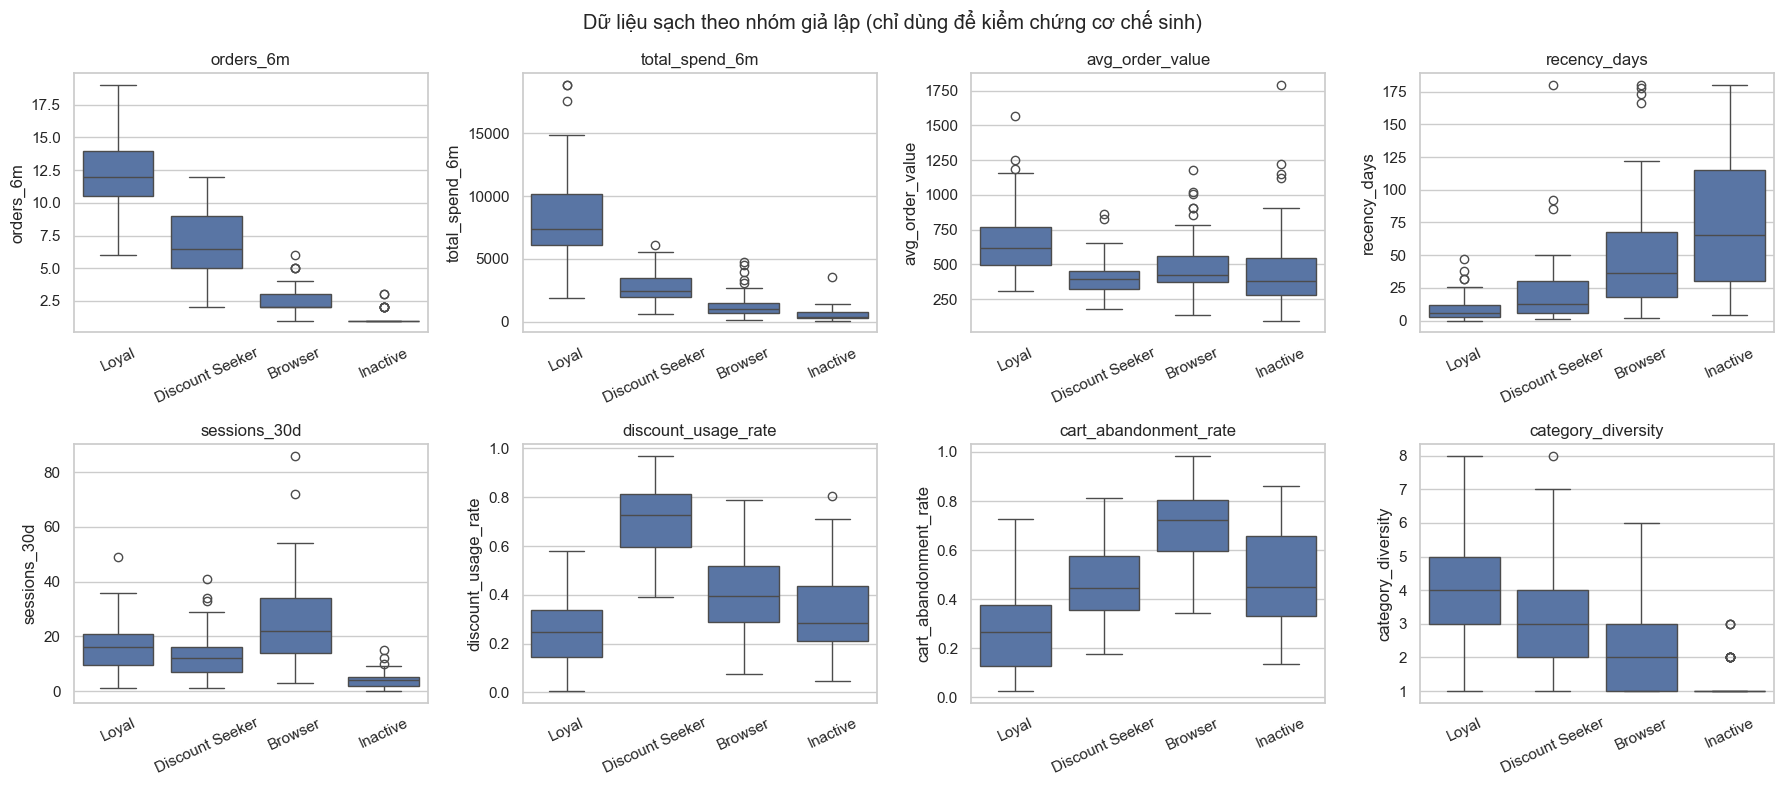

In [8]:
plot_features = [
    "orders_6m", "total_spend_6m", "avg_order_value", "recency_days",
    "sessions_30d", "discount_usage_rate", "cart_abandonment_rate", "category_diversity",
]
segment_order = list(SEGMENT_SIZES)

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.ravel(), plot_features):
    sns.boxplot(data=segment_view, x="true_segment", y=col, order=segment_order, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=25)
fig.suptitle("Dữ liệu sạch theo nhóm giả lập (chỉ dùng để kiểm chứng cơ chế sinh)")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "a_clean_features_by_segment.png", dpi=150)
plt.show()

Để đánh giá định lượng mức giao thoa, tính silhouette của **nhãn giả lập** trên 10 thuộc tính số đã chuẩn hóa. Giá trị gần 1 cho thấy các nhóm tách biệt rõ, tức dữ liệu quá dễ phân cụm. Giá trị gần 0 cho thấy các nhóm chồng lấn mạnh. Chỉ số này chỉ dùng để mô tả dữ liệu giả lập.

In [9]:
scaled_clean_numeric = StandardScaler().fit_transform(customers_original[NUMERIC_FEATURES])
true_label_silhouette = silhouette_score(scaled_clean_numeric, segment_view["true_segment"])
print(f"Silhouette of simulated segments (clean, standardized numeric features): {true_label_silhouette:.3f}")

Silhouette of simulated segments (clean, standardized numeric features): 0.177


**Nhận xét.** Trung bình theo nhóm thay đổi theo đúng hướng đã thiết kế:

- Loyal có số đơn (12.36), chi tiêu (8333.57) và giá trị đơn (681.00) cao nhất, recency thấp nhất (9.71 ngày).
- Discount Seeker có `discount_usage_rate` cao nhất (0.71).
- Browser có số phiên cao nhất (25.45) nhưng chỉ 2.51 đơn, và tỷ lệ bỏ giỏ cao nhất (0.70).
- Inactive có số phiên (4.00) và số đơn (1.20) thấp nhất, recency cao nhất (80.86 ngày).

Biểu đồ hộp cho thấy nhiều biến chồng lấn đáng kể giữa các nhóm, đặc biệt `avg_order_value`, `return_rate` và `sessions_30d` giữa Loyal và Discount Seeker. Silhouette của nhãn giả lập là 0.177, tức các nhóm có cấu trúc nhưng không tách biệt rõ. Mức này phù hợp yêu cầu tránh dữ liệu quá dễ phân cụm.

### a.3. Đưa vào các vấn đề chất lượng dữ liệu

Thứ tự can thiệp trên bản sao `customers_corrupted`:

1. **Chọn bản ghi ngoại lai trước** (12 `customer_id`), sau đó loại các bản ghi này khỏi tập ứng viên của nhiễu và giá trị thiếu. Mỗi bản ghi ngoại lai vì thế chỉ chịu đúng một loại can thiệp, nên việc đối chiếu và đánh giá khả năng phát hiện không bị lẫn.
2. **Thêm nhiễu Gaussian** vào `total_spend_6m` và `sessions_30d`.
3. **Áp dụng ngoại lai.**
4. **Tạo giá trị thiếu** cho `avg_order_value` (MCAR) và `cart_abandonment_rate` (MAR).

Mọi can thiệp được ghi vào `simulation_metadata`.

#### Nhiễu Gaussian

Độ lớn nhiễu được chọn theo thang đo và dạng phân phối của từng biến:

- `total_spend_6m` lệch phải mạnh (từ vài trăm đến hàng chục nghìn). Một độ lệch chuẩn tuyệt đối chung sẽ làm khách chi tiêu thấp bị biến dạng rất mạnh, thậm chí ra giá trị âm. Vì vậy dùng nhiễu Gaussian **tương đối**: `x' = x · (1 + ε)`, với ε ~ N(0, 0.15²). Độ lệch chuẩn tuyệt đối của nhiễu tỷ lệ với giá trị gốc, tương ứng sai số ghi nhận hoặc quy đổi doanh thu.
- `sessions_30d` có thang đo hẹp: dùng nhiễu cộng `x' = x + ε`, với ε ~ N(0, (0.25 · σ_sessions)²), trong đó σ_sessions là độ lệch chuẩn của biến trên dữ liệu sạch. Kết quả làm tròn về số nguyên và cắt dưới tại 0 vì đây là biến đếm.

Mỗi biến được thêm nhiễu trên 40% số bản ghi. Các bản ghi được chọn ngẫu nhiên, độc lập giữa hai biến.

In [10]:
OUTLIER_BUSINESS_COUNT = 5
OUTLIER_ERROR_COUNT = 7
NOISE_FRACTION = 0.40
SPEND_RELATIVE_NOISE_SD = 0.15
SESSIONS_NOISE_SD_RATIO = 0.25
MISSING_AOV_RATE = 0.07    # MCAR
MISSING_CART_RATE = 0.08   # MAR theo sessions_30d


def select_outlier_ids(segment_labels, rng):
    # Ngoại lai nghiệp vụ lấy từ nhóm Loyal (khách VIP có thật); ngoại lai lỗi lấy ngẫu nhiên từ phần còn lại.
    loyal_ids = segment_labels.loc[segment_labels["true_segment"] == "Loyal", "customer_id"].to_numpy()
    business_ids = rng.choice(loyal_ids, OUTLIER_BUSINESS_COUNT, replace=False)
    remaining_ids = np.setdiff1d(segment_labels["customer_id"].to_numpy(), business_ids)
    error_ids = rng.choice(remaining_ids, OUTLIER_ERROR_COUNT, replace=False)
    return list(business_ids), list(error_ids)


def add_gaussian_noise(df, eligible_ids, rng):
    # Trả về bản dữ liệu đã thêm nhiễu và bảng log nhiễu theo từng bản ghi.
    noisy = df.copy()
    n_noisy = round(NOISE_FRACTION * len(df))
    logs = []

    spend_ids = rng.choice(eligible_ids, n_noisy, replace=False)
    mask = noisy["customer_id"].isin(spend_ids)
    before = noisy.loc[mask, "total_spend_6m"]
    epsilon = rng.normal(0, SPEND_RELATIVE_NOISE_SD, mask.sum())
    noisy.loc[mask, "total_spend_6m"] = np.maximum(before * (1 + epsilon), 0).round(2)
    logs.append(pd.DataFrame({"customer_id": noisy.loc[mask, "customer_id"], "column": "total_spend_6m",
                              "before": before, "after": noisy.loc[mask, "total_spend_6m"]}))

    sessions_sd = SESSIONS_NOISE_SD_RATIO * df["sessions_30d"].std()
    session_ids = rng.choice(eligible_ids, n_noisy, replace=False)
    mask = noisy["customer_id"].isin(session_ids)
    before = noisy.loc[mask, "sessions_30d"]
    noisy_values = np.maximum(np.round(before + rng.normal(0, sessions_sd, mask.sum())), 0)
    noisy.loc[mask, "sessions_30d"] = noisy_values.astype(int)
    logs.append(pd.DataFrame({"customer_id": noisy.loc[mask, "customer_id"], "column": "sessions_30d",
                              "before": before, "after": noisy.loc[mask, "sessions_30d"]}))

    noise_log = pd.concat(logs, ignore_index=True)
    noise_log["delta"] = noise_log["after"] - noise_log["before"]
    noise_params = {"total_spend_6m": f"relative N(0, {SPEND_RELATIVE_NOISE_SD}^2)",
                    "sessions_30d": f"additive N(0, {sessions_sd:.3f}^2)",
                    "sessions_30d_sd": sessions_sd}
    return noisy, noise_log, noise_params

#### Ngoại lai

Chọn 12 `customer_id` khác nhau (nhiều hơn mức tối thiểu 11):

- **5 ngoại lai hợp lệ về nghiệp vụ**, lấy từ nhóm Loyal. Giá trị vẫn tuân thủ các ràng buộc logic, ví dụ `total_spend_6m = orders_6m × avg_order_value` vẫn đúng:
  - 3 khách VIP chi tiêu lớn: `avg_order_value` nhân 4–6 lần.
  - 2 khách mua rất thường xuyên: 60–80 đơn trong 6 tháng, 60–90 phiên truy cập, recency 0–2 ngày.
- **7 ngoại lai do lỗi dữ liệu**, mỗi bản ghi vi phạm một ràng buộc:
  - 2 bản ghi lỗi đơn vị: `total_spend_6m` × 100.
  - 1 bản ghi lỗi tracking: `sessions_30d` = 999.
  - 1 bản ghi tỷ lệ vượt khoảng hợp lệ: `return_rate` = 1.85.
  - 1 bản ghi tỷ lệ âm: `discount_usage_rate` = −0.40.
  - 1 bản ghi giá trị âm: `tenure_months` = −12.
  - 1 bản ghi giá trị âm: `recency_days` = −15.

In [11]:
ERROR_RULES = [
    ("spend_unit_x100", "total_spend_6m"),
    ("spend_unit_x100", "total_spend_6m"),
    ("sessions_tracking_999", "sessions_30d"),
    ("return_rate_above_1", "return_rate"),
    ("discount_rate_negative", "discount_usage_rate"),
    ("tenure_negative", "tenure_months"),
    ("recency_negative", "recency_days"),
]


def apply_business_outliers(df, business_ids, rng):
    records = []
    for i, cid in enumerate(business_ids):
        idx = df.index[df["customer_id"] == cid][0]
        if i < 3:
            rule = "vip_high_order_value"
            df.loc[idx, "avg_order_value"] = round(df.loc[idx, "avg_order_value"] * rng.uniform(4, 6), 2)
            columns = ["avg_order_value", "total_spend_6m"]
        else:
            rule = "very_high_frequency"
            df.loc[idx, "orders_6m"] = rng.integers(60, 81)
            df.loc[idx, "sessions_30d"] = rng.integers(60, 91)
            df.loc[idx, "recency_days"] = rng.integers(0, 3)
            columns = ["orders_6m", "sessions_30d", "recency_days", "total_spend_6m"]
        # Giữ đúng định nghĩa tổng chi tiêu để ngoại lai vẫn hợp lệ về nghiệp vụ.
        df.loc[idx, "total_spend_6m"] = round(df.loc[idx, "orders_6m"] * df.loc[idx, "avg_order_value"], 2)
        records.append({"customer_id": cid, "outlier_type": "business_valid",
                        "outlier_rule": rule, "outlier_columns": ";".join(columns)})
    return records


def apply_error_outliers(df, error_ids):
    records = []
    for cid, (rule, column) in zip(error_ids, ERROR_RULES):
        idx = df.index[df["customer_id"] == cid][0]
        if rule == "spend_unit_x100":
            df.loc[idx, column] = round(df.loc[idx, column] * 100, 2)
        else:
            df.loc[idx, column] = {"sessions_tracking_999": 999, "return_rate_above_1": 1.85,
                                   "discount_rate_negative": -0.40, "tenure_negative": -12,
                                   "recency_negative": -15}[rule]
        records.append({"customer_id": cid, "outlier_type": "data_error",
                        "outlier_rule": rule, "outlier_columns": column})
    return records

#### Giá trị thiếu

- `avg_order_value`, **MCAR**: chọn ngẫu nhiên đều 7% số bản ghi (15 bản ghi). Việc thiếu không phụ thuộc vào bất kỳ giá trị nào.
- `cart_abandonment_rate`, **MAR**: 8% số bản ghi (18 bản ghi). Xác suất thiếu tỷ lệ với exp(−sessions_30d / 10), trong đó `sessions_30d` là giá trị quan sát được sau nhiễu. Giả định: khách ít truy cập có ít sự kiện giỏ hàng nên tỷ lệ bỏ giỏ khó được ghi nhận. Cơ chế thiếu phụ thuộc vào một biến quan sát được, không phụ thuộc vào chính giá trị bị thiếu hay nhãn nhóm.

In [12]:
def add_missing_values(df, eligible_ids, rng):
    eligible_mask = df["customer_id"].isin(eligible_ids)
    eligible = df.loc[eligible_mask]

    n_aov = round(MISSING_AOV_RATE * len(df))
    aov_ids = rng.choice(eligible["customer_id"].to_numpy(), n_aov, replace=False)

    n_cart = round(MISSING_CART_RATE * len(df))
    weights = np.exp(-eligible["sessions_30d"].to_numpy() / 10)
    cart_ids = rng.choice(eligible["customer_id"].to_numpy(), n_cart, replace=False, p=weights / weights.sum())

    df.loc[df["customer_id"].isin(aov_ids), "avg_order_value"] = np.nan
    df.loc[df["customer_id"].isin(cart_ids), "cart_abandonment_rate"] = np.nan
    return set(aov_ids), set(cart_ids)

In [13]:
business_ids, error_ids = select_outlier_ids(segment_labels, rng)
outlier_ids = business_ids + error_ids
non_outlier_ids = np.setdiff1d(customers_original["customer_id"].to_numpy(), outlier_ids)

customers_corrupted, noise_log, noise_params = add_gaussian_noise(customers_original, non_outlier_ids, rng)
outlier_records = apply_business_outliers(customers_corrupted, business_ids, rng)
outlier_records += apply_error_outliers(customers_corrupted, error_ids)
missing_aov_ids, missing_cart_ids = add_missing_values(customers_corrupted, non_outlier_ids, rng)

print("Noise parameters:", noise_params)
print("Outlier ids:", outlier_ids)

Noise parameters: {'total_spend_6m': 'relative N(0, 0.15^2)', 'sessions_30d': 'additive N(0, 3.219^2)', 'sessions_30d_sd': np.float64(3.218779861081748)}
Outlier ids: ['C0197', 'C0129', 'C0118', 'C0077', 'C0133', 'C0143', 'C0146', 'C0137', 'C0127', 'C0013', 'C0192', 'C0131']


In [14]:
def build_simulation_metadata():
    meta = segment_labels.copy()
    for column, flag in [("total_spend_6m", "noise_total_spend"), ("sessions_30d", "noise_sessions")]:
        deltas = noise_log.loc[noise_log["column"] == column].set_index("customer_id")["delta"]
        meta[flag] = meta["customer_id"].isin(deltas.index)
        meta[f"{flag}_delta"] = meta["customer_id"].map(deltas).fillna(0.0)

    outlier_table = pd.DataFrame(outlier_records)
    meta = meta.merge(outlier_table, on="customer_id", how="left")
    meta["is_outlier"] = meta["outlier_type"].notna()
    meta[["outlier_type", "outlier_rule", "outlier_columns"]] = (
        meta[["outlier_type", "outlier_rule", "outlier_columns"]].fillna("none"))

    meta["missing_avg_order_value"] = meta["customer_id"].isin(missing_aov_ids)
    meta["missing_cart_abandonment_rate"] = meta["customer_id"].isin(missing_cart_ids)

    def error_types(row):
        types = []
        if row["missing_avg_order_value"] or row["missing_cart_abandonment_rate"]:
            types.append("missing")
        if row["noise_total_spend"] or row["noise_sessions"]:
            types.append("noise")
        if row["is_outlier"]:
            types.append(f"outlier_{row['outlier_type']}")
        return ";".join(types) if types else "clean"

    meta["error_types"] = meta.apply(error_types, axis=1)
    return meta


simulation_metadata = build_simulation_metadata()
print(simulation_metadata["error_types"].value_counts().to_string())
simulation_metadata.head()

error_types
noise                     118
clean                      59
missing;noise              20
missing                    11
outlier_data_error          7
outlier_business_valid      5


,customer_id,true_segment,noise_total_spend,noise_total_spend_delta,noise_sessions,noise_sessions_delta,outlier_type,outlier_rule,outlier_columns,is_outlier,missing_avg_order_value,missing_cart_abandonment_rate,error_types
0,C0001,Discount Seeker,False,0.00,False,0.0,none,none,none,False,True,True,missing
1,C0002,Loyal,False,0.00,False,0.0,none,none,none,False,False,False,clean
2,C0003,Browser,True,-13.75,True,0.0,none,none,none,False,False,False,noise
3,C0004,Loyal,True,-632.60,True,-1.0,none,none,none,False,False,False,noise
4,C0005,Loyal,False,0.00,True,-4.0,none,none,none,False,False,False,noise


Kiểm tra cơ chế thiếu: với MCAR, `sessions_30d` của nhóm thiếu và không thiếu `avg_order_value` không nên khác nhau có hệ thống. Với MAR, nhóm thiếu `cart_abandonment_rate` dự kiến có `sessions_30d` thấp hơn.

In [15]:
missing_mechanism_check = pd.DataFrame({
    column: customers_corrupted.groupby(customers_corrupted[column].isna())["sessions_30d"].median()
    for column in ["avg_order_value", "cart_abandonment_rate"]
}).rename(index={False: "observed", True: "missing"})
missing_mechanism_check.index.name = "median sessions_30d when value is"
missing_mechanism_check

,avg_order_value,cart_abandonment_rate
median sessions_30d when value is,,
observed,12.0,13.5
missing,11.0,4.5


**Nhận xét.**

- `avg_order_value` (MCAR): median `sessions_30d` của nhóm thiếu và nhóm quan sát được gần nhau (11 so với 12).
- `cart_abandonment_rate` (MAR): median `sessions_30d` của nhóm thiếu chỉ là 4.5, so với 13.5 ở nhóm quan sát được. Như vậy cơ chế thiếu phụ thuộc vào một biến quan sát được, đúng thiết kế.

Hệ quả cho tiền xử lý: điền `cart_abandonment_rate` bằng trung vị toàn cục có thể lệch, vì các bản ghi thiếu tập trung ở khách ít truy cập. Cần cân nhắc phương pháp điền có sử dụng biến quan sát khác.

Về phân bố can thiệp: 59 bản ghi không bị can thiệp, 118 bản ghi chỉ có nhiễu, 11 bản ghi chỉ có giá trị thiếu, 20 bản ghi có cả nhiễu lẫn giá trị thiếu, và 12 bản ghi ngoại lai.

### a.4. Mức độ thay đổi do nhiễu và đối chiếu ngoại lai

In [16]:
noise_summary = noise_log.groupby("column").agg(
    n_records=("customer_id", "nunique"),
    mean_before=("before", "mean"),
    mean_after=("after", "mean"),
    mean_abs_delta=("delta", lambda d: d.abs().mean()),
    max_abs_delta=("delta", lambda d: d.abs().max()),
)
noise_summary["mean_abs_relative_change"] = noise_log.assign(
    rel=lambda t: (t["delta"] / t["before"].where(t["before"] != 0)).abs()
).groupby("column")["rel"].mean()
noise_summary["corr_before_after"] = noise_log.groupby("column")[["before", "after"]].apply(
    lambda t: t["before"].corr(t["after"]))
noise_summary["clean_std"] = [customers_original[c].std() for c in noise_summary.index]
noise_summary.round(3)

,n_records,mean_before,mean_after,mean_abs_delta,max_abs_delta,mean_abs_relative_change,corr_before_after,clean_std
column,,,,,,,,
sessions_30d,88,16.295,16.614,2.432,7.0,0.352,0.974,12.875
total_spend_6m,88,3366.682,3217.773,388.625,4528.8,0.100,0.982,3610.793


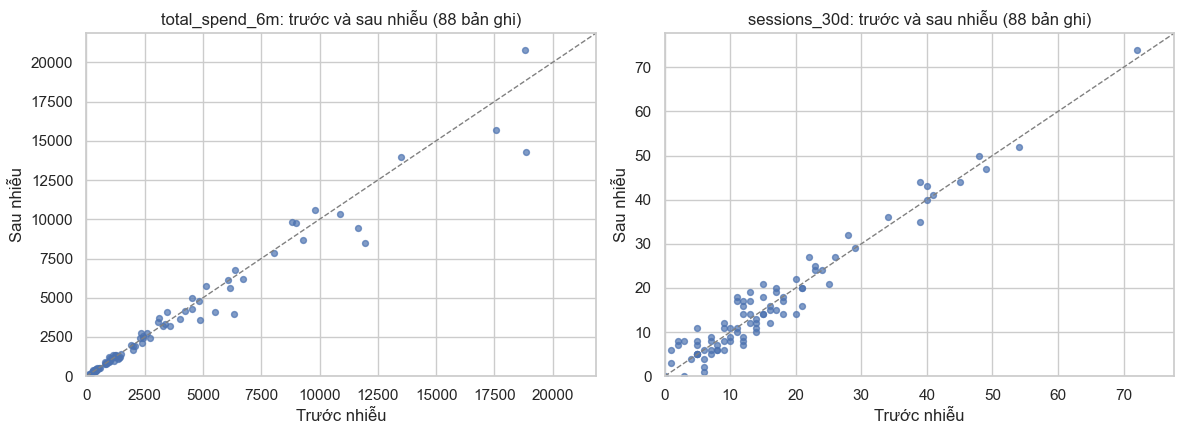

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, column in zip(axes, ["total_spend_6m", "sessions_30d"]):
    subset = noise_log[noise_log["column"] == column]
    ax.scatter(subset["before"], subset["after"], s=18, alpha=0.7)
    lim = [0, max(subset["before"].max(), subset["after"].max()) * 1.05]
    ax.plot(lim, lim, color="grey", linestyle="--", linewidth=1)
    ax.set_xlim(lim)
    ax.set_ylim(lim)
    ax.set_title(f"{column}: trước và sau nhiễu ({len(subset)} bản ghi)")
    ax.set_xlabel("Trước nhiễu")
    ax.set_ylabel("Sau nhiễu")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "a_noise_before_after.png", dpi=150)
plt.show()

**Nhận xét.** Mỗi biến có 88 bản ghi bị tác động (40%):

- `total_spend_6m`: thay đổi tương đối trung bình khoảng 10%, tương quan trước/sau là 0.982. Độ lệch tuyệt đối lớn nhất (khoảng 4529) rơi vào khách chi tiêu cao, đúng với tính chất nhiễu tương đối.
- `sessions_30d`: thay đổi tuyệt đối trung bình 2.43 phiên. Thay đổi tương đối trung bình lên tới 35% vì nhiều khách chỉ có vài phiên. Có 74/88 bản ghi thực sự đổi giá trị; số còn lại có nhiễu bị làm tròn về 0 hoặc bị cắt tại 0.

Nhiễu làm giảm tính nhất quán `total_spend_6m = orders_6m × avg_order_value` ở các bản ghi bị tác động, nhưng chưa tạo ra giá trị cực đoan.

In [18]:
def outlier_comparison_table():
    rows = []
    for record in outlier_records:
        cid = record["customer_id"]
        for column in record["outlier_columns"].split(";"):
            rows.append({
                "customer_id": cid,
                "outlier_type": record["outlier_type"],
                "outlier_rule": record["outlier_rule"],
                "column": column,
                "original_value": customers_original.loc[customers_original["customer_id"] == cid, column].iloc[0],
                "corrupted_value": customers_corrupted.loc[customers_corrupted["customer_id"] == cid, column].iloc[0],
            })
    return pd.DataFrame(rows)


outlier_comparison = outlier_comparison_table()
outlier_comparison

,customer_id,outlier_type,outlier_rule,column,original_value,corrupted_value
0,C0197,business_valid,vip_high_order_value,avg_order_value,482.190,2803.41
1,C0197,business_valid,vip_high_order_value,total_spend_6m,6750.660,39247.74
2,C0129,business_valid,vip_high_order_value,avg_order_value,601.020,3027.50
3,C0129,business_valid,vip_high_order_value,total_spend_6m,7212.240,36330.00
4,C0118,business_valid,vip_high_order_value,avg_order_value,1084.070,6064.05
5,C0118,business_valid,vip_high_order_value,total_spend_6m,10840.700,60640.50
6,C0077,business_valid,very_high_frequency,orders_6m,12.000,63.00
7,C0077,business_valid,very_high_frequency,sessions_30d,14.000,85.00
8,C0077,business_valid,very_high_frequency,recency_days,5.000,2.00
9,C0077,business_valid,very_high_frequency,total_spend_6m,8778.240,46085.76


**Nhận xét.** 12 `customer_id` đã được can thiệp đúng như thiết kế.

- **Ngoại lai nghiệp vụ** có `total_spend_6m` từ khoảng 36 nghìn đến 80 nghìn, trong khi giá trị lớn nhất ở dữ liệu sạch là 18834.70. Chúng vẫn thỏa mọi ràng buộc logic, nên chỉ phương pháp thống kê (IQR, z-score, …) mới phát hiện được.
- **Ngoại lai lỗi** chia làm hai loại:
  - 4 bản ghi vi phạm miền giá trị (âm hoặc tỷ lệ > 1): có thể phát hiện bằng kiểm tra quy tắc nghiệp vụ.
  - 3 bản ghi có giá trị cực lớn (`total_spend_6m` × 100, `sessions_30d` = 999): vẫn hợp lệ về miền nhưng lệch rất xa phân phối.

Phần lớn ngoại lai lỗi chỉ lệch ở một cột, trong khi các cột còn lại bình thường. Do đó nếu chỉ kiểm tra từng biến riêng lẻ theo một phương pháp thống kê, một số bản ghi có thể không bị phát hiện. Khả năng phát hiện sẽ được đánh giá định lượng ở câu b.

### a.5. Kiểm tra tự động và lưu dữ liệu

In [19]:
def run_simulation_checks(original, corrupted, metadata):
    results = {}

    results["original_records"] = len(original)
    results["corrupted_records"] = len(corrupted)
    results["input_features"] = len([c for c in original.columns if c != "customer_id"])
    assert results["original_records"] == N_CUSTOMERS and results["corrupted_records"] == N_CUSTOMERS
    assert results["input_features"] == N_INPUT_FEATURES
    assert list(original.columns) == list(corrupted.columns)

    # Đối chiếu bằng customer_id: cùng tập id, không trùng lặp, cùng thứ tự.
    assert original["customer_id"].is_unique and corrupted["customer_id"].is_unique
    assert set(original["customer_id"]) == set(corrupted["customer_id"]) == set(metadata["customer_id"])
    assert (original["customer_id"].to_numpy() == corrupted["customer_id"].to_numpy()).all()

    assert original[INPUT_FEATURES].notna().all().all()
    missing_rate = corrupted[INPUT_FEATURES].isna().mean()
    missing_columns = missing_rate[missing_rate > 0]
    assert len(missing_columns) >= 2
    assert missing_columns.between(0.05, 0.10).all()
    results.update({f"missing_rate_{c}": round(r, 4) for c, r in missing_columns.items()})

    original_idx = original.set_index("customer_id")
    corrupted_idx = corrupted.set_index("customer_id")
    noisy_columns = []
    for column, flag in [("total_spend_6m", "noise_total_spend"), ("sessions_30d", "noise_sessions")]:
        noise_ids = metadata.loc[metadata[flag], "customer_id"]
        assert pd.api.types.is_numeric_dtype(corrupted[column])
        changed = (corrupted_idx.loc[noise_ids, column] != original_idx.loc[noise_ids, column]).sum()
        results[f"noise_records_{column}"] = len(noise_ids)
        results[f"noise_records_changed_{column}"] = int(changed)
        if changed > 0:
            noisy_columns.append(column)
    assert len(noisy_columns) >= 2

    outlier_meta = metadata[metadata["is_outlier"]]
    results["outlier_ids"] = outlier_meta["customer_id"].nunique()
    results["outlier_business_valid"] = int((outlier_meta["outlier_type"] == "business_valid").sum())
    results["outlier_data_error"] = int((outlier_meta["outlier_type"] == "data_error").sum())
    assert results["outlier_ids"] >= MIN_OUTLIER_IDS
    for _, row in outlier_meta.iterrows():
        for column in row["outlier_columns"].split(";"):
            assert original_idx.loc[row["customer_id"], column] != corrupted_idx.loc[row["customer_id"], column]

    # Bản ghi ngoại lai không chịu thêm nhiễu hay giá trị thiếu.
    other_flags = ["noise_total_spend", "noise_sessions", "missing_avg_order_value", "missing_cart_abandonment_rate"]
    assert not outlier_meta[other_flags].any().any()

    # Bản ghi không bị can thiệp phải giữ nguyên giá trị.
    clean_ids = metadata.loc[metadata["error_types"] == "clean", "customer_id"]
    assert original_idx.loc[clean_ids, INPUT_FEATURES].equals(corrupted_idx.loc[clean_ids, INPUT_FEATURES])
    results["untouched_records"] = len(clean_ids)

    assert "true_segment" not in corrupted.columns and "true_segment" not in original.columns
    return pd.Series(results, name="value", dtype=object).to_frame()


simulation_checks = run_simulation_checks(customers_original, customers_corrupted, simulation_metadata)
simulation_checks

,value
original_records,220
corrupted_records,220
input_features,12
missing_rate_avg_order_value,0.0682
missing_rate_cart_abandonment_rate,0.0818
noise_records_total_spend_6m,88
noise_records_changed_total_spend_6m,88
noise_records_sessions_30d,88
noise_records_changed_sessions_30d,74
outlier_ids,12


In [20]:
original_path = DATA_DIR / "customers_original.csv"
corrupted_path = DATA_DIR / "customers_corrupted.csv"
metadata_path = METADATA_DIR / "simulation_metadata.csv"

customers_original.to_csv(original_path, index=False)
customers_corrupted.to_csv(corrupted_path, index=False)
simulation_metadata.to_csv(metadata_path, index=False)

# Đọc lại từ đĩa để chắc chắn tệp lưu đúng và vẫn đối chiếu được.
reloaded_original = pd.read_csv(original_path)
reloaded_corrupted = pd.read_csv(corrupted_path)
reloaded_metadata = pd.read_csv(metadata_path)
run_simulation_checks(reloaded_original, reloaded_corrupted, reloaded_metadata)
for path in [original_path, corrupted_path, metadata_path]:
    print(f"Saved {path.relative_to(PROJECT_DIR)} ({path.stat().st_size} bytes)")

Saved data\customers_original.csv (16633 bytes)
Saved data\customers_corrupted.csv (16472 bytes)
Saved metadata\simulation_metadata.csv (18802 bytes)


### a.6. Giả định và hạn chế của dữ liệu giả lập

- **Phân bố do người thiết kế chọn.** Bốn nhóm và tham số phân phối dựa trên giả định hợp lý về hành vi mua sắm, không ước lượng từ dữ liệu thực. Cấu trúc cụm "đúng" vì vậy phản ánh giả định của mô phỏng.
- **Số nhóm cố định là 4**, kích thước gần cân bằng (50–60 khách). Dữ liệu thực thường mất cân bằng hơn, ví dụ khách không hoạt động chiếm đa số.
- **Quan hệ giữa các biến được đơn giản hóa**: tổng chi tiêu là tích chính xác của số đơn và giá trị đơn trung bình; recency chỉ phụ thuộc vào số đơn và hệ số nhóm; các tỷ lệ là xu hướng liên tục, độc lập với nhau khi đã biết nhóm.
- **Tập khách chỉ gồm khách có ít nhất 1 đơn trong 6 tháng**, nên không mô hình hóa khách đã rời bỏ hoàn toàn.
- **Biến phân loại phụ thuộc yếu vào nhóm**. Chúng chủ yếu hỗ trợ diễn giải cụm, khả năng phân biệt nhóm thấp.
- **Mẫu nhỏ (220 bản ghi)**: thống kê theo nhóm có phương sai lớn, kết quả có thể thay đổi đáng kể với seed khác.
- **Lỗi dữ liệu được tạo có chủ đích và tách bạch**: mỗi ngoại lai chỉ có một loại lỗi, không chồng với nhiễu hay giá trị thiếu. Trong dữ liệu thực, các loại lỗi thường đan xen và không có metadata để đối chiếu.
- **Cơ chế MAR cho `cart_abandonment_rate` dựa trên `sessions_30d` sau nhiễu**: giả định này hợp lý về nghiệp vụ nhưng chưa được kiểm chứng trên dữ liệu thực.

## Câu b — Data Understanding

EDA được thực hiện trên `customers_corrupted.csv`, đọc lại từ đĩa. Đây là dữ liệu mà người phân tích có trong thực tế. Dữ liệu sạch và metadata chỉ được dùng ở hai chỗ, đều ghi rõ:

1. Mục b.8: so sánh thống kê trước và sau khi đưa vào lỗi.
2. Mục b.7: đánh giá khả năng phát hiện các ngoại lai đã chủ động tạo.

Các quyết định tiền xử lý ở câu c chỉ dựa trên những gì quan sát được từ dữ liệu corrupted.

### b.1. Kích thước, kiểu dữ liệu và trùng lặp

In [21]:
eda_df = pd.read_csv(DATA_DIR / "customers_corrupted.csv")

print("Shape:", eda_df.shape)
print("Duplicated customer_id:", eda_df["customer_id"].duplicated().sum())
print("Duplicated rows (all columns):", eda_df.duplicated().sum())
print("Duplicated rows (input features only):", eda_df[INPUT_FEATURES].duplicated().sum())
eda_df.dtypes.rename("dtype").to_frame().T

Shape: (220, 13)
Duplicated customer_id: 0
Duplicated rows (all columns): 0
Duplicated rows (input features only): 0


,customer_id,tenure_months,recency_days,orders_6m,total_spend_6m,avg_order_value,sessions_30d,discount_usage_rate,return_rate,category_diversity,cart_abandonment_rate,favorite_category,preferred_device
dtype,object,int64,int64,int64,float64,float64,int64,float64,float64,int64,float64,object,object


**Nhận xét.** Dữ liệu có 220 bản ghi và 13 cột (`customer_id` cùng 12 thuộc tính). Không có `customer_id` trùng lặp, cũng không có bản ghi trùng hoàn toàn, kể cả khi bỏ qua `customer_id`. Các biến đếm vẫn ở kiểu `int64`, nên kiểu dữ liệu không phát hiện được giá trị âm. Hai biến có giá trị thiếu là `float64`. Hai biến phân loại là `object`.

### b.2. Thống kê mô tả thuộc tính số

In [22]:
numeric_summary = eda_df[NUMERIC_FEATURES].describe().T
numeric_summary["skewness"] = eda_df[NUMERIC_FEATURES].skew()
numeric_summary["max_to_median"] = numeric_summary["max"] / numeric_summary["50%"]
numeric_summary.round(3)

,count,mean,std,min,25%,50%,75%,max,skewness,max_to_median
tenure_months,220.0,24.568,14.414,-12.000,14.000,24.000,36.000,66.000,0.072,2.750
recency_days,220.0,39.014,48.339,-15.000,7.000,21.000,45.250,180.000,1.771,8.571
orders_6m,220.0,6.359,7.664,1.000,2.000,4.000,9.000,75.000,5.273,18.750
total_spend_6m,220.0,5216.698,13766.111,113.350,794.045,1938.810,4375.705,147995.000,7.099,76.333
avg_order_value,205.0,556.216,517.121,95.260,360.490,435.650,620.470,6064.050,7.008,13.920
sessions_30d,220.0,20.118,67.841,0.000,6.000,12.000,21.000,999.000,13.854,83.250
discount_usage_rate,220.0,0.427,0.246,-0.400,0.238,0.408,0.599,0.970,0.128,2.375
return_rate,220.0,0.131,0.147,0.002,0.055,0.100,0.170,1.850,7.516,18.500
category_diversity,220.0,2.727,1.775,1.000,1.000,2.000,4.000,8.000,1.063,4.000
cart_abandonment_rate,202.0,0.485,0.228,0.026,0.311,0.469,0.684,0.985,-0.048,2.100


**Nhận xét.**

- **Thang đo chênh lệch rất lớn.** Độ lệch chuẩn của `total_spend_6m` là 13766, trong khi `return_rate` chỉ có 0.147. Hai thang đo cách nhau khoảng 10⁵ lần.
- **Một số biến lệch phải mạnh.** Độ lệch (skewness) của `sessions_30d` là 13.85, `return_rate` 7.52, `total_spend_6m` 7.10, `avg_order_value` 7.01, `orders_6m` 5.27. Ở `total_spend_6m` và `sessions_30d`, giá trị lớn nhất gấp lần lượt 76 và 83 lần trung vị.
- **Có giá trị nằm ngoài miền hợp lệ.** Có `tenure_months` = −12, `recency_days` = −15, `discount_usage_rate` = −0.40 và `return_rate` = 1.85.
- **Trung vị ổn định hơn trung bình.** Trung vị của các biến vẫn ở mức hợp lý, ví dụ `sessions_30d` có trung vị 12 trong khi trung bình là 20.1. Điều này cho thấy mean và std đang bị một số ít giá trị cực đoan kéo lệch.

### b.3. Tần suất thuộc tính phân loại

In [23]:
for column in CATEGORICAL_FEATURES:
    frequency = pd.DataFrame({
        "count": eda_df[column].value_counts(),
        "ratio": eda_df[column].value_counts(normalize=True).round(3),
    })
    print(f"\n{column}\n{frequency.to_string()}")


favorite_category
                    count  ratio
favorite_category               
Electronics            55  0.250
Fashion                39  0.177
Home & Living          28  0.127
Sports & Outdoor       23  0.105
Groceries              23  0.105
Beauty & Health        22  0.100
Books & Stationery     17  0.077
Mother & Baby          13  0.059

preferred_device
                  count  ratio
preferred_device              
Mobile App          101  0.459
Mobile Web           65  0.295
Desktop              54  0.245


**Nhận xét.**

- `favorite_category` có 8 mức. Electronics phổ biến nhất (25.0%), Mother & Baby ít nhất (5.9%).
- `preferred_device` có 3 mức, Mobile App chiếm 45.9%.
- Không có mức nào quá hiếm (< 5%) và không có giá trị thiếu hay giá trị lạ.

Hai biến này là định danh, không có thứ tự. Nếu đưa vào K-Means, cần mã hóa riêng, ví dụ one-hot. Lựa chọn này được cân nhắc ở câu c.

### b.4. Giá trị thiếu

In [24]:
missing_table = pd.DataFrame({
    "missing_count": eda_df[INPUT_FEATURES].isna().sum(),
    "missing_ratio": eda_df[INPUT_FEATURES].isna().mean().round(4),
})
print(missing_table[missing_table["missing_count"] > 0])
print("Records with at least one missing value:", eda_df[INPUT_FEATURES].isna().any(axis=1).sum())
print("Records missing both columns:", eda_df[["avg_order_value", "cart_abandonment_rate"]].isna().all(axis=1).sum())

                       missing_count  missing_ratio
avg_order_value                   15         0.0682
cart_abandonment_rate             18         0.0818
Records with at least one missing value: 31
Records missing both columns: 2


Để xem giá trị thiếu có phụ thuộc vào các biến quan sát được hay không, so sánh trung vị của các biến khác giữa nhóm thiếu và nhóm có giá trị. Dùng trung vị để kết quả ít bị ngoại lai chi phối.

In [25]:
def compare_by_missing(df, missing_column, compare_columns):
    is_missing = df[missing_column].isna().map({False: "observed", True: "missing"})
    return df.groupby(is_missing)[compare_columns].median().T


compare_columns = ["sessions_30d", "orders_6m", "recency_days", "total_spend_6m", "tenure_months"]
for column in ["avg_order_value", "cart_abandonment_rate"]:
    print(f"\nMedian of other features by missingness of {column}")
    print(compare_by_missing(eda_df, column, compare_columns).round(2).to_string())


Median of other features by missingness of avg_order_value
avg_order_value  missing  observed
sessions_30d       11.00     12.00
orders_6m           2.00      5.00
recency_days       46.00     20.00
total_spend_6m    952.62   2014.65
tenure_months      23.00     24.00

Median of other features by missingness of cart_abandonment_rate
cart_abandonment_rate  missing  observed
sessions_30d              4.50     13.50
orders_6m                 1.50      5.00
recency_days             31.00     20.00
total_spend_6m          732.44   2048.44
tenure_months            23.50     24.00


**Nhận xét.** `avg_order_value` thiếu 15 giá trị (6.82%), `cart_abandonment_rate` thiếu 18 giá trị (8.18%). Tổng cộng 31 bản ghi (14.1%) thiếu ít nhất một giá trị, trong đó 2 bản ghi thiếu cả hai.

- **`cart_abandonment_rate`.** Bản ghi thiếu có số phiên thấp hơn rõ rệt (trung vị 4.5 so với 13.5) và số đơn thấp hơn (1.5 so với 5). Giá trị thiếu tập trung ở khách ít hoạt động, nên không thể coi là thiếu hoàn toàn ngẫu nhiên.
- **`avg_order_value`.** Số phiên gần như không khác (11 so với 12). Tuy vậy, nhóm thiếu có số đơn thấp hơn (2 so với 5) và recency cao hơn (46 so với 20). Theo thiết kế ở câu a, biến này thiếu theo cơ chế MCAR. Khác biệt quan sát được là biến động mẫu khi nhóm thiếu chỉ có 15 bản ghi. Điều này cho thấy với mẫu nhỏ, khó xác định cơ chế thiếu nếu chỉ dựa vào dữ liệu quan sát.

Trong cả hai trường hợp, xóa bản ghi thiếu sẽ làm mất 14.1% dữ liệu và loại đi nhiều khách ít hoạt động hơn mức trung bình.

### b.5. Phân bố và ngoại lai

Histogram của 10 thuộc tính số trên dữ liệu corrupted:

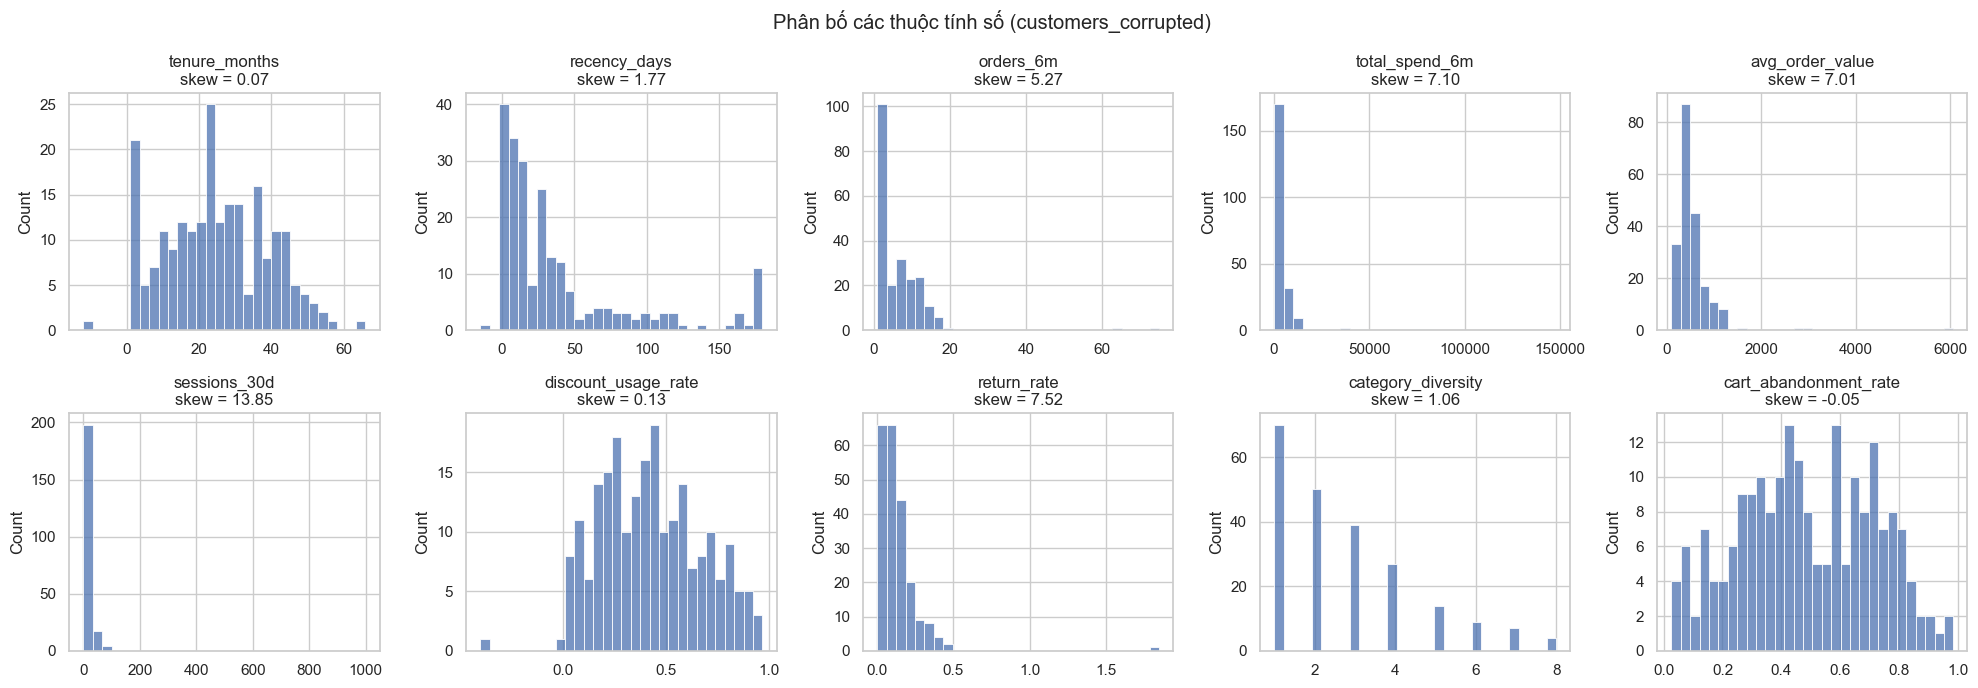

In [26]:
fig, axes = plt.subplots(2, 5, figsize=(20, 7))
for ax, column in zip(axes.ravel(), NUMERIC_FEATURES):
    sns.histplot(eda_df[column].dropna(), bins=30, ax=ax)
    ax.set_title(f"{column}\nskew = {eda_df[column].skew():.2f}")
    ax.set_xlabel("")
fig.suptitle("Phân bố các thuộc tính số (customers_corrupted)")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "b_histograms_corrupted.png", dpi=150)
plt.show()

Các giá trị cực lớn làm histogram của `total_spend_6m` và `sessions_30d` bị nén về một cột. Để xem hình dạng phân bố của phần dữ liệu còn lại, vẽ thêm hai biến này trên thang log, chỉ dùng các giá trị không âm.

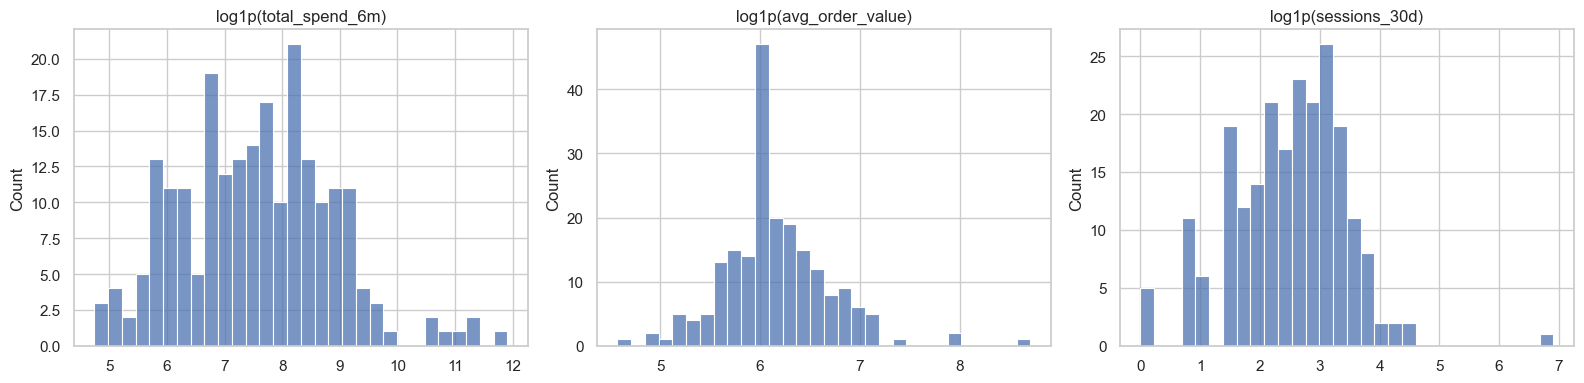

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, column in zip(axes, ["total_spend_6m", "avg_order_value", "sessions_30d"]):
    values = eda_df[column].dropna()
    sns.histplot(np.log1p(values[values >= 0]), bins=30, ax=ax)
    ax.set_title(f"log1p({column})")
    ax.set_xlabel("")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "b_log_histograms_corrupted.png", dpi=150)
plt.show()

**Nhận xét.**

- **Histogram gốc.**
  - `total_spend_6m`, `sessions_30d`, `avg_order_value` và `return_rate` bị một vài giá trị cực lớn kéo dài trục, nên phần lớn dữ liệu dồn vào vài cột đầu.
  - `recency_days` lệch phải, có một đỉnh nhỏ ở 180 ngày. Đây là giới hạn của cửa sổ quan sát 6 tháng chứ không phải lỗi.
  - `discount_usage_rate` và `cart_abandonment_rate` phân bố tương đối đối xứng.
  - `category_diversity` là biến rời rạc, lệch phải.
- **Sau biến đổi log1p.** `total_spend_6m` và `avg_order_value` có dạng gần đối xứng, với một ít điểm tách ra ở đuôi phải. `sessions_30d` vẫn còn một điểm cô lập ở khoảng 6.9 (log1p của 999). Như vậy, biến đổi log làm giảm độ lệch của phần lớn dữ liệu, nhưng không xử lý được giá trị lỗi.

Boxplot sau khi chuẩn hóa bằng **robust z-score**: (x − median) / IQR. Cách này đưa các biến về cùng đơn vị để so sánh mức độ ngoại lai giữa các biến. Median và IQR cũng không bị chính các ngoại lai làm lệch, khác với mean và std.

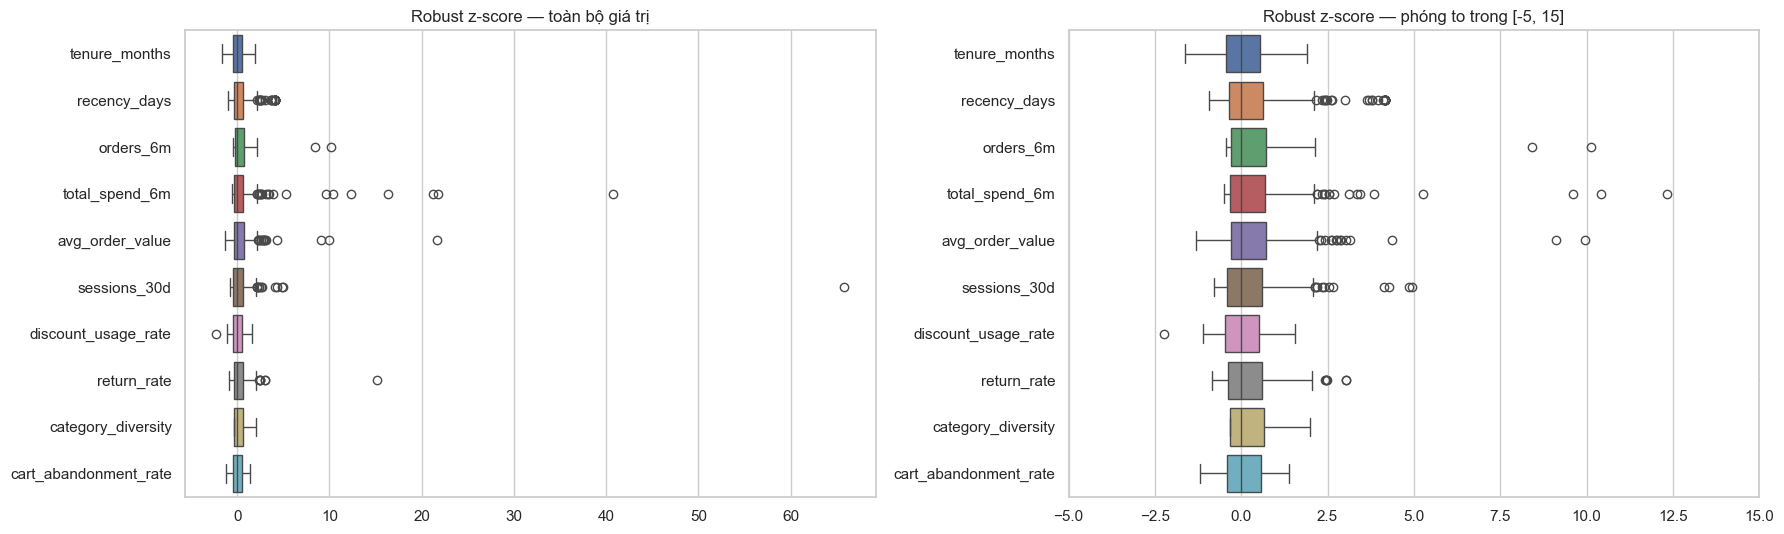

Max robust z-score per feature:
sessions_30d             65.8
total_spend_6m           40.8
avg_order_value          21.6
return_rate              15.2
orders_6m                10.1
recency_days              4.2
discount_usage_rate       2.2
category_diversity        2.0
tenure_months             1.9
cart_abandonment_rate     1.4


In [28]:
def robust_zscore(df):
    iqr = df.quantile(0.75) - df.quantile(0.25)
    return (df - df.median()) / iqr


robust_scaled = robust_zscore(eda_df[NUMERIC_FEATURES])
fig, axes = plt.subplots(1, 2, figsize=(18, 5.5))
for ax, (title, limit) in zip(axes, [("toàn bộ giá trị", None), ("phóng to trong [-5, 15]", (-5, 15))]):
    sns.boxplot(data=robust_scaled, orient="h", ax=ax)
    ax.set_title(f"Robust z-score — {title}")
    if limit:
        ax.set_xlim(limit)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "b_boxplot_robust_scaled.png", dpi=150)
plt.show()

print("Max robust z-score per feature:")
print(robust_scaled.abs().max().sort_values(ascending=False).round(1).to_string())

**Nhận xét.** Tính theo đơn vị IQR, điểm xa nhất của `sessions_30d` cách trung vị 65.8 IQR, `total_spend_6m` 40.8, `avg_order_value` 21.6, `return_rate` 15.2 và `orders_6m` 10.1. Các điểm này cách biệt hẳn với phần còn lại.

`recency_days` có nhiều điểm vượt râu trên nhưng chỉ tới 4.2 IQR. Phân bố của chúng liên tục chứ không tách thành điểm cô lập, phù hợp với đuôi tự nhiên của một biến lệch phải.

`tenure_months`, `category_diversity` và `cart_abandonment_rate` gần như không có điểm vượt râu. Giá trị âm của `tenure_months` (−12) nằm trong râu dưới, nên boxplot không làm nổi bật được nó.

### b.6. Tương quan giữa các thuộc tính số

So sánh hệ số Pearson (nhạy với ngoại lai, đo quan hệ tuyến tính) với Spearman (dựa trên thứ hạng, bền với ngoại lai). Nếu hai hệ số khác biệt lớn ở cùng một cặp biến, quan hệ đó đang bị ngoại lai hoặc phân bố lệch chi phối.

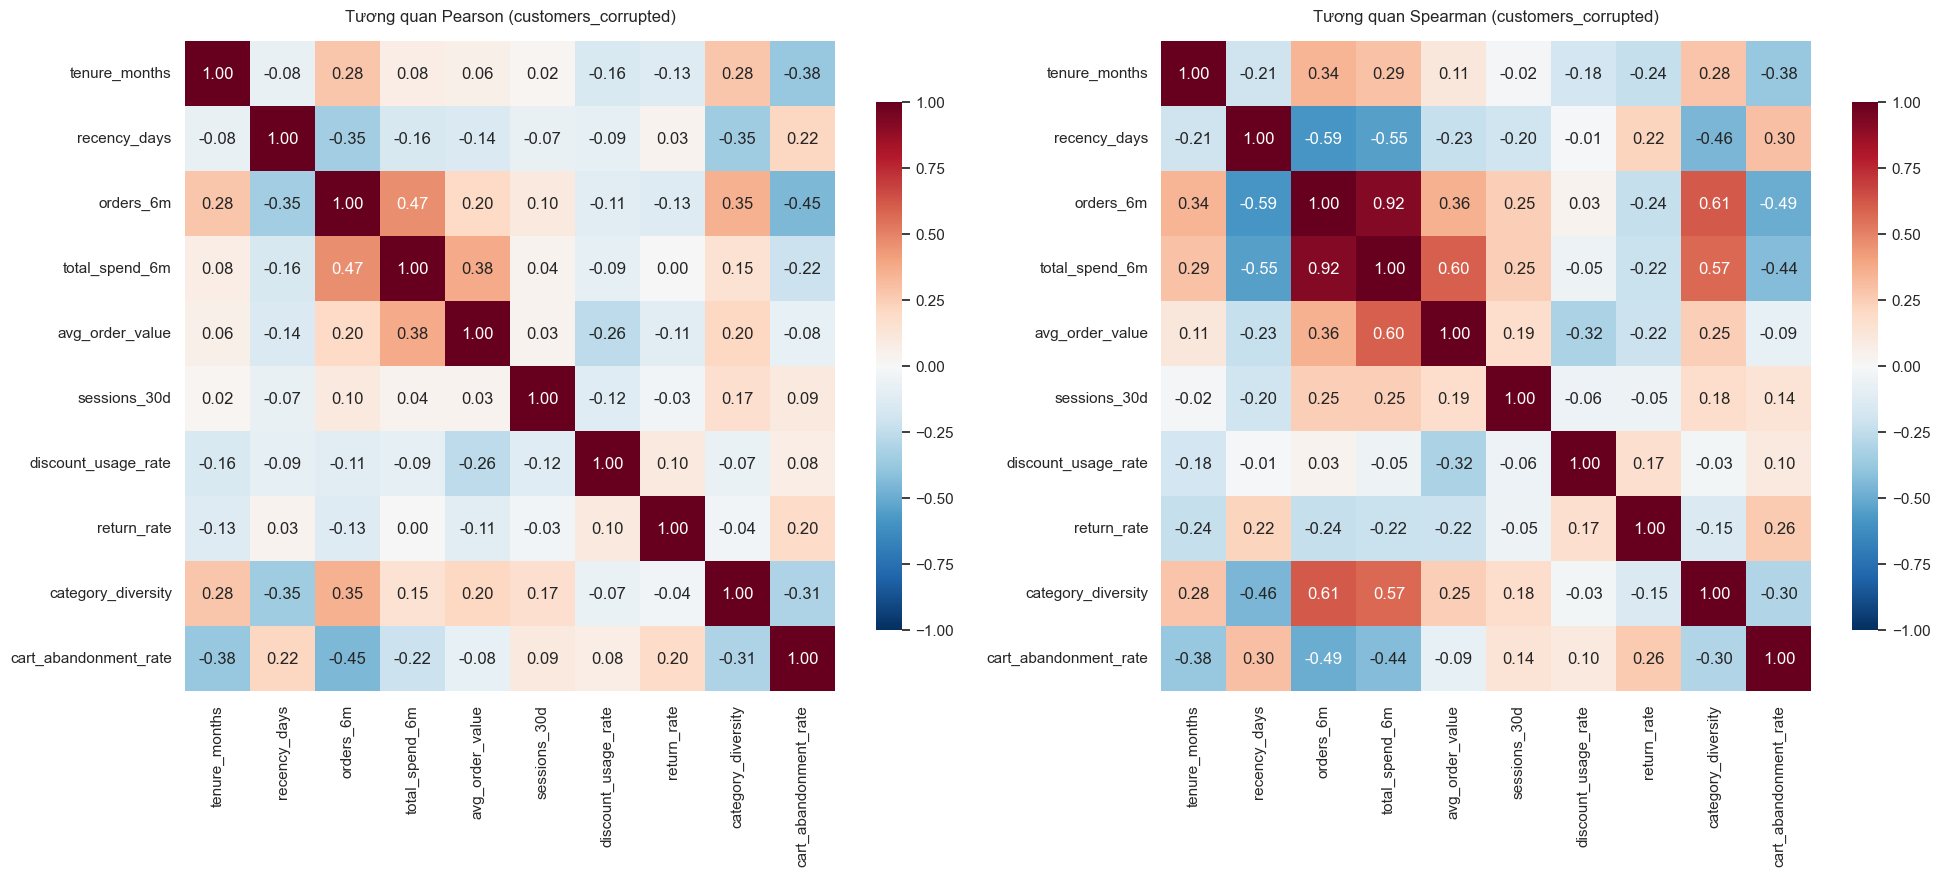

In [29]:
pearson_corr = eda_df[NUMERIC_FEATURES].corr(method="pearson")
spearman_corr = eda_df[NUMERIC_FEATURES].corr(method="spearman")

fig, axes = plt.subplots(1, 2, figsize=(20, 9))
for ax, (name, corr) in zip(axes, [("Pearson", pearson_corr), ("Spearman", spearman_corr)]):
    sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True, ax=ax,
                cbar_kws={"shrink": 0.7})
    ax.set_title(f"Tương quan {name} (customers_corrupted)", pad=14)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "b_correlation_heatmaps.png", dpi=150)
plt.show()

In [30]:
def correlated_pairs(pearson, spearman, threshold=0.5):
    rows = []
    columns = pearson.columns
    for i in range(len(columns)):
        for j in range(i + 1, len(columns)):
            p, s = pearson.iloc[i, j], spearman.iloc[i, j]
            if max(abs(p), abs(s)) >= threshold:
                rows.append({"feature_1": columns[i], "feature_2": columns[j],
                             "pearson": p, "spearman": s, "abs_difference": abs(p - s)})
    return pd.DataFrame(rows).sort_values("spearman", key=abs, ascending=False).reset_index(drop=True)


correlated_pairs(pearson_corr, spearman_corr).round(3)

,feature_1,feature_2,pearson,spearman,abs_difference
0,orders_6m,total_spend_6m,0.465,0.921,0.456
1,orders_6m,category_diversity,0.353,0.614,0.261
2,total_spend_6m,avg_order_value,0.380,0.595,0.216
3,recency_days,orders_6m,-0.349,-0.593,0.244
4,total_spend_6m,category_diversity,0.150,0.572,0.422
5,recency_days,total_spend_6m,-0.164,-0.553,0.389


**Nhận xét.** Theo Spearman, có một nhóm biến cùng phản ánh **mức độ mua hàng**:

- `orders_6m` ~ `total_spend_6m`: 0.92
- `orders_6m` ~ `category_diversity`: 0.61
- `total_spend_6m` ~ `avg_order_value`: 0.60
- `recency_days` ~ `orders_6m`: −0.59
- `total_spend_6m` ~ `category_diversity`: 0.57
- `recency_days` ~ `total_spend_6m`: −0.55

Một phần dư thừa đến từ chính định nghĩa: `total_spend_6m` ≈ `orders_6m` × `avg_order_value`.

Pearson cho cặp `orders_6m` ~ `total_spend_6m` chỉ là 0.47, thấp hơn Spearman 0.46. Lý do là các giá trị cực đoan của `total_spend_6m` (lỗi ×100) không đi kèm số đơn lớn, nên làm yếu quan hệ tuyến tính. Vì vậy, đánh giá dư thừa thông tin nên dựa trên Spearman.

`sessions_30d` chỉ tương quan yếu với `orders_6m` (Spearman 0.25). Truy cập nhiều không đồng nghĩa với mua nhiều, nên biến này mang thông tin riêng.

### b.7. Giá trị không hợp lệ và khả năng phát hiện ngoại lai

**Quy tắc nghiệp vụ.** Các quy tắc được suy ra từ định nghĩa của thuộc tính, không phải từ dữ liệu:

| Quy tắc | Điều kiện vi phạm |
|---|---|
| Biến đếm không âm | `tenure_months`, `recency_days`, `orders_6m`, `sessions_30d` < 0 |
| Tỷ lệ trong [0, 1] | `discount_usage_rate`, `return_rate`, `cart_abandonment_rate` ngoài [0, 1] |
| Tiền tệ không âm | `total_spend_6m`, `avg_order_value` < 0 |
| Phạm vi quan sát | `orders_6m` < 1 hoặc `recency_days` > 180 |
| `category_diversity` | ngoài [1, 8] |
| Recency so với tenure | `recency_days` > 30 × `tenure_months` |
| Số phiên khả thi | `sessions_30d` > 300, tức trung bình hơn 10 phiên/ngày. Đây là ngưỡng do người phân tích đặt cho hành vi người dùng thật |
| Nhất quán chi tiêu | `total_spend_6m` / (`orders_6m` × `avg_order_value`) ngoài [0.5, 2] |

Quy tắc nhất quán chi tiêu cho phép lệch tới 2 lần, vì sai số ghi nhận hợp lý vẫn có thể làm tỷ lệ này khác 1.

In [31]:
RULE_SESSIONS_MAX = 300
RULE_SPEND_RATIO_RANGE = (0.5, 2.0)


def check_business_rules(df):
    # Trả về DataFrame boolean: mỗi cột là một quy tắc, True = bản ghi vi phạm. NaN không bị tính là vi phạm.
    spend_ratio = df["total_spend_6m"] / (df["orders_6m"] * df["avg_order_value"])
    rules = {
        "negative_count": (df[["tenure_months", "recency_days", "orders_6m", "sessions_30d"]] < 0).any(axis=1),
        "rate_out_of_range": ((df[RATE_FEATURES] < 0) | (df[RATE_FEATURES] > 1)).any(axis=1),
        "negative_money": (df[["total_spend_6m", "avg_order_value"]] < 0).any(axis=1),
        "outside_observation_window": (df["orders_6m"] < 1) | (df["recency_days"] > 180),
        "category_diversity_invalid": ~df["category_diversity"].between(1, len(CATEGORIES)),
        "recency_exceeds_tenure": (df["tenure_months"] > 0) & (df["recency_days"] > 30 * df["tenure_months"]),
        "implausible_sessions": df["sessions_30d"] > RULE_SESSIONS_MAX,
        "spend_inconsistent": spend_ratio.notna() & ~spend_ratio.between(*RULE_SPEND_RATIO_RANGE),
    }
    return pd.DataFrame(rules)


rule_violations = check_business_rules(eda_df)
violation_summary = pd.DataFrame({
    "n_records": rule_violations.sum(),
    "customer_ids": [", ".join(eda_df.loc[rule_violations[r], "customer_id"]) for r in rule_violations],
})
print("Records violating at least one rule:", rule_violations.any(axis=1).sum())
violation_summary

Records violating at least one rule: 7


,n_records,customer_ids
negative_count,2,"C0131, C0192"
rate_out_of_range,2,"C0013, C0127"
negative_money,0,
outside_observation_window,0,
category_diversity_invalid,0,
recency_exceeds_tenure,0,
implausible_sessions,1,C0137
spend_inconsistent,2,"C0143, C0146"


**Phát hiện thống kê theo IQR.** Một bản ghi bị đánh dấu nếu ít nhất một thuộc tính số nằm ngoài [Q1 − k·IQR, Q3 + k·IQR]. So sánh hai ngưỡng: k = 1.5 (thông dụng) và k = 3 (chỉ bắt giá trị cực đoan).

In [32]:
def iqr_outlier_flags(df, k):
    q1, q3 = df.quantile(0.25), df.quantile(0.75)
    iqr = q3 - q1
    return (df < q1 - k * iqr) | (df > q3 + k * iqr)


iqr_flags = {k: iqr_outlier_flags(eda_df[NUMERIC_FEATURES], k) for k in [1.5, 3.0]}
iqr_counts = pd.DataFrame({f"k={k}": flags.sum() for k, flags in iqr_flags.items()})
iqr_counts.loc["ANY FEATURE (records)"] = [flags.any(axis=1).sum() for flags in iqr_flags.values()]
iqr_counts

,k=1.5,k=3.0
tenure_months,0,0
recency_days,25,15
orders_6m,2,2
total_spend_6m,20,9
avg_order_value,15,4
sessions_30d,12,5
discount_usage_rate,1,0
return_rate,7,1
category_diversity,0,0
cart_abandonment_rate,0,0


**Đối chiếu với metadata (chỉ để đánh giá giả lập).** Phần này so sánh các bản ghi bị đánh dấu với 12 `customer_id` đã chủ động tạo ngoại lai. Kết quả cho biết mỗi phương pháp bắt được bao nhiêu ngoại lai thật và đánh dấu nhầm bao nhiêu bản ghi bình thường. Metadata không được dùng để chọn phương pháp xử lý ở câu c.

In [33]:
detection_methods = {
    "business_rules": rule_violations.any(axis=1),
    "iqr_k1.5": iqr_flags[1.5].any(axis=1),
    "iqr_k3.0": iqr_flags[3.0].any(axis=1),
    "rules_or_iqr_k3.0": rule_violations.any(axis=1) | iqr_flags[3.0].any(axis=1),
}
eval_meta = simulation_metadata.set_index("customer_id").loc[eda_df["customer_id"]]
injected = eval_meta["is_outlier"].to_numpy()

detection_rows = []
for name, flagged in detection_methods.items():
    flagged = flagged.to_numpy()
    detection_rows.append({
        "method": name,
        "flagged_records": flagged.sum(),
        "detected_business_valid": (flagged & (eval_meta["outlier_type"] == "business_valid").to_numpy()).sum(),
        "detected_data_error": (flagged & (eval_meta["outlier_type"] == "data_error").to_numpy()).sum(),
        "detected_total_of_12": (flagged & injected).sum(),
        "flagged_not_injected": (flagged & ~injected).sum(),
    })
detection_summary = pd.DataFrame(detection_rows)
detection_summary

,method,flagged_records,detected_business_valid,detected_data_error,detected_total_of_12,flagged_not_injected
0,business_rules,7,0,7,7,0
1,iqr_k1.5,66,5,5,10,56
2,iqr_k3.0,28,5,4,9,19
3,rules_or_iqr_k3.0,31,5,7,12,19


In [34]:
per_outlier_detection = eval_meta.loc[eval_meta["is_outlier"], ["outlier_type", "outlier_rule"]].copy()
for name, flagged in detection_methods.items():
    per_outlier_detection[name] = flagged.set_axis(eda_df["customer_id"]).loc[per_outlier_detection.index]
per_outlier_detection["violated_rules"] = [
    ", ".join(rule_violations.columns[rule_violations.set_axis(eda_df["customer_id"]).loc[cid]]) or "-"
    for cid in per_outlier_detection.index
]
per_outlier_detection

,outlier_type,outlier_rule,business_rules,iqr_k1.5,iqr_k3.0,rules_or_iqr_k3.0,violated_rules
customer_id,,,,,,,
C0013,data_error,discount_rate_negative,True,True,False,True,rate_out_of_range
C0077,business_valid,very_high_frequency,False,True,True,True,-
C0118,business_valid,vip_high_order_value,False,True,True,True,-
C0127,data_error,return_rate_above_1,True,True,True,True,rate_out_of_range
C0129,business_valid,vip_high_order_value,False,True,True,True,-
C0131,data_error,recency_negative,True,False,False,True,negative_count
C0133,business_valid,very_high_frequency,False,True,True,True,-
C0137,data_error,sessions_tracking_999,True,True,True,True,implausible_sessions
C0143,data_error,spend_unit_x100,True,True,True,True,spend_inconsistent


**Nhận xét.**

- **Quy tắc nghiệp vụ:** đánh dấu 7 bản ghi, đúng là 7 ngoại lai lỗi, không đánh dấu nhầm bản ghi nào. Quy tắc không bắt được 5 ngoại lai nghiệp vụ, điều này hợp lý vì chúng không vi phạm ràng buộc nào.
- **IQR k = 1.5:** đánh dấu 66 bản ghi (30% dữ liệu), bắt được 10/12 ngoại lai, nhưng có 56 bản ghi không được can thiệp, chủ yếu do đuôi tự nhiên của `recency_days` (25) và `total_spend_6m` (20). IQR bỏ sót C0131 (`recency_days` = −15) và C0192 (`tenure_months` = −12), vì các giá trị âm nhỏ này vẫn nằm trong râu dưới.
- **IQR k = 3:** đánh dấu 28 bản ghi, bắt được 9/12, có 19 bản ghi bình thường bị đánh dấu.
- **Kết hợp quy tắc nghiệp vụ với IQR k = 3:** bắt đủ 12/12, kèm 19 bản ghi bình thường bị đánh dấu.

Không có phương pháp đơn lẻ nào vừa bắt đủ vừa không đánh dấu nhầm. Quy tắc nghiệp vụ chính xác cho lỗi vi phạm miền giá trị. IQR cần cho giá trị cực lớn nhưng hợp lệ về miền, đồng thời dễ đánh dấu nhầm đuôi tự nhiên của biến lệch. Bản ghi bị IQR đánh dấu vì vậy không nên bị xóa tự động.

### b.8. So sánh dữ liệu trước và sau khi đưa vào lỗi

Bảng dưới so sánh thống kê của `customers_original` và `customers_corrupted`. Mục đích là định lượng tác động của nhiễu, ngoại lai và giá trị thiếu lên các thống kê mà K-Means và bước chuẩn hóa sử dụng (mean, std), cũng như các thống kê bền vững hơn (median, IQR).

In [35]:
reference_df = pd.read_csv(DATA_DIR / "customers_original.csv")


def compare_statistics(before, after, columns):
    rows = []
    for column in columns:
        b, a = before[column], after[column].dropna()
        rows.append({
            "feature": column,
            "mean_before": b.mean(), "mean_after": a.mean(),
            "median_before": b.median(), "median_after": a.median(),
            "std_before": b.std(), "std_after": a.std(),
            "max_before": b.max(), "max_after": a.max(),
            "skew_before": b.skew(), "skew_after": a.skew(),
        })
    table = pd.DataFrame(rows).set_index("feature")
    table["std_ratio"] = table["std_after"] / table["std_before"]
    return table


before_after_stats = compare_statistics(reference_df, eda_df, NUMERIC_FEATURES)
before_after_stats.round(3)

,mean_before,mean_after,median_before,median_after,std_before,std_after,max_before,max_after,skew_before,skew_after,std_ratio
feature,,,,,,,,,,,
tenure_months,24.755,24.568,24.000,24.000,14.203,14.414,66.000,66.000,0.114,0.072,1.015
recency_days,39.164,39.014,21.000,21.000,48.215,48.339,180.000,180.000,1.782,1.771,1.003
orders_6m,5.850,6.359,4.000,4.000,4.767,7.664,19.000,75.000,0.774,5.273,1.608
total_spend_6m,3287.774,5216.698,1935.900,1938.810,3610.793,13766.111,18834.700,147995.000,1.845,7.099,3.812
avg_order_value,512.623,556.216,437.365,435.650,260.905,517.121,1789.310,6064.050,1.600,7.008,1.982
sessions_30d,14.945,20.118,12.000,12.000,12.875,67.841,86.000,999.000,1.799,13.854,5.269
discount_usage_rate,0.432,0.427,0.414,0.408,0.240,0.246,0.970,0.970,0.270,0.128,1.024
return_rate,0.125,0.131,0.100,0.100,0.093,0.147,0.452,1.850,1.255,7.516,1.588
category_diversity,2.727,2.727,2.000,2.000,1.775,1.775,8.000,8.000,1.063,1.063,1.000


In [36]:
corr_pairs_to_track = [("orders_6m", "total_spend_6m"), ("avg_order_value", "total_spend_6m"),
                       ("orders_6m", "recency_days"), ("sessions_30d", "orders_6m"),
                       ("orders_6m", "category_diversity")]
original_pearson = reference_df[NUMERIC_FEATURES].corr()
original_spearman = reference_df[NUMERIC_FEATURES].corr(method="spearman")
pd.DataFrame([{
    "pair": f"{x} ~ {y}",
    "pearson_original": original_pearson.loc[x, y], "pearson_corrupted": pearson_corr.loc[x, y],
    "spearman_original": original_spearman.loc[x, y], "spearman_corrupted": spearman_corr.loc[x, y],
} for x, y in corr_pairs_to_track]).round(3)

,pair,pearson_original,pearson_corrupted,spearman_original,spearman_corrupted
0,orders_6m ~ total_spend_6m,0.847,0.465,0.938,0.921
1,avg_order_value ~ total_spend_6m,0.587,0.380,0.600,0.595
2,orders_6m ~ recency_days,-0.474,-0.349,-0.583,-0.593
3,sessions_30d ~ orders_6m,0.070,0.099,0.284,0.248
4,orders_6m ~ category_diversity,0.578,0.353,0.617,0.614


**Nhận xét.**

- **Độ lệch chuẩn tăng mạnh.** So với dữ liệu sạch, std tăng 5.27 lần ở `sessions_30d`, 3.81 lần ở `total_spend_6m`, 1.98 lần ở `avg_order_value`, 1.61 lần ở `orders_6m` và 1.59 lần ở `return_rate`.
- **Trung bình bị kéo lên, trung vị gần như không đổi.** Trung bình `total_spend_6m` tăng từ 3287.8 lên 5216.7, trong khi trung vị chỉ đổi từ 1935.9 sang 1938.8. Skewness của `sessions_30d` tăng từ 1.80 lên 13.85.
- **Các biến không bị can thiệp giữ nguyên**, ví dụ `category_diversity`.
- **Pearson bị ảnh hưởng, Spearman thì không.** Pearson giữa `orders_6m` và `total_spend_6m` giảm từ 0.847 xuống 0.465, còn Spearman gần như không đổi (0.938 sang 0.921).

Như vậy, nhiễu và ngoại lai tác động chủ yếu lên các thống kê dựa trên trung bình và bình phương độ lệch (mean, std, Pearson), là các đại lượng mà chuẩn hóa z-score và K-Means sử dụng trực tiếp.

### b.9. Các vấn đề dữ liệu ảnh hưởng đến phân cụm

**Vấn đề 1 — Phân bố lệch và chênh lệch thang đo.**

*Bằng chứng (b.2, b.5):* độ lệch chuẩn giữa các biến chênh nhau khoảng 10⁵ lần. Năm biến có skewness từ 5 đến 14, và phân bố của `total_spend_6m`, `avg_order_value` sau log1p gần đối xứng hơn.

*Ảnh hưởng đến K-Means:* K-Means dùng khoảng cách Euclid.
- Nếu không đưa về cùng thang đo, `total_spend_6m` gần như quyết định toàn bộ khoảng cách, còn các tỷ lệ trong [0, 1] không còn vai trò.
- Với biến lệch phải, các điểm ở đuôi dài nằm xa trung tâm và góp phần lớn vào tổng bình phương sai số (SSE). Tâm cụm bị kéo về phía đuôi, hoặc thuật toán dành riêng một cụm cho vài điểm đuôi. Điều này đi ngược giả định của K-Means là các cụm có dạng gần cầu và kích thước tương đương.

**Vấn đề 2 — Tương quan và thông tin dư thừa.**

*Bằng chứng (b.6):* `orders_6m`, `total_spend_6m`, `avg_order_value`, `category_diversity` và `recency_days` tương quan Spearman với nhau ở mức |0.55–0.92|. `total_spend_6m` gần như được xác định bởi `orders_6m` × `avg_order_value`.

*Ảnh hưởng đến K-Means:* khoảng cách Euclid coi mỗi chiều là độc lập. Khi nhiều biến cùng đo "mức độ mua hàng", chiều này được tính nhiều lần và lấn át các khía cạnh hành vi khác như mức dùng giảm giá, tỷ lệ bỏ giỏ hay số phiên truy cập. Hệ quả là các cụm có xu hướng chỉ phân tầng theo mức chi tiêu, khó tách được nhóm săn khuyến mãi hay nhóm chỉ xem hàng.

**Vấn đề 3 — Giá trị thiếu.**

*Bằng chứng (b.4):* 31 bản ghi (14.1%) có giá trị thiếu. Giá trị thiếu của `cart_abandonment_rate` tập trung ở khách có ít phiên và ít đơn.

*Ảnh hưởng đến K-Means:* `KMeans` của scikit-learn không nhận NaN.
- Xóa bản ghi thiếu làm mất 14.1% mẫu và làm lệch tập dữ liệu, vì loại bỏ nhiều khách ít hoạt động hơn, tức đúng nhóm cần nhận diện.
- Điền bằng một giá trị toàn cục (trung vị hoặc trung bình) đặt các bản ghi này vào vị trí trung tâm của biến đó, có thể kéo chúng sai cụm. Điều này đặc biệt đáng lo khi giá trị thiếu phụ thuộc vào mức hoạt động.

**Vấn đề 4 — Ngoại lai và nhiễu.**

*Bằng chứng (b.5, b.7, b.8):*
- Có các điểm cách trung vị tới 65.8 IQR (`sessions_30d` = 999) và 40.8 IQR (`total_spend_6m`).
- 7 bản ghi vi phạm quy tắc nghiệp vụ. 5 bản ghi có chi tiêu hoặc tần suất rất cao nhưng hợp lệ.
- Std của `sessions_30d` và `total_spend_6m` tăng 5.27 và 3.81 lần so với dữ liệu sạch.

*Ảnh hưởng đến K-Means:*
- K-Means tối thiểu hóa tổng bình phương khoảng cách, nên một điểm cực đoan có thể chiếm trọn một cụm hoặc kéo lệch tâm cụm.
- Ngoại lai cũng làm std bị thổi phồng. Khi chuẩn hóa z-score, std lớn nén sự khác biệt giữa các khách hàng bình thường lại, làm giảm khả năng phân tách.
- Nhiễu (khoảng 10% với chi tiêu; với số phiên, thay đổi tương đối trung bình 35% trên các bản ghi bị tác động) làm mờ ranh giới giữa các cụm vốn đã chồng lấn. Nhiễu cũng khó loại bỏ ở mức từng bản ghi vì không tạo giá trị bất thường rõ ràng.
- Hai loại ngoại lai cần xử lý khác nhau. Lỗi dữ liệu nên được coi là giá trị sai. Ngoại lai nghiệp vụ là khách hàng thật, không nên xóa, nhưng cần giảm ảnh hưởng của chúng lên khoảng cách.

## Câu c — Data Preprocessing

Quy trình tiền xử lý chỉ dùng `customers_corrupted.csv`, gồm bốn bước:

1. **Giá trị không hợp lệ → NaN.** Áp dụng các quy tắc nghiệp vụ đã xác định ở b.7. Giá trị vi phạm được coi là không biết và chuyển thành NaN, sau đó điền khuyết như giá trị thiếu.
2. **Điền khuyết.** Ưu tiên quan hệ định nghĩa giữa các biến khi có. Nếu không có, dùng trung vị có điều kiện hoặc trung vị toàn cục.
3. **Phát hiện ngoại lai bằng IQR** trên dữ liệu đã sửa, để biết những gì còn lại sau khi loại giá trị sai.
4. **Xử lý ngoại lai và nhiễu.** Không xóa bản ghi. Quyết định cụ thể được giải thích ở c.4.

`customers_original.csv` và metadata không được dùng trong các bước trên. Chúng chỉ xuất hiện ở các ô **đánh giá sau xử lý**, có ghi chú rõ, để đo mức độ nhận diện và sai số điền khuyết.

In [37]:
raw_df = pd.read_csv(DATA_DIR / "customers_corrupted.csv")
print(raw_df.shape)

(220, 13)


### c.1. Xử lý giá trị không hợp lệ

Quy tắc ở mức từng ô: giá trị vi phạm ở cột nào thì chỉ cột đó bị chuyển thành NaN, các cột còn lại của bản ghi được giữ nguyên.

| Quy tắc | Cột bị chuyển thành NaN |
|---|---|
| Biến đếm âm | cột vi phạm (`tenure_months`, `recency_days`, `orders_6m`, `sessions_30d`) |
| Tỷ lệ ngoài [0, 1] | cột tỷ lệ vi phạm |
| Tiền tệ âm | `total_spend_6m` hoặc `avg_order_value` |
| `orders_6m` < 1, `recency_days` > 180 | cột vi phạm (ngoài cửa sổ quan sát) |
| `category_diversity` ngoài [1, 8] | `category_diversity` |
| `sessions_30d` > 300 | `sessions_30d` |
| `recency_days` > 30 × `tenure_months` | `recency_days` |
| `total_spend_6m` / (`orders_6m` × `avg_order_value`) ngoài [0.5, 2] | `total_spend_6m` |

Hai quy tắc chéo cần một quy ước về việc cột nào bị coi là sai:

- **Chi tiêu không nhất quán:** chọn `total_spend_6m`. Đây là trường tổng hợp, dễ gặp lỗi đơn vị hoặc lỗi cộng dồn hơn hai trường thành phần. Nó cũng có thể tính lại từ hai trường còn lại theo định nghĩa.
- **Recency vượt tenure:** chọn `recency_days`, vì `tenure_months` lấy từ ngày đăng ký tài khoản, ổn định hơn.

Đây là giả định nghiệp vụ, không thể kiểm chứng trên dữ liệu.

**Phân biệt với hành vi hiếm nhưng hợp lệ.** Chi tiêu, số đơn hay số phiên rất cao nhưng vẫn khả thi và nhất quán với các trường khác **không** bị coi là lỗi ở bước này.

In [38]:
def mark_invalid_values(df):
    # Chuyển giá trị vi phạm quy tắc nghiệp vụ thành NaN; trả về dữ liệu mới và log từng ô bị đổi.
    marked = df.copy()
    logs = []

    def invalidate(mask, column, rule):
        mask = mask.fillna(False).astype(bool)
        for idx in marked.index[mask]:
            logs.append({"customer_id": marked.at[idx, "customer_id"], "column": column,
                         "invalid_value": marked.at[idx, column], "rule": rule})
        marked[column] = marked[column].astype(float)
        marked.loc[mask, column] = np.nan

    for column in ["tenure_months", "recency_days", "orders_6m", "sessions_30d"]:
        invalidate(marked[column] < 0, column, "negative_count")
    for column in RATE_FEATURES:
        invalidate(marked[column].notna() & ~marked[column].between(0, 1), column, "rate_out_of_range")
    for column in ["total_spend_6m", "avg_order_value"]:
        invalidate(marked[column] < 0, column, "negative_money")
    invalidate(marked["orders_6m"] < 1, "orders_6m", "outside_observation_window")
    invalidate(marked["recency_days"] > 180, "recency_days", "outside_observation_window")
    invalidate(marked["category_diversity"].notna() & ~marked["category_diversity"].between(1, len(CATEGORIES)),
               "category_diversity", "category_diversity_invalid")
    invalidate(marked["sessions_30d"] > RULE_SESSIONS_MAX, "sessions_30d", "implausible_sessions")
    invalidate(marked["recency_days"] > 30 * marked["tenure_months"], "recency_days", "recency_exceeds_tenure")

    spend_ratio = marked["total_spend_6m"] / (marked["orders_6m"] * marked["avg_order_value"])
    invalidate(spend_ratio.notna() & ~spend_ratio.between(*RULE_SPEND_RATIO_RANGE),
               "total_spend_6m", "spend_inconsistent")

    log_columns = ["customer_id", "column", "invalid_value", "rule"]
    return marked, pd.DataFrame(logs, columns=log_columns)


marked_df, invalid_log = mark_invalid_values(raw_df)
print("Invalid cells set to NaN:", len(invalid_log))
invalid_log

Invalid cells set to NaN: 7


,customer_id,column,invalid_value,rule
0,C0192,tenure_months,-12.00,negative_count
1,C0131,recency_days,-15.00,negative_count
2,C0013,discount_usage_rate,-0.40,rate_out_of_range
3,C0127,return_rate,1.85,rate_out_of_range
4,C0137,sessions_30d,999.00,implausible_sessions
5,C0143,total_spend_6m,78120.00,spend_inconsistent
6,C0146,total_spend_6m,147995.00,spend_inconsistent


**Nhận xét.** Có 7 ô bị chuyển thành NaN, mỗi ô thuộc một bản ghi khác nhau. Đây đúng là 7 bản ghi đã vi phạm quy tắc ở b.7. Không có khách chi tiêu hoặc tần suất cao nào bị coi là lỗi, vì giá trị của họ vẫn khả thi và nhất quán với `orders_6m` × `avg_order_value`. Các cột khác của 7 bản ghi này được giữ nguyên.

### c.2. Điền giá trị thiếu

Giá trị cần điền gồm 33 giá trị thiếu ban đầu, cộng các giá trị vừa bị chuyển thành NaN ở c.1. Phương pháp cho từng cột:

| Cột | Phương pháp | Lý do |
|---|---|---|
| `total_spend_6m` | `orders_6m` × `avg_order_value` | Đúng định nghĩa của tổng chi tiêu. Dùng thông tin riêng của từng khách, thay vì đặt khách vào giữa phân bố |
| `avg_order_value` | `total_spend_6m` / `orders_6m` | Như trên. Median imputation sẽ bỏ qua việc khách chi 10 nghìn hay 200 nghìn trong 6 tháng |
| `cart_abandonment_rate` | Trung vị theo nhóm `orders_6m` (1, 2–3, 4–8, ≥ 9 đơn) | Giá trị thiếu tập trung ở khách ít đơn (b.4). Biến này tương quan Spearman −0.50 với `orders_6m` nhưng chỉ 0.13 với `sessions_30d`. Trung vị toàn cục vì vậy sẽ kéo các khách ít đơn về mức của khách trung bình |
| Các cột số còn lại | Trung vị toàn cục, làm tròn với biến đếm | Mỗi cột chỉ có 1 giá trị cần điền, không đáng dùng phương pháp phức tạp hơn. Trung vị bền với ngoại lai |
| Biến phân loại | Mode | Hiện không có giá trị thiếu; giữ để quy trình áp dụng được cho dữ liệu mới |

Hạn chế: `avg_order_value` được điền từ `total_spend_6m` nên cũng mang theo nhiễu đo lường của `total_spend_6m`, nếu có.

In [39]:
ORDER_BINS = [0, 1, 3, 8, np.inf]
ORDER_BIN_LABELS = ["1", "2-3", "4-8", "9+"]


def cart_median_by_order_group(df):
    groups = pd.cut(df["orders_6m"], ORDER_BINS, labels=ORDER_BIN_LABELS)
    return groups, df.groupby(groups, observed=True)["cart_abandonment_rate"].agg(["median", "count"])


def impute_missing(df):
    imputed = df.copy()
    logs = []

    def fill(mask, column, values, method):
        values = pd.Series(values, index=imputed.index) if np.isscalar(values) else values
        for idx in imputed.index[mask]:
            logs.append({"customer_id": imputed.at[idx, "customer_id"], "column": column,
                         "imputed_value": values[idx], "method": method})
        imputed.loc[mask, column] = values[mask]

    mask = imputed["total_spend_6m"].isna() & imputed["avg_order_value"].notna() & imputed["orders_6m"].notna()
    fill(mask, "total_spend_6m", (imputed["orders_6m"] * imputed["avg_order_value"]).round(2), "orders_x_aov")

    mask = imputed["avg_order_value"].isna() & imputed["total_spend_6m"].notna() & imputed["orders_6m"].notna()
    fill(mask, "avg_order_value", (imputed["total_spend_6m"] / imputed["orders_6m"]).round(2), "spend_div_orders")

    groups, group_stats = cart_median_by_order_group(imputed)
    mask = imputed["cart_abandonment_rate"].isna() & groups.notna()
    fill(mask, "cart_abandonment_rate", groups.map(group_stats["median"]).astype(float), "median_by_orders_group")

    for column in NUMERIC_FEATURES:
        mask = imputed[column].isna()
        if mask.any():
            median = imputed[column].median()
            fill(mask, column, round(median) if column in COUNT_FEATURES else median, "column_median")
    for column in CATEGORICAL_FEATURES:
        mask = imputed[column].isna()
        if mask.any():
            fill(mask, column, imputed[column].mode()[0], "mode")

    for column in COUNT_FEATURES:
        imputed[column] = imputed[column].round().astype(int)
    return imputed, pd.DataFrame(logs), group_stats


preprocessed_df, impute_log, cart_group_stats = impute_missing(marked_df)
print("Cart abandonment median by orders group (observed values):")
print(cart_group_stats.round(3).to_string())
print("\nImputed cells by column and method:")
print(impute_log.groupby(["column", "method"]).size().to_string())

Cart abandonment median by orders group (observed values):
           median  count
orders_6m               
1           0.572     44
2-3         0.694     45
4-8         0.512     50
9+          0.299     63

Imputed cells by column and method:
column                 method                
avg_order_value        spend_div_orders          15
cart_abandonment_rate  median_by_orders_group    18
discount_usage_rate    column_median              1
recency_days           column_median              1
return_rate            column_median              1
sessions_30d           column_median              1
tenure_months          column_median              1
total_spend_6m         orders_x_aov               2


In [40]:
missing_comparison = pd.DataFrame({
    "missing_in_corrupted": raw_df[INPUT_FEATURES].isna().sum(),
    "missing_after_invalid_to_nan": marked_df[INPUT_FEATURES].isna().sum(),
    "missing_after_imputation": preprocessed_df[INPUT_FEATURES].isna().sum(),
})
missing_comparison["missing_rate_corrupted"] = (missing_comparison["missing_in_corrupted"] / len(raw_df)).round(4)
missing_comparison["missing_rate_after"] = (missing_comparison["missing_after_imputation"] / len(raw_df)).round(4)
missing_comparison[missing_comparison.drop(columns="missing_rate_after").sum(axis=1) > 0]

,missing_in_corrupted,missing_after_invalid_to_nan,missing_after_imputation,missing_rate_corrupted,missing_rate_after
tenure_months,0,1,0,0.0000,0.0
recency_days,0,1,0,0.0000,0.0
total_spend_6m,0,2,0,0.0000,0.0
avg_order_value,15,15,0,0.0682,0.0
sessions_30d,0,1,0,0.0000,0.0
discount_usage_rate,0,1,0,0.0000,0.0
return_rate,0,1,0,0.0000,0.0
cart_abandonment_rate,18,18,0,0.0818,0.0


In [41]:
def check_preprocessed_data(df, reference):
    assert len(df) == len(reference) == N_CUSTOMERS
    assert (df["customer_id"].to_numpy() == reference["customer_id"].to_numpy()).all()
    assert list(df.columns) == ["customer_id"] + INPUT_FEATURES
    assert df[INPUT_FEATURES].notna().all().all()
    for column in COUNT_FEATURES:
        assert pd.api.types.is_integer_dtype(df[column]), column
    assert not check_business_rules(df).any().any()
    print("Preprocessed data OK: 220 records, no missing values, no business-rule violations")


check_preprocessed_data(preprocessed_df, raw_df)

Preprocessed data OK: 220 records, no missing values, no business-rule violations


**Nhận xét.**

- **Trung vị `cart_abandonment_rate` theo nhóm số đơn** (tính trên các giá trị quan sát được): 0.572 với khách 1 đơn, 0.694 với 2–3 đơn, 0.512 với 4–8 đơn và 0.299 với từ 9 đơn trở lên. Mức chênh giữa các nhóm đủ lớn để giá trị điền phụ thuộc vào mức mua hàng của từng khách. Đây đúng là căn cứ của lựa chọn ở c.2.
- **Số ô đã điền:** 40, gồm:
  - 15 ô `avg_order_value` và 2 ô `total_spend_6m`, điền theo quan hệ định nghĩa.
  - 18 ô `cart_abandonment_rate`, điền theo trung vị nhóm.
  - 5 ô ở 5 cột khác, điền theo trung vị toàn cục.
- **Kết quả sau điền khuyết:** không còn giá trị thiếu ở thuộc tính nào và không còn bản ghi vi phạm quy tắc nghiệp vụ. Các biến đếm đã được đưa về kiểu số nguyên.

### c.3. Phát hiện ngoại lai sau khi sửa giá trị không hợp lệ

Áp dụng lại quy tắc IQR (hàm `iqr_outlier_flags` ở b.7) trên dữ liệu đã sửa, với k = 1.5 và k = 3. Ngưỡng chung cho mọi biến, không điều chỉnh theo từng bản ghi.

In [42]:
pre_iqr_flags = {k: iqr_outlier_flags(preprocessed_df[NUMERIC_FEATURES], k) for k in [1.5, 3.0]}
pre_iqr_counts = pd.DataFrame({f"k={k}": flags.sum() for k, flags in pre_iqr_flags.items()})
pre_iqr_counts.loc["ANY FEATURE (records)"] = [flags.any(axis=1).sum() for flags in pre_iqr_flags.values()]
pre_iqr_counts

,k=1.5,k=3.0
tenure_months,0,0
recency_days,25,15
orders_6m,2,2
total_spend_6m,19,7
avg_order_value,16,5
sessions_30d,12,4
discount_usage_rate,0,0
return_rate,6,0
category_diversity,0,0
cart_abandonment_rate,0,0


In [43]:
extreme_flags = pre_iqr_flags[3.0]
extreme_records = preprocessed_df.loc[extreme_flags.any(axis=1), ["customer_id"] + NUMERIC_FEATURES].copy()
extreme_records.insert(1, "flagged_features", [
    ", ".join(extreme_flags.columns[extreme_flags.loc[idx]]) for idx in extreme_records.index])
print("Records flagged with k=3:", len(extreme_records))
print(extreme_records["flagged_features"].value_counts().to_string())
extreme_records.sort_values("total_spend_6m", ascending=False).head(12)

Records flagged with k=3: 25
flagged_features
recency_days                               15
total_spend_6m, avg_order_value             4
sessions_30d                                2
orders_6m, total_spend_6m, sessions_30d     2
total_spend_6m                              1
avg_order_value                             1


,customer_id,flagged_features,tenure_months,recency_days,orders_6m,total_spend_6m,avg_order_value,sessions_30d,discount_usage_rate,return_rate,category_diversity,cart_abandonment_rate
132,C0133,"orders_6m, total_spend_6m, sessions_30d",23,1,75,79784.25,1063.79,76,0.041,0.029,3,0.122
117,C0118,"total_spend_6m, avg_order_value",24,13,10,60640.50,6064.05,36,0.040,0.072,5,0.410
76,C0077,"orders_6m, total_spend_6m, sessions_30d",41,2,63,46085.76,731.52,85,0.252,0.014,2,0.069
196,C0197,"total_spend_6m, avg_order_value",38,9,14,39247.74,2803.41,9,0.328,0.070,6,0.181
128,C0129,"total_spend_6m, avg_order_value",34,5,12,36330.00,3027.50,6,0.101,0.040,3,0.479
203,C0204,"total_spend_6m, avg_order_value",27,17,12,20807.11,1568.83,47,0.362,0.083,3,0.461
36,C0037,total_spend_6m,39,1,14,15695.44,1253.72,1,0.445,0.048,6,0.298
165,C0166,avg_order_value,20,160,2,3198.83,1599.42,5,0.675,0.171,1,0.650
84,C0085,sessions_30d,25,46,3,2447.20,903.41,74,0.162,0.162,2,0.645
45,C0046,recency_days,21,180,3,1935.47,692.78,19,0.380,0.022,2,0.893


**Đánh giá sau xử lý: đối chiếu với metadata.** Phần này kiểm tra hai việc:
1. Bước c.1 đã sửa được bao nhiêu ngoại lai lỗi.
2. IQR trên dữ liệu đã sửa còn đánh dấu những bản ghi nào.

Kết quả không được dùng để thay đổi quy tắc hay ngưỡng ở trên.

In [44]:
pre_eval = simulation_metadata.set_index("customer_id").loc[preprocessed_df["customer_id"]]
invalid_ids = set(invalid_log["customer_id"])
pre_eval_rows = []
for outlier_type in ["business_valid", "data_error"]:
    ids = pre_eval.index[pre_eval["outlier_type"] == outlier_type]
    pre_eval_rows.append({
        "outlier_type": outlier_type,
        "injected": len(ids),
        "corrected_by_rules": len(set(ids) & invalid_ids),
        "flagged_iqr_k1.5_after": int(pre_iqr_flags[1.5].any(axis=1).set_axis(pre_eval.index)[ids].sum()),
        "flagged_iqr_k3.0_after": int(extreme_flags.any(axis=1).set_axis(pre_eval.index)[ids].sum()),
    })
not_injected = ~pre_eval["is_outlier"].to_numpy()
pre_eval_rows.append({
    "outlier_type": "not_injected", "injected": int(not_injected.sum()),
    "corrected_by_rules": len(set(pre_eval.index[not_injected]) & invalid_ids),
    "flagged_iqr_k1.5_after": int((pre_iqr_flags[1.5].any(axis=1).to_numpy() & not_injected).sum()),
    "flagged_iqr_k3.0_after": int((extreme_flags.any(axis=1).to_numpy() & not_injected).sum()),
})
pd.DataFrame(pre_eval_rows)

,outlier_type,injected,corrected_by_rules,flagged_iqr_k1.5_after,flagged_iqr_k3.0_after
0,business_valid,5,0,5,5
1,data_error,7,7,0,0
2,not_injected,208,0,58,20


**Nhận xét.** Sau khi sửa giá trị không hợp lệ, IQR đánh dấu 63 bản ghi với k = 1.5 và 25 bản ghi với k = 3. Với k = 3, các thuộc tính gây ra việc đánh dấu là:

- **`recency_days`: 15 bản ghi.** Ngưỡng trên là 160 ngày, nên đây là các khách có recency gần giới hạn 180 ngày của cửa sổ quan sát. Đó là đuôi tự nhiên của biến chứ không phải giá trị sai.
- **`total_spend_6m` và/hoặc `avg_order_value`: 6 bản ghi.**
- **`sessions_30d`: 2 bản ghi.**
- **`orders_6m`, `total_spend_6m` và `sessions_30d` cùng lúc: 2 bản ghi.** Đây là 2 khách mua 63 và 75 đơn.

Đối chiếu với metadata:

- **7 ngoại lai lỗi:** đều đã được sửa ở c.1, và sau khi sửa không bản ghi nào bị IQR đánh dấu nữa.
- **5 ngoại lai nghiệp vụ:** vẫn bị đánh dấu với k = 3, vì chúng được giữ nguyên.
- **20 bản ghi không bị can thiệp cũng bị đánh dấu với k = 3:** 15 bản ghi do recency gần 180 ngày, 5 bản ghi còn lại là khách có số phiên, chi tiêu hoặc giá trị đơn cao tự nhiên.

Điều này cho thấy nếu xóa mọi bản ghi bị IQR đánh dấu, ta sẽ mất cả khách VIP thật lẫn nhiều khách bình thường.

### c.4. Xử lý ngoại lai và nhiễu

**Ngoại lai.** Sau c.1, mọi giá trị vi phạm quy tắc nghiệp vụ đã được thay thế. Các bản ghi còn bị IQR đánh dấu có giá trị lớn nhưng khả thi và nhất quán với các trường khác. Không có căn cứ nghiệp vụ để coi chúng là sai, nên:

- **Không xóa bản ghi** và **không winsorize trong `customers_preprocessed.csv`**. Dữ liệu sau tiền xử lý giữ đơn vị gốc, để dùng cho việc mô tả và diễn giải cụm (ví dụ chi tiêu trung bình của từng cụm). Winsorize sẽ làm sai lệch đúng những khách có giá trị kinh doanh cao nhất.
- **Ảnh hưởng của chúng lên khoảng cách sẽ được giảm ở bước chuẩn bị đặc trưng** bằng biến đổi log cho các biến lệch phải. Bảng dưới đánh giá xem biến đổi này giảm mức cách biệt (robust z-score) của các điểm cực đoan đến đâu.

In [45]:
skewed_features = ["recency_days", "orders_6m", "total_spend_6m", "avg_order_value", "sessions_30d", "return_rate"]
leverage_check = pd.DataFrame({
    "skew_raw": preprocessed_df[skewed_features].skew(),
    "skew_log1p": np.log1p(preprocessed_df[skewed_features]).skew(),
    "max_robust_z_raw": robust_zscore(preprocessed_df[skewed_features]).abs().max(),
    "max_robust_z_log1p": robust_zscore(np.log1p(preprocessed_df[skewed_features])).abs().max(),
})
leverage_check.round(2)

,skew_raw,skew_log1p,max_robust_z_raw,max_robust_z_log1p
recency_days,1.78,-0.13,4.13,1.79
orders_6m,5.27,0.29,10.14,2.26
total_spend_6m,5.89,0.15,22.42,2.20
avg_order_value,7.01,0.79,21.82,4.87
sessions_30d,2.07,-0.48,5.19,2.31
return_rate,1.23,1.02,3.05,2.68


**Nhận xét.** Biến đổi log1p làm giảm mạnh độ lệch và mức cách biệt của các điểm cực đoan:

| Biến | Skewness: gốc → log1p | Robust z lớn nhất: gốc → log1p |
|---|---|---|
| `total_spend_6m` | 5.89 → 0.15 | 22.42 → 2.20 |
| `orders_6m` | 5.27 → 0.29 | 10.14 → 2.26 |
| `avg_order_value` | 7.01 → 0.79 | 21.82 → 4.87 |

Các khách VIP vẫn nằm ở đầu phân bố, nhưng không còn cách biệt đến mức chiếm trọn một cụm.

`return_rate` gần như không đổi (skewness 1.23 → 1.02). Lý do là giá trị của biến này nhỏ (≤ 0.45), và trong khoảng đó log1p gần như tuyến tính. Đây là căn cứ để ở bước chuẩn bị đặc trưng chỉ áp dụng log cho các biến lệch phải có thang đo lớn, thay vì cho mọi biến.

**Nhiễu.** Nhiễu Gaussian không tạo ra giá trị vi phạm quy tắc, nên không thể xác định từng giá trị bị nhiễu hay loại bỏ nó khi không biết giá trị thật. Dấu hiệu duy nhất quan sát được là `total_spend_6m` lệch khỏi `orders_6m` × `avg_order_value`. Tuy vậy, không có căn cứ để biết trường nào sai. Ghi đè `total_spend_6m` bằng tích của hai trường kia đồng nghĩa với giả định `avg_order_value` không có sai số, một giả định không kiểm chứng được. Vì vậy:

- Không sửa các giá trị có độ lệch nằm trong ngưỡng [0.5, 2].
- Giảm ảnh hưởng của nhiễu bằng cách dùng các thống kê bền vững (trung vị, IQR) trong tiền xử lý, và biến đổi log ở bước chuẩn bị. Với nhiễu tương đối, biến đổi log chuyển nhiễu về dạng cộng có biên độ gần đều trên toàn thang đo.
- Không khẳng định nhiễu đã được loại bỏ: nhiễu trên `sessions_30d` hoàn toàn không phát hiện được từ dữ liệu.

In [46]:
spend_ratio_after = preprocessed_df["total_spend_6m"] / (preprocessed_df["orders_6m"] * preprocessed_df["avg_order_value"])
print("Records with |spend / (orders x aov) - 1| > 1%:", int(((spend_ratio_after - 1).abs() > 0.01).sum()))
print("Ratio range:", spend_ratio_after.min().round(3), "-", spend_ratio_after.max().round(3))

Records with |spend / (orders x aov) - 1| > 1%: 76
Ratio range: 0.625 - 1.258


**Nhận xét.** Sau tiền xử lý, vẫn còn 76 bản ghi có `total_spend_6m` lệch hơn 1% so với `orders_6m` × `avg_order_value`. Tỷ lệ giữa hai giá trị dao động từ 0.625 đến 1.258. Đây là dấu hiệu của sai số đo lường, nhưng như đã giải thích, các giá trị này không bị sửa. Nhiễu vẫn còn trong dữ liệu sau tiền xử lý.

### c.5. Lưu dữ liệu và so sánh trước/sau xử lý

In [47]:
def build_change_log(raw, processed):
    changes = impute_log.merge(invalid_log[["customer_id", "column", "rule"]], on=["customer_id", "column"], how="left")
    changes["original_value"] = [raw.loc[raw["customer_id"] == cid, col].iloc[0]
                                 for cid, col in zip(changes["customer_id"], changes["column"])]
    changes["final_value"] = [processed.loc[processed["customer_id"] == cid, col].iloc[0]
                              for cid, col in zip(changes["customer_id"], changes["column"])]
    changes["reason"] = np.where(changes["rule"].notna(), "invalid:" + changes["rule"].fillna(""), "missing")
    return changes[["customer_id", "column", "reason", "method", "original_value", "final_value"]]


preprocessing_changes = build_change_log(raw_df, preprocessed_df)

preprocessed_path = DATA_DIR / "customers_preprocessed.csv"
preprocessed_df.to_csv(preprocessed_path, index=False)
preprocessing_changes.to_csv(RESULT_DIR / "preprocessing_changes.csv", index=False)
check_preprocessed_data(pd.read_csv(preprocessed_path), raw_df)
print(f"Saved {preprocessed_path.relative_to(PROJECT_DIR)} and results/preprocessing_changes.csv")

Preprocessed data OK: 220 records, no missing values, no business-rule violations
Saved data\customers_preprocessed.csv and results/preprocessing_changes.csv


In [48]:
# Số ô khác nhau giữa corrupted và preprocessed (NaN -> giá trị cũng tính là thay đổi).
changed_cells = ~((raw_df[INPUT_FEATURES] == preprocessed_df[INPUT_FEATURES])
                  | (raw_df[INPUT_FEATURES].isna() & preprocessed_df[INPUT_FEATURES].isna()))
assert changed_cells.to_numpy().sum() == len(preprocessing_changes)

overview = pd.DataFrame({
    "corrupted": [len(raw_df), int(raw_df[INPUT_FEATURES].isna().sum().sum()),
                  int(check_business_rules(raw_df).any(axis=1).sum()), len(invalid_log), 0],
    "preprocessed": [len(preprocessed_df), int(preprocessed_df[INPUT_FEATURES].isna().sum().sum()),
                     int(check_business_rules(preprocessed_df).any(axis=1).sum()), 0,
                     int(changed_cells.to_numpy().sum())],
}, index=["records", "missing_cells", "records_violating_rules", "invalid_cells", "adjusted_cells"])
overview

,corrupted,preprocessed
records,220,220
missing_cells,33,0
records_violating_rules,7,0
invalid_cells,7,0
adjusted_cells,0,40


In [49]:
per_column = pd.DataFrame({
    "missing_before": raw_df[INPUT_FEATURES].isna().sum(),
    "invalid_before": invalid_log["column"].value_counts(),
    "adjusted_cells": changed_cells.sum(),
    "missing_after": preprocessed_df[INPUT_FEATURES].isna().sum(),
}).fillna(0).astype(int).loc[INPUT_FEATURES]
affected_columns = per_column.index[per_column["adjusted_cells"] > 0].tolist()
print(per_column.loc[affected_columns].to_string())

preprocessing_stats = compare_statistics(raw_df, preprocessed_df, affected_columns)
preprocessing_stats.round(3)

                       missing_before  invalid_before  adjusted_cells  missing_after
tenure_months                       0               1               1              0
recency_days                        0               1               1              0
total_spend_6m                      0               2               2              0
avg_order_value                    15               0              15              0
sessions_30d                        0               1               1              0
discount_usage_rate                 0               1               1              0
return_rate                         0               1               1              0
cart_abandonment_rate              18               0              18              0


,mean_before,mean_after,median_before,median_after,std_before,std_after,max_before,max_after,skew_before,skew_after,std_ratio
feature,,,,,,,,,,,
tenure_months,24.568,24.732,24.000,24.000,14.414,14.200,66.000,66.000,0.072,0.119,0.985
recency_days,39.014,39.182,21.000,22.000,48.339,48.215,180.000,180.000,1.771,1.780,0.997
total_spend_6m,5216.698,4199.180,1938.810,1931.665,13766.111,8441.877,147995.000,79784.250,7.099,5.887,0.613
avg_order_value,556.216,555.185,435.650,437.365,517.121,506.025,6064.050,6064.050,7.008,7.006,0.979
sessions_30d,20.118,15.632,12.000,12.000,67.841,14.390,999.000,86.000,13.854,2.072,0.212
discount_usage_rate,0.427,0.430,0.408,0.409,0.246,0.239,0.970,0.970,0.128,0.283,0.974
return_rate,0.131,0.123,0.100,0.100,0.147,0.091,1.850,0.452,7.516,1.230,0.614
cart_abandonment_rate,0.485,0.488,0.469,0.492,0.228,0.222,0.985,0.985,-0.048,-0.089,0.973


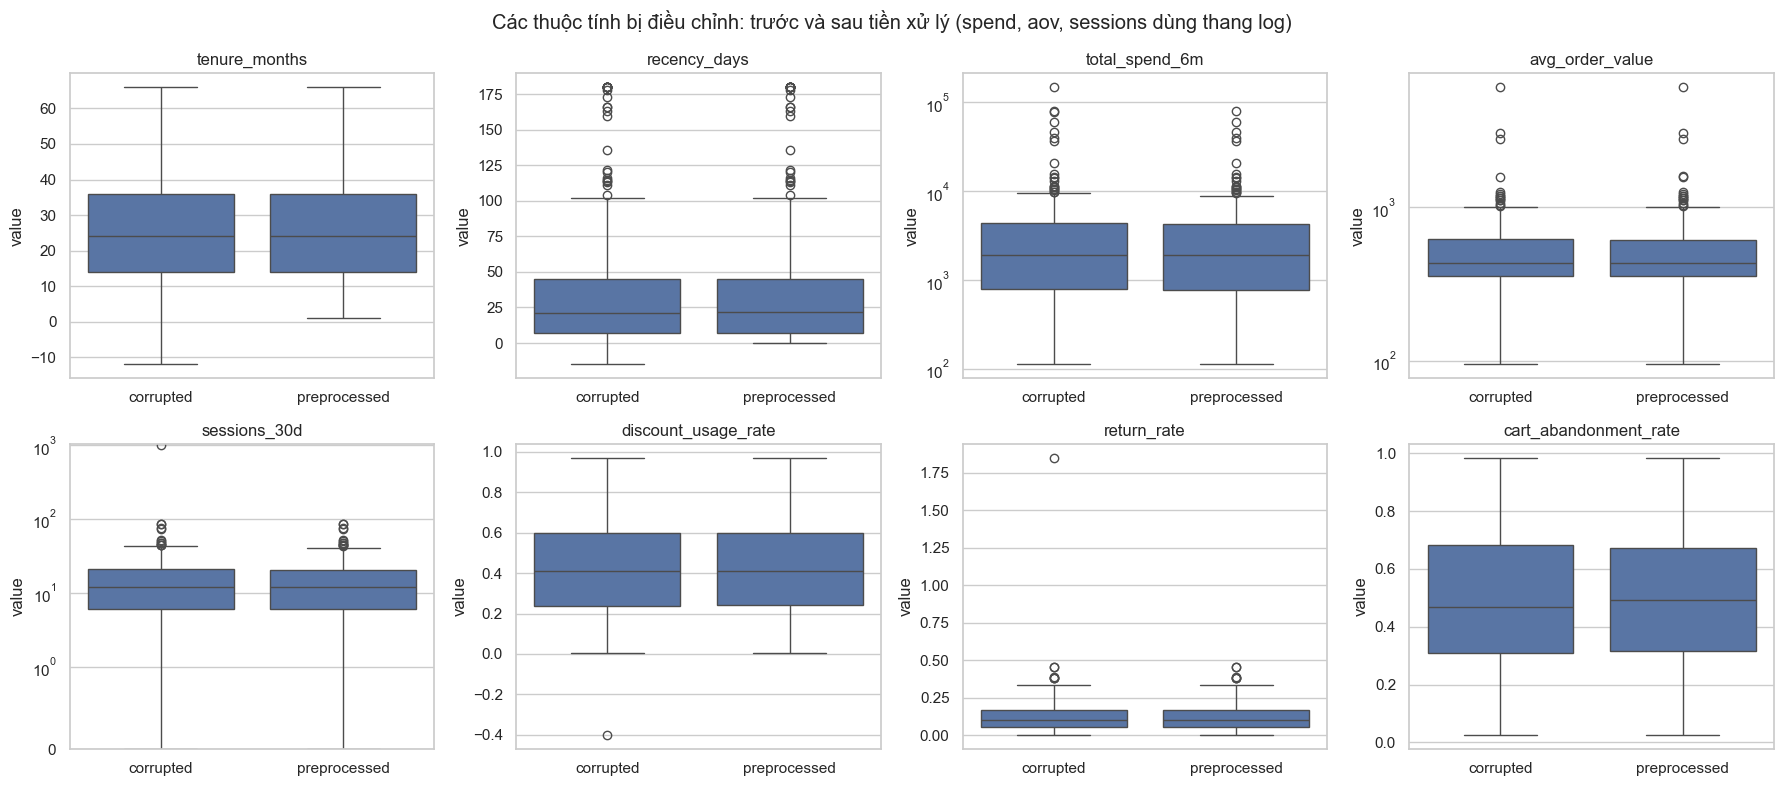

In [50]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, column in zip(axes.ravel(), affected_columns):
    long = pd.concat([
        pd.DataFrame({"value": raw_df[column], "version": "corrupted"}),
        pd.DataFrame({"value": preprocessed_df[column], "version": "preprocessed"}),
    ], ignore_index=True)
    sns.boxplot(data=long, x="version", y="value", ax=ax)
    ax.set_title(column)
    ax.set_xlabel("")
    if column in ["total_spend_6m", "avg_order_value"]:
        ax.set_yscale("log")
    elif column == "sessions_30d":
        # sessions có giá trị 0 nên dùng symlog, cắt trục tại 0 vì không có giá trị âm.
        ax.set_yscale("symlog", linthresh=1)
        ax.set_ylim(bottom=0)
for ax in axes.ravel()[len(affected_columns):]:
    ax.set_visible(False)
fig.suptitle("Các thuộc tính bị điều chỉnh: trước và sau tiền xử lý (spend, aov, sessions dùng thang log)")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "c_before_after_preprocessing.png", dpi=150)
plt.show()

**Nhận xét.** Số bản ghi giữ nguyên 220. Số ô thiếu giảm từ 33 về 0, số bản ghi vi phạm quy tắc giảm từ 7 về 0. Tổng cộng 40 ô bị điều chỉnh, tức 1.5% trong 2640 ô thuộc tính. Các ô này được liệt kê đầy đủ trong `results/preprocessing_changes.csv`.

Tác động lên thống kê:

- **`sessions_30d`:** std giảm từ 67.84 xuống 14.39 và max từ 999 xuống 86, do loại giá trị lỗi tracking.
- **`total_spend_6m`:** std giảm từ 13766 xuống 8442 và max từ 147995 xuống 79784, do sửa 2 lỗi đơn vị.
- **`return_rate`:** std giảm từ 0.147 xuống 0.091.
- **Trung vị của mọi cột** gần như không đổi. `cart_abandonment_rate` thay đổi nhiều nhất, từ 0.469 lên 0.492, do các giá trị điền theo nhóm khách ít đơn cao hơn trung vị toàn cục.

`total_spend_6m` vẫn có skewness 5.89 vì các khách VIP được giữ lại. Độ lệch này sẽ được xử lý bằng biến đổi log ở bước chuẩn bị đặc trưng.

**Đánh giá sau xử lý: sai số điền khuyết so với dữ liệu gốc.** Ô này dùng `customers_original.csv` sau khi quy trình đã hoàn tất, chỉ để đo chất lượng. Phương pháp đã chọn ở c.2 được so với median imputation toàn cục trên đúng các ô đã điền. Kết quả không được dùng để chọn lại phương pháp.

In [51]:
original_lookup = reference_df.set_index("customer_id")
global_medians = marked_df[NUMERIC_FEATURES].median()
imputation_eval = preprocessing_changes.assign(
    true_value=lambda t: [original_lookup.at[c, col] for c, col in zip(t["customer_id"], t["column"])],
    global_median=lambda t: t["column"].map(global_medians),
)
imputation_eval["abs_error_method"] = (imputation_eval["final_value"] - imputation_eval["true_value"]).abs()
imputation_eval["abs_error_global_median"] = (imputation_eval["global_median"] - imputation_eval["true_value"]).abs()
imputation_eval.groupby(["column", "method"]).agg(
    n_cells=("customer_id", "size"),
    mae_method=("abs_error_method", "mean"),
    mae_global_median=("abs_error_global_median", "mean"),
).round(3)

,,n_cells,mae_method,mae_global_median
column,method,,,
avg_order_value,spend_div_orders,15,26.208,217.262
cart_abandonment_rate,median_by_orders_group,18,0.145,0.144
discount_usage_rate,column_median,1,0.282,0.282
recency_days,column_median,1,11.000,11.000
return_rate,column_median,1,0.328,0.328
sessions_30d,column_median,1,3.000,3.000
tenure_months,column_median,1,5.000,5.000
total_spend_6m,orders_x_aov,2,0.000,804.000


**Nhận xét.**

- **`avg_order_value`:** điền theo `total_spend_6m` / `orders_6m` cho sai số tuyệt đối trung bình 26.2 nghìn đồng, so với 217.3 nếu dùng trung vị toàn cục. Sai số còn lại đến từ nhiễu trên `total_spend_6m` ở một số bản ghi.
- **`total_spend_6m` (2 ô lỗi đơn vị):** tính lại bằng `orders_6m` × `avg_order_value` cho sai số 0. Kết quả này chỉ có được vì trong mô phỏng, hai bản ghi này không bị nhiễu trên `avg_order_value`. Dữ liệu thực không đảm bảo điều đó.
- **`cart_abandonment_rate`:** điền theo trung vị nhóm số đơn cho MAE 0.145, gần như bằng trung vị toàn cục (0.144). **Giả thuyết rằng trung vị có điều kiện sẽ chính xác hơn không được ủng hộ trên 18 ô này.** Nguyên nhân là độ phân tán của `cart_abandonment_rate` trong từng nhóm vẫn lớn, khiến khác biệt giữa các trung vị nhóm không giúp dự đoán tốt hơn ở mức từng khách. Phương pháp được giữ nguyên vì đã chọn trước khi đánh giá. Nó không kém hơn median imputation và giữ được mối liên hệ giữa mức mua hàng và tỷ lệ bỏ giỏ ở mức nhóm.
- **5 ô điền bằng trung vị toàn cục:** mỗi cột chỉ có 1 ô, nên sai số chỉ mang tính minh họa.

## Câu d — Data Preparation

Đầu vào là `customers_preprocessed.csv`. Đầu ra là ma trận đặc trưng số, không còn NaN, dùng trực tiếp cho K-Means. Các bước được gói trong hàm `prepare_feature_matrix`, để ở câu e có thể áp dụng **cùng một phép biến đổi** cho cả nhánh baseline lẫn nhánh đã tiền xử lý, với cùng danh sách cột, cùng thứ tự và cùng cách chuẩn hóa.

### d.1. Lựa chọn thuộc tính

`customer_id`, `true_segment` và mọi cột metadata không được đưa vào ma trận. Trong 12 thuộc tính đầu vào, cần xem xét các cặp tương quan mạnh đã thấy ở b.6, lần này tính lại trên dữ liệu đã tiền xử lý.

In [52]:
prepared_input = pd.read_csv(DATA_DIR / "customers_preprocessed.csv")
assert prepared_input[INPUT_FEATURES].notna().all().all()

pre_spearman = prepared_input[NUMERIC_FEATURES].corr(method="spearman")
strong_pairs = correlated_pairs(prepared_input[NUMERIC_FEATURES].corr(), pre_spearman, threshold=0.5)
strong_pairs.round(3)

,feature_1,feature_2,pearson,spearman,abs_difference
0,orders_6m,total_spend_6m,0.791,0.935,0.144
1,orders_6m,category_diversity,0.353,0.614,0.261
2,total_spend_6m,avg_order_value,0.677,0.611,0.067
3,total_spend_6m,category_diversity,0.273,0.589,0.316
4,recency_days,orders_6m,-0.347,-0.586,0.239
5,recency_days,total_spend_6m,-0.240,-0.553,0.313


In [53]:
# Kiểm tra quan hệ định nghĩa trên thang log: log(spend) ≈ log(orders) + log(aov).
log_spend = np.log(prepared_input["total_spend_6m"])
log_orders_plus_aov = np.log(prepared_input["orders_6m"]) + np.log(prepared_input["avg_order_value"])
residual = log_spend - log_orders_plus_aov
print(f"corr(log spend, log orders + log aov) = {log_spend.corr(log_orders_plus_aov):.4f}")
print(f"Residual std = {residual.std():.4f}  (log spend std = {log_spend.std():.4f})")
print(f"Share of log-spend variance explained = {1 - residual.var() / log_spend.var():.4f}")

corr(log spend, log orders + log aov) = 0.9979
Residual std = 0.0827  (log spend std = 1.2611)
Share of log-spend variance explained = 0.9957


**Quyết định chọn thuộc tính.**

- **Bỏ `total_spend_6m`.** Trên thang log, `total_spend_6m` gần như bằng tổng tuyến tính của log `orders_6m` và log `avg_order_value`, như kết quả ô trên cho thấy. Nếu giữ cả ba, thông tin mua hàng bị tính hai lần trong khoảng cách Euclid. Hai thành phần được giữ lại vì mỗi thành phần mang một ý nghĩa riêng: tần suất mua (`orders_6m`) và giá trị mỗi lần mua (`avg_order_value`). Tổng chi tiêu chỉ là tích của chúng. Ngoài ra, `total_spend_6m` là cột chịu nhiễu trực tiếp, và 76 bản ghi lệch khỏi quan hệ định nghĩa (c.4) cho thấy cột này chứa sai số đo lường. `total_spend_6m` vẫn được giữ trong `customers_preprocessed.csv` để mô tả cụm ở câu e.
- **Giữ các cặp tương quan vừa phải**, như `orders_6m` với `category_diversity`, và `recency_days` với `orders_6m`. Các cặp này có tương quan Spearman khoảng |0.5–0.6| nhưng mỗi biến đo một khía cạnh khác nhau: độ rộng nhu cầu, mức độ gần đây, tần suất. Chúng không có quan hệ định nghĩa với nhau.
- **Giữ các biến còn lại.** `sessions_30d`, `discount_usage_rate`, `cart_abandonment_rate` và `return_rate` tương quan yếu với nhóm biến mua hàng. Đây chính là các biến giúp phân biệt các kiểu hành vi không thể hiện qua chi tiêu.
- **Giữ hai biến phân loại** theo yêu cầu, mã hóa one-hot. Ở b.3, chúng không có mức hiếm.

### d.2. Biến đổi, mã hóa và chuẩn hóa

**Biến đổi log1p** cho `recency_days`, `orders_6m`, `avg_order_value` và `sessions_30d`. Đây là các biến lệch phải với thang đo lớn. Ở c.4, log1p đưa skewness của chúng về gần 0 và giảm mạnh mức cách biệt của các điểm cực đoan. `log1p` được dùng thay `log` vì `recency_days` và `sessions_30d` có giá trị 0.

Các biến sau giữ nguyên thang đo:
- `tenure_months`: gần đối xứng.
- `category_diversity`: rời rạc trong khoảng 1–8, skewness khoảng 1.
- Ba biến tỷ lệ: bị chặn trong [0, 1]. Ở c.4, log1p gần như không thay đổi `return_rate`.

**So sánh StandardScaler và RobustScaler** trên các đặc trưng số sau biến đổi log:

In [54]:
MODEL_NUMERIC_FEATURES = [
    "tenure_months", "recency_days", "orders_6m", "avg_order_value", "sessions_30d",
    "discount_usage_rate", "return_rate", "category_diversity", "cart_abandonment_rate",
]
LOG_FEATURES = ["recency_days", "orders_6m", "avg_order_value", "sessions_30d"]
DROPPED_FEATURES = ["total_spend_6m"]
assert set(MODEL_NUMERIC_FEATURES) | set(DROPPED_FEATURES) == set(NUMERIC_FEATURES)


def transform_numeric(df):
    numeric = df[MODEL_NUMERIC_FEATURES].astype(float).copy()
    # log1p không xác định với x <= -1; cắt dưới tại 0 (không ảnh hưởng dữ liệu đã tiền xử lý vì không còn giá trị âm).
    numeric[LOG_FEATURES] = np.log1p(numeric[LOG_FEATURES].clip(lower=0))
    return numeric.rename(columns={c: f"log_{c}" for c in LOG_FEATURES})


log_numeric = transform_numeric(prepared_input)
scaler_comparison = pd.DataFrame({
    "std": log_numeric.std(),
    "iqr": log_numeric.quantile(0.75) - log_numeric.quantile(0.25),
    "max_abs_standard": np.abs(StandardScaler().fit_transform(log_numeric)).max(axis=0),
    "max_abs_robust": np.abs(RobustScaler().fit_transform(log_numeric)).max(axis=0),
    "std_after_robust": RobustScaler().fit_transform(log_numeric).std(axis=0, ddof=1),
})
scaler_comparison.round(3)

,std,iqr,max_abs_standard,max_abs_robust,std_after_robust
tenure_months,14.200,22.000,2.913,1.909,0.645
log_recency_days,1.269,1.755,2.362,1.787,0.723
log_orders_6m,0.775,1.204,3.429,2.260,0.644
log_avg_order_value,0.528,0.540,4.860,4.865,0.977
log_sessions_30d,0.910,1.110,2.702,2.310,0.820
discount_usage_rate,0.239,0.355,2.261,1.583,0.675
return_rate,0.091,0.115,3.636,3.054,0.786
category_diversity,1.775,3.000,2.978,2.000,0.592
cart_abandonment_rate,0.222,0.358,2.244,1.379,0.620


**Lựa chọn: RobustScaler.**

| | StandardScaler | RobustScaler |
|---|---|---|
| Tâm và thang đo | mean, std | median, IQR |
| Ảnh hưởng của ngoại lai | Mean và std bị kéo theo các điểm cực đoan, làm nén sự khác biệt giữa khách bình thường | Median và IQR gần như không bị ảnh hưởng bởi 5 khách VIP và đuôi tự nhiên còn giữ lại |
| Sau chuẩn hóa | Mọi biến có std = 1, đóng góp đều vào khoảng cách | std của từng biến khác nhau (bảng trên), nên mức đóng góp không hoàn toàn đều |
| Giá trị cực đoan | Bị thu nhỏ hơn | Vẫn hiển thị rõ là cực đoan, nhưng không làm méo thang đo của các điểm khác |

Dữ liệu sau tiền xử lý vẫn giữ các khách chi tiêu, tần suất cao và các bản ghi có nhiễu. Bước chuẩn hóa vì vậy nên dựa trên thống kê bền vững. Nhược điểm cần lưu ý: một biến có IQR nhỏ so với độ phân tán tổng thể sẽ có std sau chuẩn hóa lớn hơn 1, và do đó trọng số lớn hơn trong khoảng cách. Cột `std_after_robust` dùng để kiểm tra mức chênh này.

**Mã hóa one-hot.** `favorite_category` tạo 8 cột, `preferred_device` tạo 3 cột. Danh mục được cố định theo danh sách giá trị hợp lệ (`CATEGORIES`, `DEVICES`), không suy ra từ dữ liệu, để mọi nhánh có cùng số cột và cùng thứ tự. Không bỏ cột đầu (`drop=None`), để khoảng cách giữa mọi cặp mức là như nhau.

**Trọng số cho one-hot.** Hai khách khác danh mục yêu thích sẽ khác nhau ở **hai** cột one-hot. Phần đóng góp vào bình phương khoảng cách khi đó là 1² + 1² = 2. Nhân các cột one-hot với 1/√2 để một biến phân loại khác mức đóng góp đúng bằng 1, tương đương chênh lệch 1 IQR ở một biến số. Không có cơ sở để biến phân loại có trọng số lớn hơn biến số, vì ở a.2 chúng được thiết kế chỉ phụ thuộc yếu vào nhóm hành vi.

In [55]:
ONEHOT_WEIGHT = 1 / np.sqrt(2)


def fit_feature_transformers(df):
    scaler = RobustScaler().fit(transform_numeric(df))
    encoder = OneHotEncoder(categories=[CATEGORIES, DEVICES], sparse_output=False, handle_unknown="error")
    encoder.fit(df[CATEGORICAL_FEATURES])
    return {"scaler": scaler, "encoder": encoder}


def transform_features(df, transformers):
    # Áp dụng bộ biến đổi đã fit: log1p + RobustScaler cho biến số, one-hot có trọng số cho biến phân loại.
    numeric = transform_numeric(df)
    scaled_numeric = pd.DataFrame(transformers["scaler"].transform(numeric), columns=numeric.columns, index=df.index)

    encoder = transformers["encoder"]
    onehot = encoder.transform(df[CATEGORICAL_FEATURES]) * ONEHOT_WEIGHT
    onehot_columns = [name.replace(" ", "_").replace("&", "and") for name in encoder.get_feature_names_out()]
    encoded = pd.DataFrame(onehot, columns=onehot_columns, index=df.index)
    return pd.concat([scaled_numeric, encoded], axis=1)


def prepare_feature_matrix(df):
    transformers = fit_feature_transformers(df)
    return transform_features(df, transformers), transformers


feature_matrix, fitted_transformers = prepare_feature_matrix(prepared_input)
FEATURE_COLUMNS = list(feature_matrix.columns)
feature_matrix.head()

,tenure_months,log_recency_days,log_orders_6m,log_avg_order_value,log_sessions_30d,discount_usage_rate,return_rate,category_diversity,cart_abandonment_rate,favorite_category_Fashion,favorite_category_Electronics,favorite_category_Home_and_Living,favorite_category_Beauty_and_Health,favorite_category_Groceries,favorite_category_Sports_and_Outdoor,favorite_category_Books_and_Stationery,favorite_category_Mother_and_Baby,preferred_device_Mobile_App,preferred_device_Mobile_Web,preferred_device_Desktop
0,-1.045455,0.170123,-0.424283,0.042742,0.341808,1.071932,0.407809,-0.333333,0.565035,0.0,0.000000,0.707107,0.000000,0.0,0.000000,0.0,0.0,0.707107,0.0,0.000000
1,0.681818,-0.996936,0.727150,0.350140,-0.557571,-0.214386,-0.720174,0.666667,-1.015385,0.0,0.707107,0.000000,0.000000,0.0,0.000000,0.0,0.0,0.707107,0.0,0.000000
2,0.727273,0.955610,-0.761056,-0.221204,1.034569,-0.634697,1.214751,-0.333333,0.956643,0.0,0.000000,0.000000,0.000000,0.0,0.707107,0.0,0.0,0.000000,0.0,0.707107
3,0.954545,0.047522,1.108830,0.309091,0.128892,-0.623413,-0.850325,0.666667,-0.514685,0.0,0.707107,0.000000,0.000000,0.0,0.000000,0.0,0.0,0.707107,0.0,0.000000
4,1.318182,-1.160897,0.912489,0.186764,-0.331211,-0.067701,-0.642082,0.333333,-0.539860,0.0,0.000000,0.000000,0.707107,0.0,0.000000,0.0,0.0,0.707107,0.0,0.000000


In [56]:
def check_feature_matrix(matrix, expected_columns):
    assert list(matrix.columns) == expected_columns
    assert len(matrix) == N_CUSTOMERS
    values = matrix.to_numpy(dtype=float)
    assert not np.isnan(values).any() and np.isfinite(values).all()
    forbidden = {"customer_id", "true_segment"} | (set(simulation_metadata.columns) - {"customer_id"})
    assert not forbidden & set(matrix.columns)
    assert not set(DROPPED_FEATURES) & set(matrix.columns)
    print(f"Feature matrix OK: shape {matrix.shape}, no NaN/inf, no ID/label/metadata columns")


check_feature_matrix(feature_matrix, FEATURE_COLUMNS)

n_numeric_out = len(MODEL_NUMERIC_FEATURES)
n_onehot_out = len(FEATURE_COLUMNS) - n_numeric_out
print(f"\nInput attributes: {len(INPUT_FEATURES)} ({len(NUMERIC_FEATURES)} numeric + {len(CATEGORICAL_FEATURES)} categorical)")
print(f"  - dropped (redundant): {DROPPED_FEATURES}  -> -{len(DROPPED_FEATURES)}")
print(f"  - favorite_category -> {len(CATEGORIES)} one-hot columns, preferred_device -> {len(DEVICES)} one-hot columns"
      f"  -> +{n_onehot_out - len(CATEGORICAL_FEATURES)}")
print(f"Final feature dimensions: {len(FEATURE_COLUMNS)} ({n_numeric_out} numeric + {n_onehot_out} one-hot)\n")
for i, column in enumerate(FEATURE_COLUMNS, 1):
    print(f"{i:2d}. {column}")

Feature matrix OK: shape (220, 20), no NaN/inf, no ID/label/metadata columns

Input attributes: 12 (10 numeric + 2 categorical)
  - dropped (redundant): ['total_spend_6m']  -> -1
  - favorite_category -> 8 one-hot columns, preferred_device -> 3 one-hot columns  -> +9
Final feature dimensions: 20 (9 numeric + 11 one-hot)

 1. tenure_months
 2. log_recency_days
 3. log_orders_6m
 4. log_avg_order_value
 5. log_sessions_30d
 6. discount_usage_rate
 7. return_rate
 8. category_diversity
 9. cart_abandonment_rate
10. favorite_category_Fashion
11. favorite_category_Electronics
12. favorite_category_Home_and_Living
13. favorite_category_Beauty_and_Health
14. favorite_category_Groceries
15. favorite_category_Sports_and_Outdoor
16. favorite_category_Books_and_Stationery
17. favorite_category_Mother_and_Baby
18. preferred_device_Mobile_App
19. preferred_device_Mobile_Web
20. preferred_device_Desktop


In [57]:
contribution = pd.DataFrame({
    "mean": feature_matrix.mean(),
    "std": feature_matrix.std(),
    "min": feature_matrix.min(),
    "max": feature_matrix.max(),
})
contribution["share_of_total_variance"] = feature_matrix.var() / feature_matrix.var().sum()
contribution.round(3)

,mean,std,min,max,share_of_total_variance
tenure_months,0.033,0.645,-1.045,1.909,0.075
log_recency_days,-0.082,0.723,-1.787,1.176,0.095
log_orders_6m,0.058,0.644,-0.761,2.260,0.075
log_avg_order_value,0.125,0.977,-2.807,4.865,0.173
log_sessions_30d,-0.101,0.820,-2.310,1.712,0.121
discount_usage_rate,0.060,0.675,-1.137,1.583,0.082
return_rate,0.203,0.786,-0.850,3.054,0.112
category_diversity,0.242,0.592,-0.333,2.000,0.063
cart_abandonment_rate,-0.010,0.620,-1.303,1.379,0.069
favorite_category_Fashion,0.125,0.271,0.000,0.707,0.013


**Nhận xét.**

- **Kiểm tra quan hệ định nghĩa.** Trên thang log, log `orders_6m` + log `avg_order_value` giải thích 99.57% phương sai của log `total_spend_6m` (tương quan 0.998). Điều này xác nhận `total_spend_6m` gần như không mang thông tin riêng.
- **Số chiều.** Ma trận cuối có 20 chiều: 12 thuộc tính − 1 cột bỏ đi + 9 cột tăng thêm do one-hot (11 cột thay cho 2 biến phân loại).
- **Thang đo sau RobustScaler.** Std của 9 đặc trưng số nằm trong khoảng 0.59–0.98, tức chênh lệch dưới 2 lần, thay vì chênh khoảng 10⁵ lần như ở dữ liệu gốc. Riêng `log_avg_order_value` có std 0.977 và chiếm 17.3% tổng phương sai, nhiều nhất trong các đặc trưng. Nguyên nhân là IQR của biến này hẹp (0.54) trong khi đuôi phải có các khách VIP, với giá trị chuẩn hóa lớn nhất là 4.87. Đây là nhược điểm của RobustScaler đã nêu: biến này sẽ có ảnh hưởng lớn hơn mức trung bình đến khoảng cách.
- **Biến phân loại.** 11 cột one-hot chiếm tổng cộng khoảng 13% phương sai. Đây là mức phù hợp với vai trò phụ trợ của chúng.

### d.3. PCA để trực quan hóa

PCA chỉ dùng để quan sát dữ liệu trên mặt phẳng 2D. K-Means ở câu e chạy trên toàn bộ ma trận đặc trưng. Các điểm được tô màu theo việc có bị IQR (k = 3) đánh dấu ở c.3 hay không, là thông tin quan sát được từ dữ liệu, không dùng metadata.

In [58]:
pca_full = PCA(random_state=SEED).fit(feature_matrix)
explained = pd.DataFrame({
    "explained_variance_ratio": pca_full.explained_variance_ratio_,
    "cumulative": np.cumsum(pca_full.explained_variance_ratio_),
}, index=[f"PC{i}" for i in range(1, len(FEATURE_COLUMNS) + 1)])
print(explained.head(8).round(3).to_string())

loadings = pd.DataFrame(pca_full.components_[:2].T, index=FEATURE_COLUMNS, columns=["PC1", "PC2"])
print("\nTop loadings:")
for pc in ["PC1", "PC2"]:
    top = loadings[pc].abs().sort_values(ascending=False).head(5).index
    print(pc, ", ".join(f"{c} ({loadings.at[c, pc]:+.2f})" for c in top))

     explained_variance_ratio  cumulative
PC1                     0.269       0.269
PC2                     0.147       0.416
PC3                     0.125       0.541
PC4                     0.096       0.637
PC5                     0.080       0.717
PC6                     0.054       0.771
PC7                     0.043       0.814
PC8                     0.039       0.853

Top loadings:
PC1 log_avg_order_value (+0.56), log_orders_6m (+0.41), log_recency_days (-0.39), category_diversity (+0.29), return_rate (-0.27)
PC2 log_avg_order_value (+0.71), log_recency_days (+0.30), cart_abandonment_rate (+0.30), discount_usage_rate (-0.27), tenure_months (-0.26)


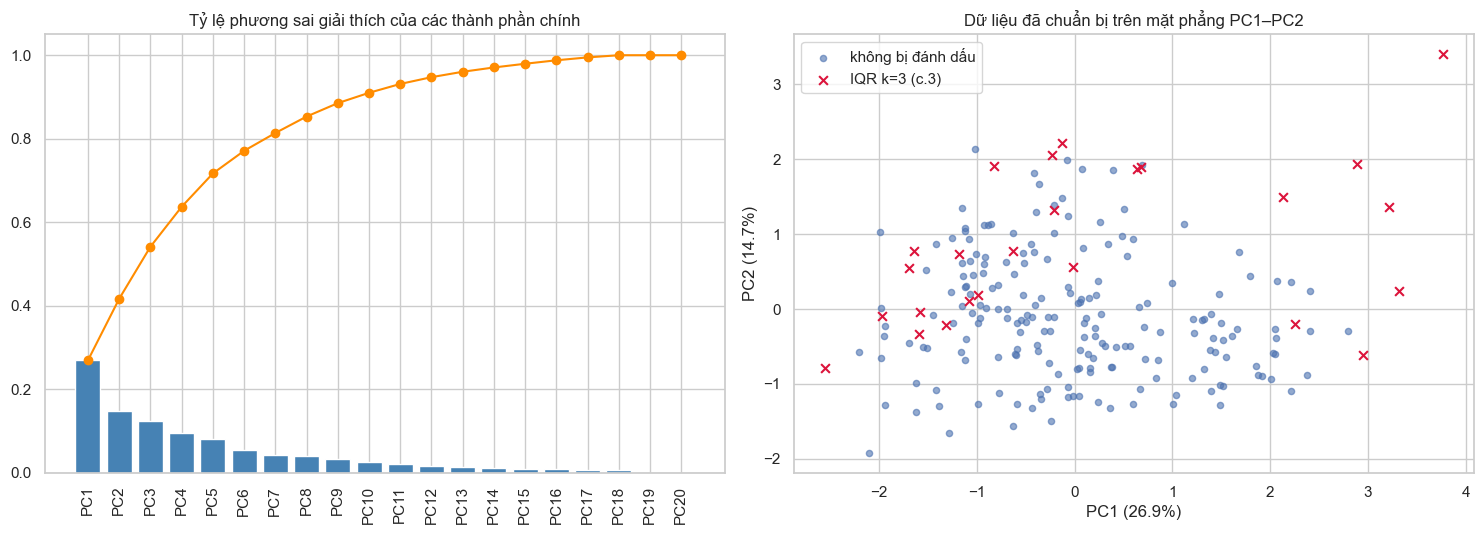

In [59]:
pca_2d = pca_full.transform(feature_matrix)[:, :2]
is_extreme = extreme_flags.any(axis=1).to_numpy()

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
axes[0].bar(explained.index, explained["explained_variance_ratio"], color="steelblue")
axes[0].plot(explained.index, explained["cumulative"], color="darkorange", marker="o")
axes[0].set_title("Tỷ lệ phương sai giải thích của các thành phần chính")
axes[0].tick_params(axis="x", rotation=90)

axes[1].scatter(pca_2d[~is_extreme, 0], pca_2d[~is_extreme, 1], s=20, alpha=0.6, label="không bị đánh dấu")
axes[1].scatter(pca_2d[is_extreme, 0], pca_2d[is_extreme, 1], s=40, color="crimson", marker="x",
                label="IQR k=3 (c.3)")
axes[1].set_xlabel(f"PC1 ({explained.iloc[0, 0]:.1%})")
axes[1].set_ylabel(f"PC2 ({explained.iloc[1, 0]:.1%})")
axes[1].set_title("Dữ liệu đã chuẩn bị trên mặt phẳng PC1–PC2")
axes[1].legend()
fig.tight_layout()
fig.savefig(FIGURE_DIR / "d_pca_overview.png", dpi=150)
plt.show()

**Nhận xét.**

- **Phương sai giải thích.** PC1 và PC2 giải thích 41.6% phương sai, 5 thành phần đầu giải thích 71.7%. Mặt phẳng 2D vì vậy chỉ thể hiện một phần cấu trúc dữ liệu.
- **Ý nghĩa PC1 và PC2.** PC1 chủ yếu phản ánh mức độ mua hàng: `log_avg_order_value` (+0.56), `log_orders_6m` (+0.41) và `log_recency_days` (−0.39). PC2 cũng bị `log_avg_order_value` chi phối (+0.71), phù hợp với nhận xét về tỷ trọng phương sai của biến này ở trên.
- **Không thấy cụm tách rời.** Trên mặt phẳng PC1–PC2, các điểm tạo thành một đám liên tục, không có nhóm tách biệt rõ ràng. Điều này phù hợp với thiết kế các nhóm chồng lấn ở câu a.
- **Vị trí các điểm bị IQR đánh dấu.** Phần lớn các điểm có PC1 lớn nhất, ở góc phải phía trên, là khách có giá trị đơn và số đơn cao. Các điểm bị đánh dấu do recency gần 180 ngày nằm ở phía PC1 âm. Sau biến đổi log và RobustScaler, không còn điểm nào cách biệt hẳn khỏi phần còn lại như ở dữ liệu gốc.

### d.4. Lưu dữ liệu đã chuẩn bị

`customers_prepared.csv` chỉ chứa các cột đặc trưng, theo đúng thứ tự dòng của `customers_preprocessed.csv`. `customer_id` được lưu riêng trong `prepared_customer_ids.csv` để truy xuất kết quả phân cụm, và không tham gia tính khoảng cách.

In [60]:
prepared_path = DATA_DIR / "customers_prepared.csv"
id_mapping_path = DATA_DIR / "prepared_customer_ids.csv"
feature_matrix.to_csv(prepared_path, index=False)
prepared_input[["customer_id"]].rename_axis("row_index").reset_index().to_csv(id_mapping_path, index=False)

reloaded_matrix = pd.read_csv(prepared_path)
check_feature_matrix(reloaded_matrix, FEATURE_COLUMNS)
assert np.allclose(reloaded_matrix.to_numpy(), feature_matrix.to_numpy())
assert (pd.read_csv(id_mapping_path)["customer_id"] == prepared_input["customer_id"]).all()
print(f"Saved {prepared_path.relative_to(PROJECT_DIR)} {reloaded_matrix.shape} and {id_mapping_path.relative_to(PROJECT_DIR)}")

Feature matrix OK: shape (220, 20), no NaN/inf, no ID/label/metadata columns
Saved data\customers_prepared.csv (220, 20) and data\prepared_customer_ids.csv


## Câu e — Phân cụm và đánh giá

### e.1. Thiết kế thí nghiệm đối chứng

| | Nhánh A — Baseline | Nhánh B — Processed |
|---|---|---|
| Dữ liệu nguồn | `customers_corrupted.csv` | `customers_preprocessed.csv` (câu c) |
| Giá trị thiếu | Điền trung vị (biến số) / mode (biến phân loại) | Theo quy trình câu c |
| Giá trị không hợp lệ, ngoại lai | Giữ nguyên | Sửa theo quy tắc nghiệp vụ (câu c) |
| Đặc trưng | 20 đặc trưng ở câu d | Giống A |
| Biến đổi và chuẩn hóa | `transform_features` với **cùng** bộ scaler/encoder | Giống A |
| K-Means | `n_init=20`, `random_state=42`, cùng k | Giống A |

Để K-Means chạy được, nhánh A chỉ trải qua các bước tối thiểu: điền khuyết, cùng phép log1p, mã hóa và chuẩn hóa như nhánh B. Phép log1p cần cắt dưới tại 0, nên giá trị `recency_days` = −15 trở thành 0. Đây là ràng buộc kỹ thuật của hàm log, không phải bước xử lý ngoại lai. Các giá trị lỗi khác được giữ nguyên: `sessions_30d` = 999, `return_rate` = 1.85, `discount_usage_rate` = −0.40, `tenure_months` = −12.

`total_spend_6m` không nằm trong tập đặc trưng của cả hai nhánh (câu d). Vì vậy, 2 lỗi chi tiêu ×100 không tác động trực tiếp lên khoảng cách ở nhánh A.

**Hệ quy chiếu chuẩn hóa.** Bộ scaler và encoder được fit một lần ở câu d trên dữ liệu đã tiền xử lý, rồi áp dụng nguyên vẹn cho cả hai nhánh. Do đó, cùng một giá trị gốc được ánh xạ thành cùng một giá trị đặc trưng ở hai nhánh. Bảng dưới so sánh với phương án fit scaler trên dữ liệu baseline, để kiểm tra lựa chọn này có làm thay đổi thang đo đáng kể hay không.

In [61]:
KMEANS_PARAMS = {"n_init": 20, "random_state": SEED}
K_RANGE = range(2, 9)


def minimal_baseline_preparation(df):
    # Chỉ điền khuyết để K-Means chạy được; không sửa giá trị không hợp lệ hay ngoại lai.
    baseline = df.copy()
    for column in NUMERIC_FEATURES:
        baseline[column] = baseline[column].fillna(baseline[column].median())
    for column in CATEGORICAL_FEATURES:
        baseline[column] = baseline[column].fillna(baseline[column].mode()[0])
    return baseline


baseline_df = minimal_baseline_preparation(pd.read_csv(DATA_DIR / "customers_corrupted.csv"))
assert (baseline_df["customer_id"].to_numpy() == prepared_input["customer_id"].to_numpy()).all()

X_baseline = transform_features(baseline_df, fitted_transformers)
X_processed = transform_features(prepared_input, fitted_transformers)
check_feature_matrix(X_baseline, FEATURE_COLUMNS)
check_feature_matrix(X_processed, FEATURE_COLUMNS)
assert np.allclose(X_processed.to_numpy(), pd.read_csv(DATA_DIR / "customers_prepared.csv").to_numpy())
assert list(X_baseline.columns) == list(X_processed.columns) and X_baseline.shape == X_processed.shape

branch_matrices = {"A_baseline": X_baseline, "B_processed": X_processed}
print("Both branches:", X_baseline.shape, "| identical columns and order:", list(X_baseline.columns) == FEATURE_COLUMNS)

baseline_fit_scaler = RobustScaler().fit(transform_numeric(baseline_df))
pd.DataFrame({
    "center_fit_processed": fitted_transformers["scaler"].center_,
    "center_fit_baseline": baseline_fit_scaler.center_,
    "scale_fit_processed": fitted_transformers["scaler"].scale_,
    "scale_fit_baseline": baseline_fit_scaler.scale_,
}, index=transform_numeric(baseline_df).columns).round(4)

Feature matrix OK: shape (220, 20), no NaN/inf, no ID/label/metadata columns
Feature matrix OK: shape (220, 20), no NaN/inf, no ID/label/metadata columns
Both branches: (220, 20) | identical columns and order: True


,center_fit_processed,center_fit_baseline,scale_fit_processed,scale_fit_baseline
tenure_months,24.0000,24.0000,22.0000,22.0000
log_recency_days,3.1355,3.0900,1.7546,1.7546
log_orders_6m,1.6094,1.6094,1.2040,1.2040
log_avg_order_value,6.0831,6.0791,0.5400,0.5092
log_sessions_30d,2.5649,2.5649,1.1102,1.1451
discount_usage_rate,0.4090,0.4085,0.3545,0.3605
return_rate,0.1000,0.1000,0.1153,0.1155
category_diversity,2.0000,2.0000,3.0000,3.0000
cart_abandonment_rate,0.4920,0.4690,0.3575,0.3258


**Nhận xét.** Hai nhánh có cùng 20 cột, cùng thứ tự và cùng bộ biến đổi; `X_processed` trùng khớp với `customers_prepared.csv`.

Nếu fit scaler trên dữ liệu baseline thay vì dữ liệu processed, median và IQR chỉ thay đổi nhỏ. Thay đổi lớn nhất là:
- Tâm của `cart_abandonment_rate`: 0.492 so với 0.469.
- Thang đo của `cart_abandonment_rate`: 0.358 so với 0.326.
- Thang đo của `log_avg_order_value`: 0.540 so với 0.509.

Nhờ RobustScaler, việc chọn hệ quy chiếu nào gần như không ảnh hưởng đến kết quả. Các giá trị lỗi của baseline (ví dụ 999 phiên) không làm lệch thang đo, mà hiện ra đúng là những điểm cực đoan trong không gian đặc trưng.

### e.2. Khảo sát số cụm k từ 2 đến 8

Với mỗi nhánh và mỗi k, ghi lại inertia (dùng cho Elbow), Silhouette và Davies–Bouldin. ARI **không** được tính ở bước này.

**Quy tắc chọn k cho thực nghiệm chính** (đặt trước khi xem kết quả): chọn k có Silhouette cao nhất trên nhánh B, vì đây là nhánh dữ liệu sẽ được dùng thực tế, rồi áp dụng cùng k đó cho nhánh A. Elbow và Davies–Bouldin dùng để kiểm tra chéo. Ngoài ra, có một **thực nghiệm bổ sung với k = 4**, dựa trên thông tin thiết kế giả lập. Đây không phải lựa chọn theo tiêu chí không giám sát.

In [62]:
def fit_kmeans(X, k):
    model = KMeans(n_clusters=k, **KMEANS_PARAMS).fit(X)
    labels = model.labels_
    return model, {
        "k": k,
        "inertia": model.inertia_,
        "silhouette": silhouette_score(X, labels),
        "davies_bouldin": davies_bouldin_score(X, labels),
        "cluster_sizes": "/".join(map(str, sorted(np.bincount(labels), reverse=True))),
        "min_cluster_size": int(np.bincount(labels).min()),
    }


k_survey = pd.DataFrame([
    {"branch": branch, **fit_kmeans(X, k)[1]}
    for branch, X in branch_matrices.items() for k in K_RANGE
])
k_survey.to_csv(RESULT_DIR / "k_selection.csv", index=False)
k_survey.round(4)

,branch,k,inertia,silhouette,davies_bouldin,cluster_sizes,min_cluster_size
0,A_baseline,2,1215.2863,0.1768,1.7801,160/60,60
1,A_baseline,3,993.8719,0.1880,1.2336,158/61/1,1
2,A_baseline,4,884.2265,0.1491,1.5838,110/55/54/1,1
3,A_baseline,5,795.1831,0.1503,1.5502,66/52/51/50/1,1
4,A_baseline,6,750.3832,0.1418,1.5589,56/48/48/47/20/1,1
5,A_baseline,7,717.8144,0.1361,1.6096,47/47/45/33/26/21/1,1
6,A_baseline,8,685.9572,0.1309,1.6367,53/43/41/36/20/18/8/1,1
7,B_processed,2,983.0389,0.1908,1.7203,162/58,58
8,B_processed,3,875.1678,0.1521,2.0864,111/56/53,53
9,B_processed,4,784.2978,0.1534,1.8965,65/55/51/49,49


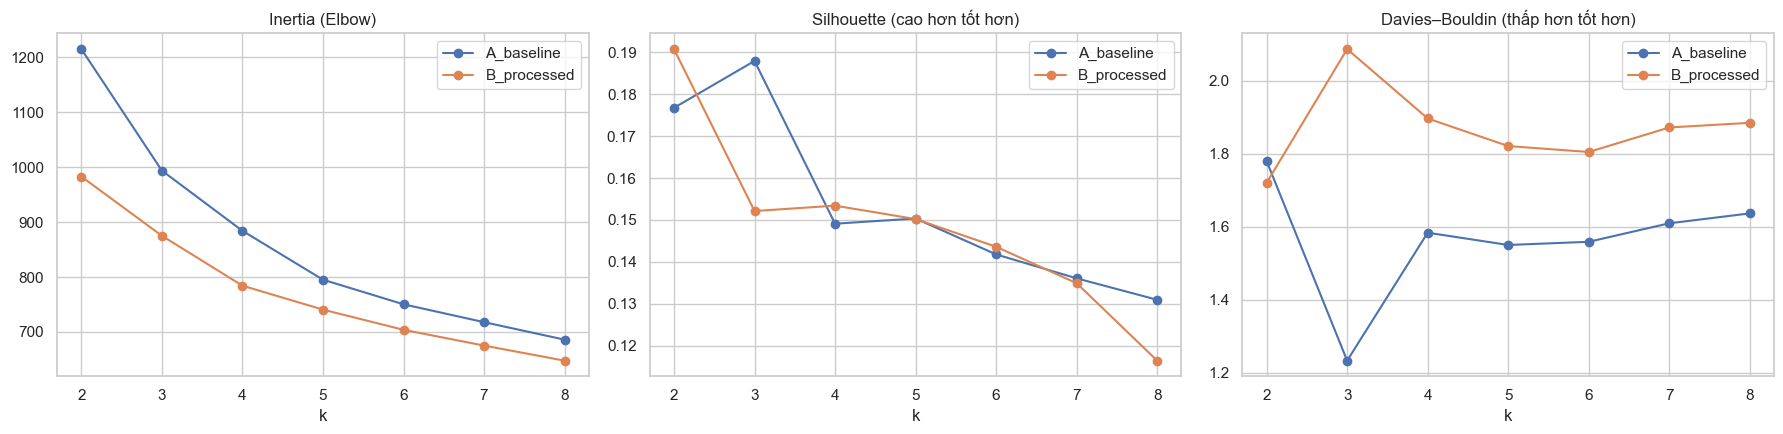

Main k (max silhouette on B_processed): 2
Davies-Bouldin minimum on B_processed at k = 2


In [63]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for branch, group in k_survey.groupby("branch"):
    for ax, metric in zip(axes, ["inertia", "silhouette", "davies_bouldin"]):
        ax.plot(group["k"], group[metric], marker="o", label=branch)
titles = ["Inertia (Elbow)", "Silhouette (cao hơn tốt hơn)", "Davies–Bouldin (thấp hơn tốt hơn)"]
for ax, title in zip(axes, titles):
    ax.set_title(title)
    ax.set_xlabel("k")
    ax.legend()
fig.tight_layout()
fig.savefig(FIGURE_DIR / "e_k_selection.png", dpi=150)
plt.show()

processed_survey = k_survey[k_survey["branch"] == "B_processed"].set_index("k")
K_MAIN = int(processed_survey["silhouette"].idxmax())
K_DESIGN = 4
print(f"Main k (max silhouette on B_processed): {K_MAIN}")
print(f"Davies-Bouldin minimum on B_processed at k = {int(processed_survey['davies_bouldin'].idxmin())}")

**Nhận xét về lựa chọn k.**

- **Nhánh B:**
  - Silhouette cao nhất ở k = 2 (0.191), giảm xuống khoảng 0.15 với k = 3–5 và còn 0.116 ở k = 8.
  - Davies–Bouldin cũng thấp nhất ở k = 2 (1.720).
  - Inertia giảm đều, không có điểm gãy rõ. Mức giảm là 108 từ k = 2 sang 3, 91 từ 3 sang 4, rồi chỉ 44 từ 4 sang 5. Đây là một khuỷu yếu ở k = 4.
  - Theo quy tắc đã đặt, **k = 2 là k của thực nghiệm chính**.
  - Mọi giá trị Silhouette đều thấp (< 0.2), phù hợp với thiết kế các nhóm chồng lấn ở câu a (silhouette của nhãn giả lập là 0.177).
- **Nhánh A:**
  - Với mọi k ≥ 3, luôn có một cụm chỉ gồm 1 bản ghi (`min_cluster_size` = 1).
  - Silhouette của A đạt đỉnh ở k = 3 (0.188) và Davies–Bouldin thấp bất thường ở k = 3 (1.234). Cả hai đều do cụm 1 phần tử này, vì một điểm cô lập nằm rất xa các điểm khác làm hai chỉ số "đẹp" lên mà không phản ánh cấu trúc khách hàng.
  - Nếu chọn k theo baseline, ta sẽ chọn sai vì lỗi dữ liệu.

### e.3. Kết quả phân cụm của hai nhánh

Huấn luyện K-Means với `K_MAIN` (thực nghiệm chính) và `K_DESIGN` = 4 (thực nghiệm bổ sung) trên cả hai nhánh. ARI được tính **sau khi** đã có nhãn cụm, bằng `true_segment` đọc từ metadata. Ngoài ra, có một dòng **tham chiếu**: dữ liệu gốc sạch đi qua cùng bộ biến đổi và cùng k. Dòng này chỉ để biết mức chất lượng có thể đạt được khi không có lỗi dữ liệu.

In [64]:
# Thí nghiệm k=4 luôn được chạy (kể cả khi K_MAIN = 4) để các bước sau có cấu trúc cố định.
experiments = [("main_unsupervised_k", K_MAIN), ("supplementary_design_k4", K_DESIGN)]

X_clean_reference = transform_features(reference_df, fitted_transformers)
check_feature_matrix(X_clean_reference, FEATURE_COLUMNS)
evaluated_matrices = {**branch_matrices, "reference_clean_original": X_clean_reference}

cluster_labels = {}
result_rows = []
for experiment, k in experiments:
    for branch, X in evaluated_matrices.items():
        model, metrics = fit_kmeans(X, k)
        cluster_labels[(experiment, branch)] = model.labels_
        result_rows.append({"experiment": experiment, "branch": branch, **metrics})
clustering_results = pd.DataFrame(result_rows)

Feature matrix OK: shape (220, 20), no NaN/inf, no ID/label/metadata columns


In [65]:
# ARI chỉ được tính sau khi phân cụm xong; nhãn giả lập không tham gia huấn luyện hay chọn k.
true_segments = simulation_metadata.set_index("customer_id").loc[prepared_input["customer_id"], "true_segment"].to_numpy()
clustering_results["ari_vs_true_segment"] = [
    adjusted_rand_score(true_segments, cluster_labels[(row.experiment, row.branch)])
    for row in clustering_results.itertuples()
]
clustering_results.to_csv(RESULT_DIR / "clustering_metrics.csv", index=False)

# Lưu nhãn cụm theo customer_id để truy xuất kết quả và để kiểm chứng lại từ đĩa.
saved_labels = pd.DataFrame({"customer_id": prepared_input["customer_id"]})
for (experiment, branch), labels in cluster_labels.items():
    saved_labels[f"{experiment}__{branch}"] = labels
saved_labels.to_csv(RESULT_DIR / "cluster_labels.csv", index=False)
clustering_results.round(4)

,experiment,branch,k,inertia,silhouette,davies_bouldin,cluster_sizes,min_cluster_size,ari_vs_true_segment
0,main_unsupervised_k,A_baseline,2,1215.2863,0.1768,1.7801,160/60,60,0.2859
1,main_unsupervised_k,B_processed,2,983.0389,0.1908,1.7203,162/58,58,0.2911
2,main_unsupervised_k,reference_clean_original,2,951.0891,0.1738,1.7543,160/60,60,0.3166
3,supplementary_design_k4,A_baseline,4,884.2265,0.1491,1.5838,110/55/54/1,1,0.4950
4,supplementary_design_k4,B_processed,4,784.2978,0.1534,1.8965,65/55/51/49,49,0.6435
5,supplementary_design_k4,reference_clean_original,4,752.1700,0.1610,1.9216,63/55/53/49,49,0.7151


In [66]:
agreement = pd.DataFrame([{
    "experiment": experiment,
    "k": k,
    "ari_A_vs_B": adjusted_rand_score(cluster_labels[(experiment, "A_baseline")], cluster_labels[(experiment, "B_processed")]),
    "ari_B_vs_clean_reference": adjusted_rand_score(cluster_labels[(experiment, "B_processed")],
                                                    cluster_labels[(experiment, "reference_clean_original")]),
    "ari_A_vs_clean_reference": adjusted_rand_score(cluster_labels[(experiment, "A_baseline")],
                                                    cluster_labels[(experiment, "reference_clean_original")]),
} for experiment, k in experiments])
agreement.round(4)

,experiment,k,ari_A_vs_B,ari_B_vs_clean_reference,ari_A_vs_clean_reference
0,main_unsupervised_k,2,0.9249,0.9249,0.9252
1,supplementary_design_k4,4,0.6135,0.9050,0.5951


**Nhận xét — thực nghiệm chính (k = 2).**

| Chỉ số | A (baseline) | B (processed) | Tham chiếu dữ liệu sạch |
|---|---|---|---|
| Silhouette | 0.177 | 0.191 | 0.174 |
| Davies–Bouldin | 1.780 | 1.720 | 1.754 |
| ARI so với nhãn giả lập | 0.286 | 0.291 | 0.317 |

- Nhánh B tốt hơn nhánh A ở cả ba chỉ số, nhưng mức chênh nhỏ.
- Hai nhánh gán cụm gần như giống nhau: ARI giữa A và B là 0.925.
- Với k = 2, K-Means chủ yếu tách nhóm khách mua nhiều ra khỏi phần còn lại. Ranh giới này đủ rõ để các lỗi dữ liệu không làm thay đổi đáng kể.
- ARI chỉ khoảng 0.3, vì 2 cụm không thể tái hiện 4 nhóm giả lập.
- Silhouette của B cao hơn cả tham chiếu sạch (0.191 so với 0.174). Không nên hiểu là tiền xử lý tạo ra dữ liệu "tốt hơn dữ liệu thật". Mức chênh nhỏ, và có thể do các giá trị được điền bằng trung vị nằm gần tâm cụm hơn giá trị thật.

**Nhận xét — thực nghiệm bổ sung (k = 4, theo thiết kế giả lập).**

| Chỉ số | A (baseline) | B (processed) | Tham chiếu dữ liệu sạch |
|---|---|---|---|
| Kích thước cụm | 110/55/54/1 | 65/55/51/49 | 63/55/53/49 |
| Silhouette | 0.149 | 0.153 | 0.161 |
| Davies–Bouldin | 1.584 | 1.896 | 1.922 |
| ARI so với nhãn giả lập | 0.495 | 0.644 | 0.715 |

- Tiền xử lý tạo khác biệt rõ rệt nhất ở ARI: từ 0.495 lên 0.644. Mức tương đồng với kết quả trên dữ liệu sạch cũng tăng từ 0.595 lên 0.905.
- **Davies–Bouldin của B lại kém hơn A** (1.896 so với 1.584). Đây không phải dấu hiệu tiền xử lý làm hại. Davies–Bouldin lấy trung bình, trên từng cụm, của tỷ lệ (độ phân tán nội cụm) / (khoảng cách giữa tâm cụm). Cụm 1 phần tử của A có độ phân tán bằng 0 và nằm rất xa, nên kéo chỉ số trung bình xuống. Giá trị của B (1.896) gần với tham chiếu sạch (1.922), cho thấy đó là mức tự nhiên của 4 nhóm chồng lấn.
- Ví dụ này cho thấy các chỉ số dựa trên khoảng cách có thể "thưởng" cho việc tách riêng một bản ghi lỗi. Vì vậy, cần đọc chúng cùng với kích thước cụm và ý nghĩa nghiệp vụ.

In [67]:
def small_cluster_members(experiment, branch, max_size=5):
    labels = cluster_labels[(experiment, branch)]
    rows = []
    for label, size in enumerate(np.bincount(labels)):
        if size <= max_size:
            ids = prepared_input["customer_id"].to_numpy()[labels == label]
            rows.append({"experiment": experiment, "branch": branch, "cluster": label, "size": size,
                         "customer_ids": ", ".join(ids)})
    return rows


small_clusters = pd.DataFrame([row for experiment, _ in experiments for branch in branch_matrices
                               for row in small_cluster_members(experiment, branch)])
small_clusters if len(small_clusters) else print("No cluster with 5 or fewer members.")

,experiment,branch,cluster,size,customer_ids
0,supplementary_design_k4,A_baseline,3,1,C0127


Vị trí của các bản ghi vi phạm quy tắc nghiệp vụ trong cụm của nhánh A. Các bản ghi này được xác định bằng `check_business_rules` trên dữ liệu baseline, không dùng metadata.

In [68]:
baseline_violations = check_business_rules(baseline_df)
violating_rows = baseline_violations.any(axis=1).to_numpy()
violation_clusters = baseline_df.loc[violating_rows, ["customer_id", "tenure_months", "recency_days", "total_spend_6m",
                                                      "sessions_30d", "discount_usage_rate", "return_rate"]].copy()
violation_clusters["violated_rules"] = [", ".join(baseline_violations.columns[baseline_violations.loc[i]])
                                        for i in violation_clusters.index]
for experiment, k in experiments:
    violation_clusters[f"cluster_A_k{k}"] = cluster_labels[(experiment, "A_baseline")][violating_rows]
    violation_clusters[f"cluster_B_k{k}"] = cluster_labels[(experiment, "B_processed")][violating_rows]
violation_clusters

,customer_id,tenure_months,recency_days,total_spend_6m,sessions_30d,discount_usage_rate,return_rate,violated_rules,cluster_A_k2,cluster_B_k2,cluster_A_k4,cluster_B_k4
12,C0013,21,4,1626.32,17,-0.400,0.130,rate_out_of_range,0,1,1,0
126,C0127,22,17,1876.77,12,0.559,1.850,rate_out_of_range,1,1,3,0
130,C0131,26,-15,8946.14,25,0.451,0.050,negative_count,0,0,1,1
136,C0137,31,2,5204.34,999,0.078,0.071,implausible_sessions,0,0,1,1
142,C0143,11,79,78120.00,27,0.160,0.335,spend_inconsistent,1,1,2,2
145,C0146,20,2,147995.00,3,0.825,0.314,spend_inconsistent,1,1,2,0
165,C0166,20,160,3198.83,5,0.675,0.171,spend_inconsistent,1,1,0,2
191,C0192,-12,25,2410.02,16,0.491,0.093,negative_count,1,1,2,0


**Nhận xét.**

- **Cụm 1 phần tử của nhánh A** là C0127, có `return_rate` = 1.85. Sau RobustScaler, giá trị này cách trung vị khoảng 15 IQR, đủ để K-Means dành riêng một cụm cho nó khi k ≥ 3.
- **C0013** (`discount_usage_rate` = −0.40):
  - Ở nhánh A, khách này nằm trong cụm "Trung thành giá trị cao" (k = 4). Tỷ lệ giảm giá âm kéo khách về phía nhóm ít dùng khuyến mãi.
  - Ở nhánh B, sau khi giá trị được điền lại bằng trung vị, khách này thuộc cụm "Săn khuyến mãi".
- **C0166** bị quy tắc nhất quán chi tiêu đánh dấu ở baseline, dù không phải ngoại lai được tạo. Lý do: `avg_order_value` của khách này bị thiếu, và việc điền trung vị toàn cục (khoảng 436) mâu thuẫn với chi tiêu và số đơn của chính khách đó. Ở nhánh A, khách này thuộc cụm "Ít hoạt động"; ở nhánh B, thuộc cụm "Xem nhiều, ít mua".
- **Ảnh hưởng lên hồ sơ cụm.** C0137 (999 phiên) và hai lỗi chi tiêu ×100 (C0143, C0146) không đổi cụm nhiều. Tuy vậy, chúng làm méo hồ sơ cụm của baseline, như thấy ở e.4.

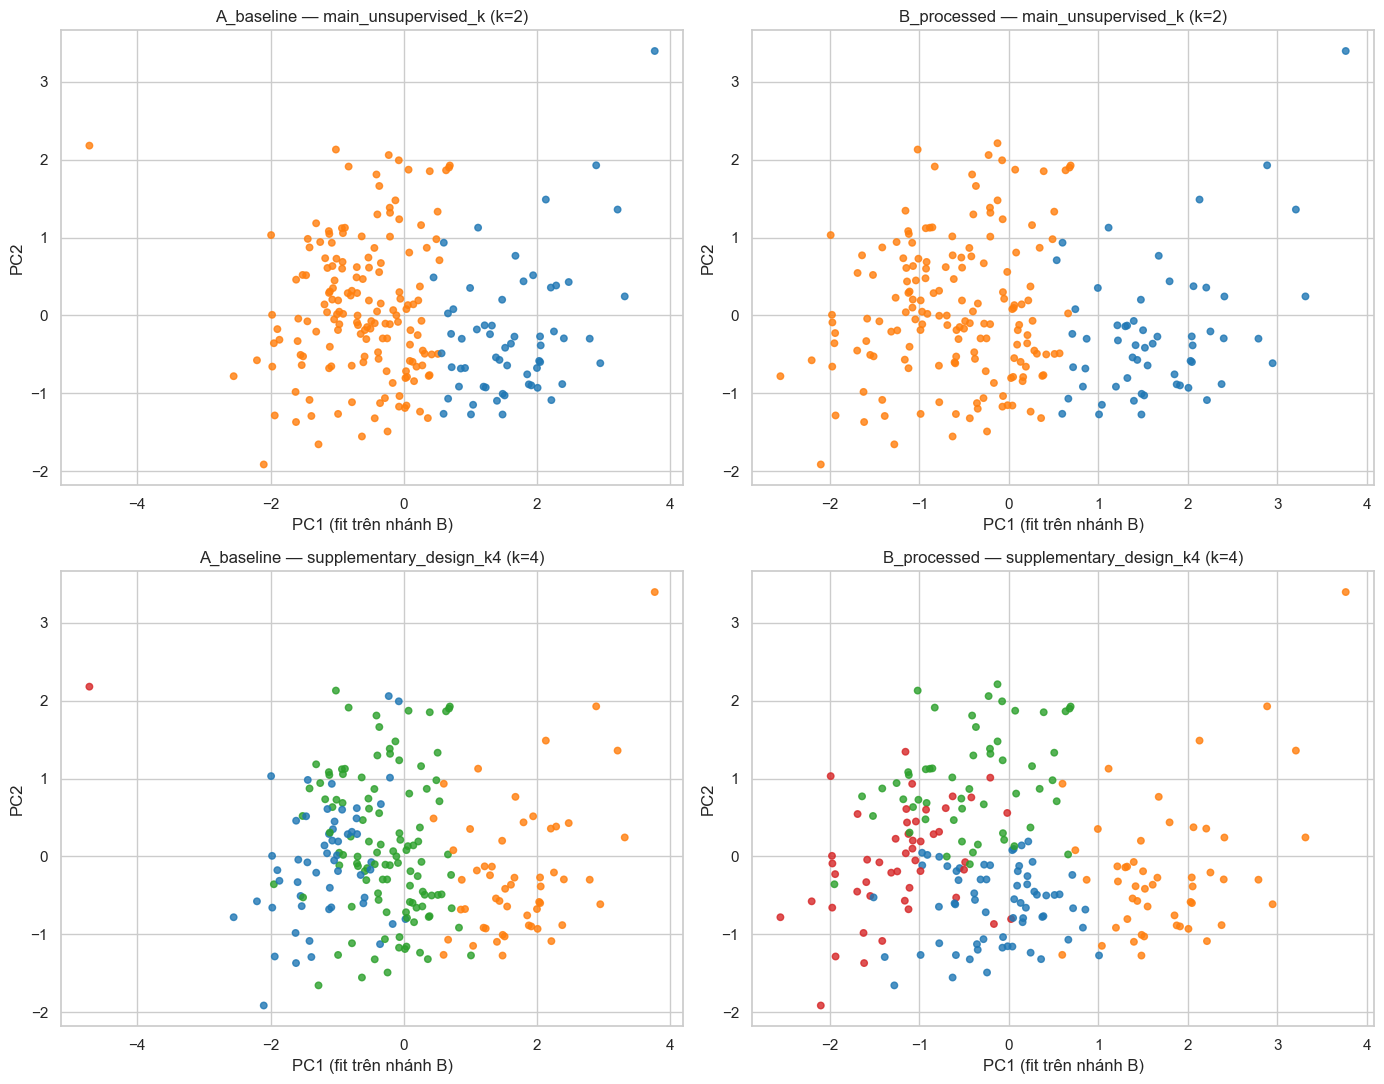

In [69]:
pca_view = PCA(n_components=2, random_state=SEED).fit(X_processed)
fig, axes = plt.subplots(len(experiments), 2, figsize=(14, 5.5 * len(experiments)), squeeze=False)
for row_axes, (experiment, k) in zip(axes, experiments):
    for ax, branch in zip(row_axes, branch_matrices):
        coords = pca_view.transform(branch_matrices[branch])
        scatter = ax.scatter(coords[:, 0], coords[:, 1], c=cluster_labels[(experiment, branch)],
                             cmap="tab10", s=22, alpha=0.8, vmin=0, vmax=9)
        ax.set_title(f"{branch} — {experiment} (k={k})")
        ax.set_xlabel("PC1 (fit trên nhánh B)")
        ax.set_ylabel("PC2")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "e_clusters_pca.png", dpi=150)
plt.show()

**Nhận xét.** Hai nhánh được chiếu lên cùng một mặt phẳng PCA, fit trên nhánh B.

- **k = 2:** hai nhánh gần như trùng nhau. Ranh giới chạy dọc theo PC1, tức mức độ mua hàng.
- **k = 4:** khác biệt rõ.
  - Nhánh A có một điểm cô lập ở PC1 ≈ −4.7, tạo thành cụm riêng. Ba cụm còn lại phải chia toàn bộ 219 khách, nên hai nhóm khách có hành vi khác nhau bị gộp thành một cụm 110 khách.
  - Nhánh B có 4 cụm kích thước tương đương. Ranh giới giữa các cụm vẫn chồng lấn, phù hợp với thiết kế dữ liệu.

### e.4. Hồ sơ cụm trên thang đo nghiệp vụ

Hồ sơ cụm được tính trên giá trị nghiệp vụ, không dùng giá trị đã chuẩn hóa:
- Nhánh B dùng `customers_preprocessed.csv` (có cả `total_spend_6m`).
- Nhánh A dùng chính dữ liệu mà baseline đã thấy: corrupted, chỉ điền trung vị. Mục đích là cho thấy hồ sơ cụm của baseline bị lỗi dữ liệu ảnh hưởng ra sao.

In [70]:
def cluster_profiles(business_df, labels):
    grouped = business_df.assign(cluster=labels).groupby("cluster")
    profile = grouped.agg(
        size=("customer_id", "size"),
        mean_spend=("total_spend_6m", "mean"),
        median_spend=("total_spend_6m", "median"),
        mean_orders=("orders_6m", "mean"),
        mean_avg_order_value=("avg_order_value", "mean"),
        mean_recency_days=("recency_days", "mean"),
        mean_sessions_30d=("sessions_30d", "mean"),
        mean_discount_rate=("discount_usage_rate", "mean"),
        mean_cart_abandonment=("cart_abandonment_rate", "mean"),
        mean_return_rate=("return_rate", "mean"),
        mean_category_diversity=("category_diversity", "mean"),
        mean_tenure_months=("tenure_months", "mean"),
    )
    profile["share"] = profile["size"] / len(business_df)
    profile["top_category"] = grouped["favorite_category"].agg(lambda s: s.value_counts().index[0])
    profile["top_device"] = grouped["preferred_device"].agg(lambda s: s.value_counts().index[0])
    return profile


profile_B_main = cluster_profiles(prepared_input, cluster_labels[("main_unsupervised_k", "B_processed")])
profile_B_main.round(2).T

cluster,0,1
size,58,162
mean_spend,11506.61,1582.94
median_spend,7373.33,1176.57
mean_orders,13.81,3.69
mean_avg_order_value,852.64,448.69
mean_recency_days,9.69,49.74
mean_sessions_30d,18.07,14.76
mean_discount_rate,0.28,0.48
mean_cart_abandonment,0.27,0.57
mean_return_rate,0.07,0.14


In [71]:
profile_A_main = cluster_profiles(baseline_df, cluster_labels[("main_unsupervised_k", "A_baseline")])
profile_A_main.round(2).T

cluster,0,1
size,60,160
mean_spend,11184.93,2978.61
median_spend,7249.58,1176.57
mean_orders,13.55,3.66
mean_avg_order_value,830.84,441.93
mean_recency_days,8.5,50.46
mean_sessions_30d,34.93,14.56
mean_discount_rate,0.27,0.48
mean_cart_abandonment,0.29,0.56
mean_return_rate,0.07,0.16


In [72]:
profile_B_k4 = cluster_profiles(prepared_input, cluster_labels[("supplementary_design_k4", "B_processed")])
profile_B_k4.round(2).T

cluster,0,1,2,3
size,65,51,55,49
mean_spend,2624.23,12446.4,1597.53,624.78
median_spend,2458.26,8126.0,1164.21,396.94
mean_orders,6.8,14.25,2.73,1.63
mean_avg_order_value,383.42,904.26,603.18,365.85
mean_recency_days,18.69,9.1,55.22,79.67
mean_sessions_30d,13.09,18.22,26.58,4.02
mean_discount_rate,0.68,0.24,0.38,0.35
mean_cart_abandonment,0.47,0.26,0.7,0.52
mean_return_rate,0.13,0.07,0.17,0.12


In [73]:
profile_A_k4 = cluster_profiles(baseline_df, cluster_labels[("supplementary_design_k4", "A_baseline")])
profile_A_k4.round(2).T

cluster,0,1,2,3
size,55,54,110,1
mean_spend,816.8,11981.54,4126.09,1876.77
median_spend,423.19,7831.8,1931.66,1876.77
mean_orders,1.93,14.04,4.78,9.0
mean_avg_order_value,386.14,873.29,472.32,208.53
mean_recency_days,80.27,8.44,33.59,17.0
mean_sessions_30d,4.07,36.13,20.35,12.0
mean_discount_rate,0.38,0.24,0.54,0.56
mean_cart_abandonment,0.49,0.27,0.58,0.7
mean_return_rate,0.12,0.07,0.15,1.85


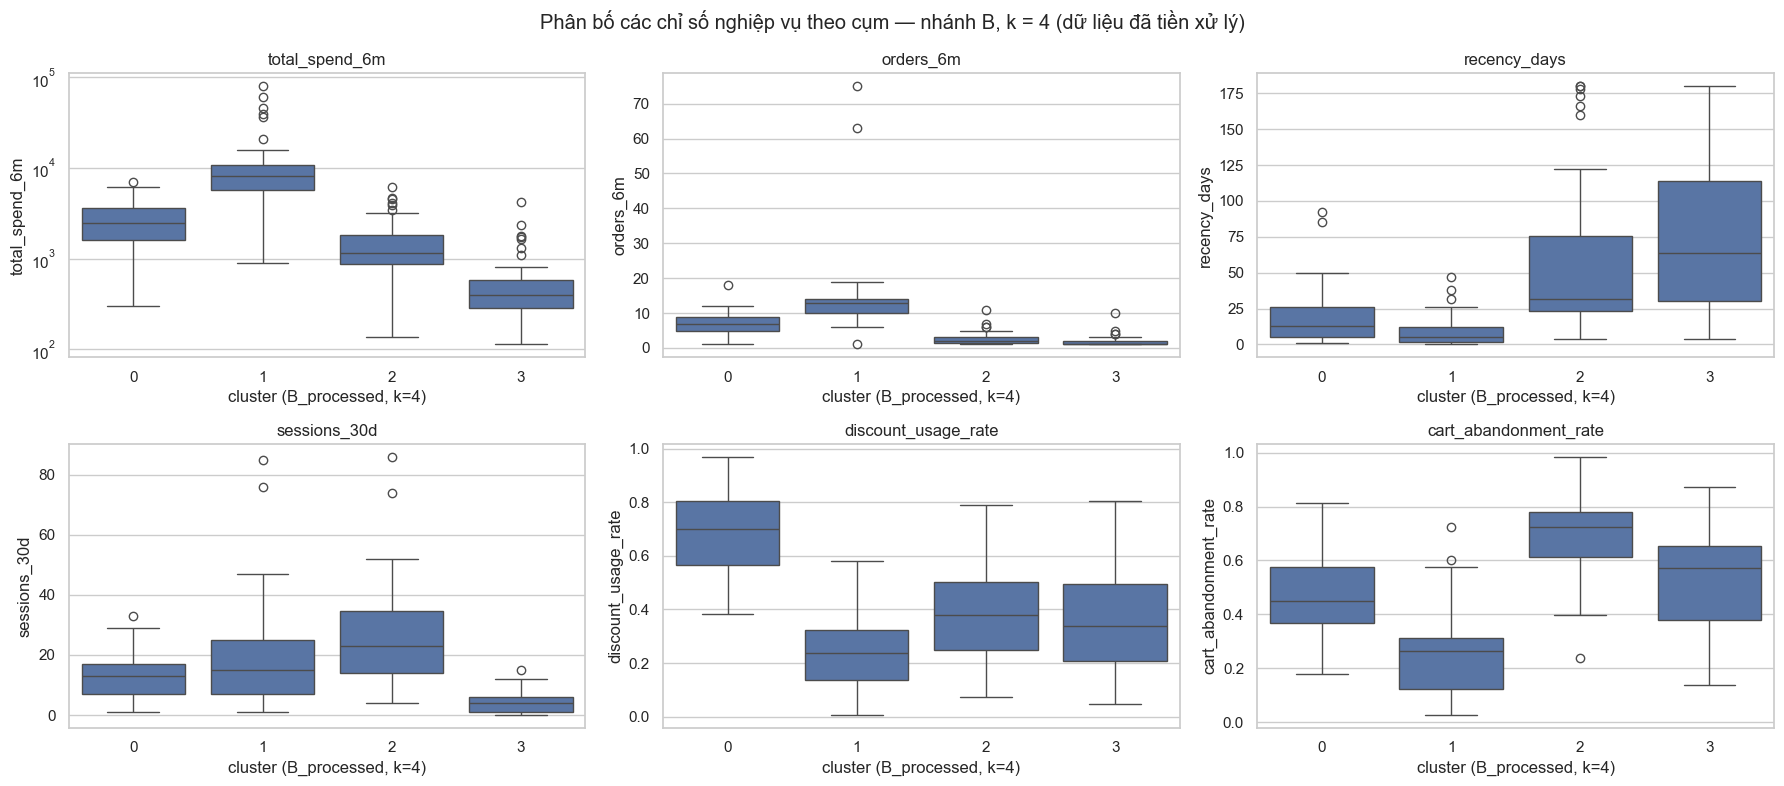

In [74]:
key_metrics = ["total_spend_6m", "orders_6m", "recency_days", "sessions_30d", "discount_usage_rate", "cart_abandonment_rate"]
labels_B_k4 = cluster_labels[("supplementary_design_k4", "B_processed")]

fig, axes = plt.subplots(2, 3, figsize=(18, 8))
for ax, metric in zip(axes.ravel(), key_metrics):
    sns.boxplot(x=labels_B_k4, y=prepared_input[metric], ax=ax)
    ax.set_title(metric)
    ax.set_xlabel("cluster (B_processed, k=4)")
    if metric == "total_spend_6m":
        ax.set_yscale("log")
fig.suptitle("Phân bố các chỉ số nghiệp vụ theo cụm — nhánh B, k = 4 (dữ liệu đã tiền xử lý)")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "e_cluster_profiles_B_k4.png", dpi=150)
plt.show()

**Đặt tên cụm.** Tên cụm được đặt sau khi đọc các bảng hồ sơ ở trên, dựa trên hành vi thực tế của các thành viên (xem nhận xét ở e.5). Mỗi tên đi kèm kích thước cụm và được kiểm tra bằng assert. Nếu kết quả phân cụm thay đổi, notebook sẽ báo lỗi thay vì gán tên sai.

In [75]:
CLUSTER_NAMES = {
    ("main_unsupervised_k", "B_processed"): {0: ("Giá trị cao, mua thường xuyên", 58), 1: ("Phổ thông, mua ít", 162)},
    ("main_unsupervised_k", "A_baseline"): {0: ("Giá trị cao, mua thường xuyên", 60), 1: ("Phổ thông, mua ít", 160)},
    ("supplementary_design_k4", "B_processed"): {
        0: ("Săn khuyến mãi", 65), 1: ("Trung thành giá trị cao", 51),
        2: ("Xem nhiều, ít mua", 55), 3: ("Ít hoạt động", 49)},
    ("supplementary_design_k4", "A_baseline"): {
        0: ("Ít hoạt động", 55), 1: ("Trung thành giá trị cao", 54),
        2: ("Hỗn hợp săn khuyến mãi và xem nhiều", 110), 3: ("Một bản ghi lỗi (return_rate = 1.85)", 1)},
}
profile_tables = {
    ("main_unsupervised_k", "B_processed"): profile_B_main, ("main_unsupervised_k", "A_baseline"): profile_A_main,
    ("supplementary_design_k4", "B_processed"): profile_B_k4, ("supplementary_design_k4", "A_baseline"): profile_A_k4,
}

profile_frames = []
for key, profile in profile_tables.items():
    names = CLUSTER_NAMES[key]
    assert {c: size for c, (_, size) in names.items()} == profile["size"].to_dict(), key
    frame = profile.reset_index()
    frame.insert(0, "cluster_name", frame["cluster"].map(lambda c: names[c][0]))
    frame.insert(0, "k", len(profile))
    frame.insert(0, "branch", key[1])
    frame.insert(0, "experiment", key[0])
    profile_frames.append(frame)

cluster_profile_table = pd.concat(profile_frames, ignore_index=True)
cluster_profile_table.to_csv(RESULT_DIR / "cluster_profiles.csv", index=False)
cluster_profile_table[["experiment", "branch", "cluster", "cluster_name", "size", "median_spend", "mean_orders",
                       "mean_recency_days", "mean_sessions_30d", "mean_discount_rate", "mean_cart_abandonment"]].round(2)

,experiment,branch,cluster,cluster_name,size,median_spend,mean_orders,mean_recency_days,mean_sessions_30d,mean_discount_rate,mean_cart_abandonment
0,main_unsupervised_k,B_processed,0,"Giá trị cao, mua thường xuyên",58,7373.33,13.81,9.69,18.07,0.28,0.27
1,main_unsupervised_k,B_processed,1,"Phổ thông, mua ít",162,1176.57,3.69,49.74,14.76,0.48,0.57
2,main_unsupervised_k,A_baseline,0,"Giá trị cao, mua thường xuyên",60,7249.58,13.55,8.50,34.93,0.27,0.29
3,main_unsupervised_k,A_baseline,1,"Phổ thông, mua ít",160,1176.57,3.66,50.46,14.56,0.48,0.56
4,supplementary_design_k4,B_processed,0,Săn khuyến mãi,65,2458.26,6.80,18.69,13.09,0.68,0.47
5,supplementary_design_k4,B_processed,1,Trung thành giá trị cao,51,8126.00,14.25,9.10,18.22,0.24,0.26
6,supplementary_design_k4,B_processed,2,"Xem nhiều, ít mua",55,1164.21,2.73,55.22,26.58,0.38,0.70
7,supplementary_design_k4,B_processed,3,Ít hoạt động,49,396.94,1.63,79.67,4.02,0.35,0.52
8,supplementary_design_k4,A_baseline,0,Ít hoạt động,55,423.19,1.93,80.27,4.07,0.38,0.49
9,supplementary_design_k4,A_baseline,1,Trung thành giá trị cao,54,7831.80,14.04,8.44,36.13,0.24,0.27


**Đối chiếu sau phân cụm với nhóm giả lập.** Bảng chéo giữa cụm và `true_segment` chỉ dùng để đánh giá, sau khi đã đặt tên cụm theo hành vi.

In [76]:
for key in [("supplementary_design_k4", "B_processed"), ("supplementary_design_k4", "A_baseline"),
            ("main_unsupervised_k", "B_processed")]:
    names = {c: f"{c}: {n}" for c, (n, _) in CLUSTER_NAMES[key].items()}
    table = pd.crosstab(pd.Series(cluster_labels[key]).map(names).rename("cluster"),
                        pd.Series(true_segments).rename("true_segment"))
    print(f"\n{key[1]} — {key[0]}\n{table.to_string()}")


B_processed — supplementary_design_k4
true_segment                Browser  Discount Seeker  Inactive  Loyal
cluster                                                              
0: Săn khuyến mãi                 8               53         0      4
1: Trung thành giá trị cao        0                1         1     49
2: Xem nhiều, ít mua             43                4         7      1
3: Ít hoạt động                   4                2        42      1

A_baseline — supplementary_design_k4
true_segment                             Browser  Discount Seeker  Inactive  Loyal
cluster                                                                           
0: Ít hoạt động                                4                5        45      1
1: Trung thành giá trị cao                     0                3         1     50
2: Hỗn hợp săn khuyến mãi và xem nhiều        51               51         4      4
3: Một bản ghi lỗi (return_rate = 1.85)        0                1         0      0

B_pr

### e.5. Diễn giải cụm và chiến lược tiếp thị

Tên cụm dựa trên hồ sơ nghiệp vụ ở e.4 (nhánh B, dữ liệu đã tiền xử lý). Đơn vị tiền là nghìn đồng.

**Thực nghiệm chính, k = 2 (nhánh B):**

| Cụm | Kích thước | Đặc điểm | Tên |
|---|---|---|---|
| 0 | 58 (26%) | Chi tiêu trung vị 7373; 13.8 đơn; recency 9.7 ngày; giá trị đơn 853; dùng giảm giá 0.28; bỏ giỏ 0.27; 4.3 danh mục | Giá trị cao, mua thường xuyên |
| 1 | 162 (74%) | Chi tiêu trung vị 1177; 3.7 đơn; recency 49.7 ngày; dùng giảm giá 0.48; bỏ giỏ 0.57 | Phổ thông, mua ít |

Phân chia này hợp lý về nghiệp vụ, nhưng quá thô cho tiếp thị. Cụm 1 gộp cả khách săn khuyến mãi, khách chỉ xem và khách ít hoạt động. Bảng chéo cho thấy cụm này gồm 55 Browser, 56 Discount Seeker và 49 Inactive. Các nhóm này cần cách tiếp cận khác nhau.

**Thực nghiệm bổ sung, k = 4 (nhánh B):**

| Cụm | Kích thước | Đặc điểm nổi bật | Tên |
|---|---|---|---|
| 0 | 65 (30%) | Dùng giảm giá 0.68 (cao nhất); 6.8 đơn; chi tiêu trung vị 2458; giá trị đơn 383 | Săn khuyến mãi |
| 1 | 51 (23%) | Chi tiêu trung vị 8126; 14.3 đơn; giá trị đơn 904; recency 9.1 ngày; bỏ giỏ 0.26; 4.4 danh mục; tenure 37 tháng | Trung thành giá trị cao |
| 2 | 55 (25%) | 26.6 phiên/30 ngày (cao nhất) nhưng chỉ 2.7 đơn; bỏ giỏ 0.70 (cao nhất); hoàn trả 0.17 | Xem nhiều, ít mua |
| 3 | 49 (22%) | 4.0 phiên; 1.6 đơn; recency 79.7 ngày; chi tiêu trung vị 397; thiết bị chủ yếu Mobile Web | Ít hoạt động |

Bảng chéo sau phân cụm cho thấy mỗi cụm có một nhóm giả lập chiếm đa số: 53/65, 49/51, 43/55 và 42/49. Các cụm vẫn lẫn một phần thành viên của nhóm khác, đúng với mức chồng lấn đã thiết kế.

Ở nhánh A (k = 4), khách săn khuyến mãi và khách chỉ xem bị gộp thành một cụm 110 khách (51 + 51), còn một cụm chỉ chứa bản ghi lỗi C0127. Hồ sơ cụm của A cũng bị lỗi làm méo:
- Chi tiêu trung bình của cụm 110 khách là 4126, trong khi trung vị chỉ 1932. Nguyên nhân là hai lỗi ×100.
- Số phiên trung bình của cụm trung thành là 36.1, trong khi ở B là 18.2. Nguyên nhân là giá trị 999.

Với k = 2, hiện tượng tương tự cũng xảy ra: chi tiêu trung bình của cụm phổ thông ở A là 2979, ở B là 1583.

**Đề xuất chiến lược tiếp thị (theo 4 cụm của nhánh B):**

- **Trung thành giá trị cao:** chương trình hạng thành viên, ưu đãi độc quyền, quyền mua sớm, gợi ý sản phẩm cao cấp và bán chéo, vì nhóm này mua đa dạng danh mục. Hạn chế phát mã giảm giá đại trà, vì nhóm này ít dùng giảm giá; giảm giá chỉ làm giảm biên lợi nhuận mà không tăng doanh số.
- **Săn khuyến mãi:** voucher có mục tiêu, flash sale, combo hoặc ngưỡng miễn phí vận chuyển để tăng giá trị đơn (hiện thấp, khoảng 383). Cần theo dõi biên lợi nhuận và tỷ lệ mua lại khi không có khuyến mãi.
- **Xem nhiều, ít mua:** nhắc giỏ hàng bị bỏ, retargeting, thông báo giảm giá cho sản phẩm đã xem, đơn giản hóa thanh toán. Tỷ lệ hoàn trả cao nhất (0.17) gợi ý cần mô tả sản phẩm và đánh giá rõ hơn.
- **Ít hoạt động:** chiến dịch kích hoạt lại (email, thông báo) với chi phí thấp, khảo sát lý do rời đi. Nhóm này chủ yếu dùng Mobile Web, nên có thể khuyến khích cài ứng dụng. Ngân sách cho nhóm này nên giới hạn theo giá trị kỳ vọng.

**Lựa chọn số cụm cho ứng dụng.** Theo tiêu chí không giám sát (Silhouette, Davies–Bouldin), k = 2 là tốt nhất. k = 4 có Silhouette thấp hơn (0.153 so với 0.191), nhưng tạo ra các nhóm có ý nghĩa hành động rõ ràng hơn, và Elbow có một khuỷu yếu ở k = 4. Lựa chọn k = 4 cho mục đích tiếp thị dựa trên khả năng diễn giải nghiệp vụ. Kết quả ARI cao hơn ở k = 4 chỉ là xác nhận sau, nhờ có nhãn giả lập; trên dữ liệu thực sẽ không có thông tin này.

### e.6. Tổng kết câu e

Giả thuyết ban đầu là tiền xử lý giúp phân cụm phản ánh cấu trúc khách hàng tốt hơn.

- **Với k = 4, kết quả ủng hộ giả thuyết.** Tiền xử lý loại bỏ cụm 1 phần tử do bản ghi lỗi, tách được khách săn khuyến mãi khỏi khách chỉ xem, tăng ARI từ 0.495 lên 0.644, và đưa kết quả gần với dữ liệu sạch (ARI 0.905).
- **Với k = 2, tác động nhỏ.** Ranh giới chính (mức độ mua hàng) đã đủ rõ để chịu được lỗi.
- **Các chỉ số dựa trên khoảng cách không luôn cải thiện theo cùng hướng.** Davies–Bouldin ở k = 4 xấu hơn sau tiền xử lý, vì baseline được "thưởng" khi tách riêng một điểm lỗi.
- **Có những khía cạnh không phản ánh trong các chỉ số phân cụm.** Lỗi trong `total_spend_6m` không ảnh hưởng đến việc gán cụm, vì cột này không nằm trong tập đặc trưng. Tuy vậy, nó làm sai hồ sơ cụm dùng để ra quyết định kinh doanh, và tiền xử lý đã khắc phục được điều này.

## Kiểm chứng toàn bộ pipeline

Mỗi điều kiện kiểm chứng bắt buộc được viết thành một hàm kiểm tra. Hàm trả về chi tiết và gây lỗi (`AssertionError`) nếu điều kiện không thỏa. Các kiểm tra đọc lại dữ liệu từ đĩa, thay vì chỉ dùng biến trong bộ nhớ.

In [77]:
def read_saved(name, folder=DATA_DIR):
    return pd.read_csv(folder / name)


def check_original_shape():
    original = read_saved("customers_original.csv")
    features = [c for c in original.columns if c != "customer_id"]
    assert len(original) == N_CUSTOMERS and len(features) == N_INPUT_FEATURES and features == INPUT_FEATURES
    return f"{len(original)} records, {len(features)} input features"


REPORT_GENERATED_DIR = PROJECT_DIR / "reports" / "generated"
REPORT_GENERATED_DIR.mkdir(parents=True, exist_ok=True)


def check_missing_attributes():
    missing = read_saved("customers_corrupted.csv")[INPUT_FEATURES].isna().sum()
    missing = missing[missing > 0]
    assert len(missing) >= 2
    return ", ".join(f"{c}: {n}" for c, n in missing.items())


def check_noisy_attributes():
    original = read_saved("customers_original.csv").set_index("customer_id")
    corrupted = read_saved("customers_corrupted.csv").set_index("customer_id")
    meta = read_saved("simulation_metadata.csv", METADATA_DIR)
    noisy = {}
    for column, flag in [("total_spend_6m", "noise_total_spend"), ("sessions_30d", "noise_sessions")]:
        ids = meta.loc[meta[flag], "customer_id"]
        assert pd.api.types.is_numeric_dtype(corrupted[column])
        noisy[column] = int((original.loc[ids, column] != corrupted.loc[ids, column]).sum())
    assert sum(n > 0 for n in noisy.values()) >= 2
    return ", ".join(f"{c}: {n} values changed" for c, n in noisy.items())


def check_outlier_ids():
    meta = read_saved("simulation_metadata.csv", METADATA_DIR)
    ids = meta.loc[meta["is_outlier"], "customer_id"]
    assert ids.nunique() >= MIN_OUTLIER_IDS
    return f"{ids.nunique()} distinct customer_id"


def check_id_alignment():
    original, corrupted = read_saved("customers_original.csv"), read_saved("customers_corrupted.csv")
    meta = read_saved("simulation_metadata.csv", METADATA_DIR)
    assert original["customer_id"].is_unique and corrupted["customer_id"].is_unique
    assert set(original["customer_id"]) == set(corrupted["customer_id"]) == set(meta["customer_id"])
    merged = original.merge(corrupted, on="customer_id", suffixes=("_orig", "_corr"), validate="one_to_one")
    assert len(merged) == N_CUSTOMERS
    return f"one-to-one merge on customer_id: {len(merged)} rows"


def check_preprocessed_no_nan():
    preprocessed = read_saved("customers_preprocessed.csv")
    assert len(preprocessed) == N_CUSTOMERS and preprocessed[INPUT_FEATURES].notna().all().all()
    return f"no NaN in the {len(INPUT_FEATURES)} input features"


def check_matrices_finite():
    for name, matrix in {"customers_prepared.csv": read_saved("customers_prepared.csv"),
                         "A_baseline": X_baseline, "B_processed": X_processed}.items():
        values = matrix.to_numpy(dtype=float)
        assert np.isfinite(values).all(), name
    return "customers_prepared.csv, A_baseline, B_processed: all finite"


def check_no_id_or_label():
    forbidden = {"customer_id", "true_segment"} | set(read_saved("simulation_metadata.csv", METADATA_DIR).columns)
    for matrix in [read_saved("customers_prepared.csv"), X_baseline, X_processed]:
        assert not forbidden & set(matrix.columns)
    return "no customer_id / true_segment / metadata columns"


def check_same_feature_space():
    assert list(X_baseline.columns) == list(X_processed.columns) == FEATURE_COLUMNS
    assert X_baseline.shape == X_processed.shape
    # Cùng hệ quy chiếu: bản ghi có giá trị gốc giống nhau ở hai nhánh phải có vector đặc trưng giống hệt nhau.
    model_columns = MODEL_NUMERIC_FEATURES + CATEGORICAL_FEATURES
    same_raw = (baseline_df[model_columns].reset_index(drop=True) == prepared_input[model_columns]).all(axis=1).to_numpy()
    assert np.allclose(X_baseline.to_numpy()[same_raw], X_processed.to_numpy()[same_raw])
    return f"{len(FEATURE_COLUMNS)} identical columns; {same_raw.sum()} records with identical raw values map identically"


REQUIRED_FILES = [
    DATA_DIR / "customers_original.csv", DATA_DIR / "customers_corrupted.csv",
    DATA_DIR / "customers_preprocessed.csv", DATA_DIR / "customers_prepared.csv",
    DATA_DIR / "prepared_customer_ids.csv", METADATA_DIR / "simulation_metadata.csv",
    RESULT_DIR / "clustering_metrics.csv", RESULT_DIR / "cluster_profiles.csv", RESULT_DIR / "cluster_labels.csv",
    RESULT_DIR / "k_selection.csv", RESULT_DIR / "preprocessing_changes.csv",
]
# Các tệp LaTeX sinh ra trước bước kiểm chứng (bảng kết quả kiểm chứng được ghi sau nên không nằm trong danh sách).
REQUIRED_GENERATED = ["values.tex", "table_metrics.tex", "table_k_survey.tex", "table_detection.tex",
                      "table_profiles_B_k2.tex", "table_profiles_B_k4.tex"]
REQUIRED_FIGURES = [
    "a_clean_features_by_segment.png", "a_noise_before_after.png", "b_histograms_corrupted.png",
    "b_log_histograms_corrupted.png", "b_boxplot_robust_scaled.png", "b_correlation_heatmaps.png",
    "c_before_after_preprocessing.png", "d_pca_overview.png", "e_k_selection.png", "e_clusters_pca.png",
    "e_cluster_profiles_B_k4.png",
]


def check_files_saved():
    paths = (REQUIRED_FILES + [FIGURE_DIR / name for name in REQUIRED_FIGURES]
             + [REPORT_GENERATED_DIR / name for name in REQUIRED_GENERATED])
    missing = [str(p.relative_to(PROJECT_DIR)) for p in paths if not p.exists() or p.stat().st_size == 0]
    assert not missing, missing
    return (f"{len(REQUIRED_FILES)} CSV files, {len(REQUIRED_FIGURES)} figures, "
            f"{len(REQUIRED_GENERATED)} generated LaTeX files present and non-empty")

In [78]:
def regenerate_simulation(seed):
    # Chạy lại toàn bộ bước sinh dữ liệu với một bộ sinh ngẫu nhiên mới, cùng seed và cùng thứ tự gọi.
    fresh_rng = np.random.default_rng(seed)
    simulated_again = generate_clean_customers(fresh_rng)
    original_again = simulated_again[["customer_id"] + INPUT_FEATURES].copy()
    labels_again = simulated_again[["customer_id", "true_segment"]].copy()
    business_again, error_again = select_outlier_ids(labels_again, fresh_rng)
    eligible = np.setdiff1d(original_again["customer_id"].to_numpy(), business_again + error_again)
    corrupted_again, _, _ = add_gaussian_noise(original_again, eligible, fresh_rng)
    apply_business_outliers(corrupted_again, business_again, fresh_rng)
    apply_error_outliers(corrupted_again, error_again)
    missing_aov_again, missing_cart_again = add_missing_values(corrupted_again, eligible, fresh_rng)
    return original_again, corrupted_again, labels_again, set(business_again + error_again), missing_aov_again, missing_cart_again


def frames_match(a, b):
    if list(a.columns) != list(b.columns) or len(a) != len(b):
        return False
    for column in a.columns:
        if pd.api.types.is_numeric_dtype(a[column]):
            if not np.allclose(a[column].to_numpy(float), b[column].to_numpy(float), equal_nan=True):
                return False
        elif not (a[column].to_numpy() == b[column].to_numpy()).all():
            return False
    return True


def check_reproducibility():
    original_again, corrupted_again, labels_again, outliers_again, aov_again, cart_again = regenerate_simulation(SEED)
    meta = read_saved("simulation_metadata.csv", METADATA_DIR)
    assert frames_match(original_again, read_saved("customers_original.csv"))
    assert frames_match(corrupted_again, read_saved("customers_corrupted.csv"))
    assert (labels_again["true_segment"].to_numpy() == meta["true_segment"].to_numpy()).all()
    assert outliers_again == set(meta.loc[meta["is_outlier"], "customer_id"])
    assert aov_again == set(meta.loc[meta["missing_avg_order_value"], "customer_id"])
    assert cart_again == set(meta.loc[meta["missing_cart_abandonment_rate"], "customer_id"])
    clean_again = transform_features(original_again, fitted_transformers)
    assert np.allclose(clean_again.to_numpy(), X_clean_reference.to_numpy())
    for experiment, k in experiments:
        for branch, X in evaluated_matrices.items():
            again = KMeans(n_clusters=k, **KMEANS_PARAMS).fit(X).labels_
            assert (again == cluster_labels[(experiment, branch)]).all(), (experiment, branch)
    return (f"simulation regenerated with seed {SEED} matches saved CSV/metadata; "
            f"K-Means labels identical on refit for {len(evaluated_matrices)} matrices x {len(experiments)} experiments")

**Số liệu cho báo cáo.** Để các con số trong báo cáo LaTeX khớp với kết quả thực nghiệm, notebook ghi chúng ra `reports/generated/` dưới dạng macro và bảng LaTeX. Báo cáo chỉ tham chiếu các macro này, không gõ tay số liệu. Kiểm tra cuối cùng đọc lại file macro và đối chiếu với các file kết quả CSV.

In [79]:
def fmt(value, digits=3):
    return f"{value:.{digits}f}"


def metric(experiment, branch, column):
    row = clustering_results[(clustering_results["experiment"] == experiment) & (clustering_results["branch"] == branch)]
    return row[column].iloc[0]


detection_lookup = detection_summary.set_index("method")
missing_counts = raw_df[INPUT_FEATURES].isna().sum()
eval_lookup = imputation_eval.groupby("column")[["abs_error_method", "abs_error_global_median"]].mean()
pre_eval_table = pd.DataFrame(pre_eval_rows).set_index("outlier_type")
cart_missing_sessions = compare_by_missing(eda_df, "cart_abandonment_rate", ["sessions_30d"]).loc["sessions_30d"]
has_missing = eda_df[INPUT_FEATURES].isna().any(axis=1)

report_values = {
    "NCustomers": N_CUSTOMERS, "NInputFeatures": N_INPUT_FEATURES, "NNumericFeatures": len(NUMERIC_FEATURES),
    "NCategories": len(CATEGORIES), "NDevices": len(DEVICES), "NDropped": len(DROPPED_FEATURES),
    "SegLoyal": SEGMENT_SIZES["Loyal"], "SegDiscount": SEGMENT_SIZES["Discount Seeker"],
    "SegBrowser": SEGMENT_SIZES["Browser"], "SegInactive": SEGMENT_SIZES["Inactive"],
    "TrueSilhouette": fmt(true_label_silhouette),
    "MissAovCount": int(missing_counts["avg_order_value"]),
    "MissAovPct": fmt(100 * missing_counts["avg_order_value"] / N_CUSTOMERS, 2),
    "MissCartCount": int(missing_counts["cart_abandonment_rate"]),
    "MissCartPct": fmt(100 * missing_counts["cart_abandonment_rate"] / N_CUSTOMERS, 2),
    "NoiseRecords": int(noise_summary.loc["total_spend_6m", "n_records"]),
    "NoiseSpendRelPct": fmt(100 * noise_summary.loc["total_spend_6m", "mean_abs_relative_change"], 1),
    "NoiseSpendCorr": fmt(noise_summary.loc["total_spend_6m", "corr_before_after"]),
    "NoiseSessionsAbs": fmt(noise_summary.loc["sessions_30d", "mean_abs_delta"], 2),
    "NoiseSessionsRelPct": fmt(100 * noise_summary.loc["sessions_30d", "mean_abs_relative_change"], 1),
    "NoiseSessionsSd": fmt(noise_params["sessions_30d_sd"]),
    "NoiseSessionsChanged": int(simulation_checks.loc["noise_records_changed_sessions_30d", "value"]),
    "OutlierIds": int(simulation_checks.loc["outlier_ids", "value"]),
    "OutlierBusiness": int(simulation_checks.loc["outlier_business_valid", "value"]),
    "OutlierError": int(simulation_checks.loc["outlier_data_error", "value"]),
    "UntouchedRecords": int(simulation_checks.loc["untouched_records", "value"]),
    "CartMissSessMedian": fmt(cart_missing_sessions["missing"], 1),
    "CartObsSessMedian": fmt(cart_missing_sessions["observed"], 1),
    "MissingRecords": int(has_missing.sum()),
    "MissingRecordsPct": fmt(100 * has_missing.mean(), 1),
    "SkewSessions": fmt(numeric_summary.loc["sessions_30d", "skewness"], 2),
    "SkewSpend": fmt(numeric_summary.loc["total_spend_6m", "skewness"], 2),
    "StdSpendCorrupted": fmt(numeric_summary.loc["total_spend_6m", "std"], 0),
    "StdReturnCorrupted": fmt(numeric_summary.loc["return_rate", "std"]),
    "SpearOrdersSpend": fmt(spearman_corr.loc["orders_6m", "total_spend_6m"], 2),
    "PearOrdersSpend": fmt(pearson_corr.loc["orders_6m", "total_spend_6m"], 2),
    "PearOrigOrdersSpend": fmt(original_pearson.loc["orders_6m", "total_spend_6m"]),
    "StdRatioSessions": fmt(before_after_stats.loc["sessions_30d", "std_ratio"], 2),
    "StdRatioSpend": fmt(before_after_stats.loc["total_spend_6m", "std_ratio"], 2),
    "InvalidCells": len(invalid_log), "ImputedCells": len(preprocessing_changes),
    "MissingCellsBefore": int(raw_df[INPUT_FEATURES].isna().sum().sum()),
    "SessionsStdBefore": fmt(preprocessing_stats.loc["sessions_30d", "std_before"], 2),
    "SessionsStdAfter": fmt(preprocessing_stats.loc["sessions_30d", "std_after"], 2),
    "SpendStdBefore": fmt(preprocessing_stats.loc["total_spend_6m", "std_before"], 0),
    "SpendStdAfter": fmt(preprocessing_stats.loc["total_spend_6m", "std_after"], 0),
    "MaeAovMethod": fmt(eval_lookup.loc["avg_order_value", "abs_error_method"], 1),
    "MaeAovMedian": fmt(eval_lookup.loc["avg_order_value", "abs_error_global_median"], 1),
    "MaeCartMethod": fmt(eval_lookup.loc["cart_abandonment_rate", "abs_error_method"]),
    "MaeCartMedian": fmt(eval_lookup.loc["cart_abandonment_rate", "abs_error_global_median"]),
    "PreIqrOneRecords": int(pre_iqr_flags[1.5].any(axis=1).sum()),
    "PreIqrThreeRecords": int(extreme_flags.any(axis=1).sum()),
    "PreIqrThreeNotInjected": int(pre_eval_table.loc["not_injected", "flagged_iqr_k3.0_after"]),
    "LogZSpendRaw": fmt(leverage_check.loc["total_spend_6m", "max_robust_z_raw"], 2),
    "LogZSpendLog": fmt(leverage_check.loc["total_spend_6m", "max_robust_z_log1p"], 2),
    "SpendRatioDeviating": int(((spend_ratio_after - 1).abs() > 0.01).sum()),
    "LogSpendExplainedPct": fmt(100 * (1 - residual.var() / log_spend.var()), 2),
    "FeatureDims": len(FEATURE_COLUMNS), "NumericDims": len(MODEL_NUMERIC_FEATURES),
    "OnehotDims": len(FEATURE_COLUMNS) - len(MODEL_NUMERIC_FEATURES),
    "AovVarSharePct": fmt(100 * contribution.loc["log_avg_order_value", "share_of_total_variance"], 1),
    "PcaTwoPct": fmt(100 * explained["cumulative"].iloc[1], 1),
    "PcaFivePct": fmt(100 * explained["cumulative"].iloc[4], 1),
    "KMain": K_MAIN, "KDesign": K_DESIGN,
    "AriAvsBMain": fmt(agreement["ari_A_vs_B"].iloc[0]),
    "AriBvsCleanKfour": fmt(agreement.set_index("k").loc[K_DESIGN, "ari_B_vs_clean_reference"]),
    "AriAvsCleanKfour": fmt(agreement.set_index("k").loc[K_DESIGN, "ari_A_vs_clean_reference"]),
}
for method, prefix in [("business_rules", "DetRules"), ("iqr_k1.5", "DetIqrOne"), ("iqr_k3.0", "DetIqrThree"),
                       ("rules_or_iqr_k3.0", "DetComb")]:
    report_values[f"{prefix}Total"] = int(detection_lookup.loc[method, "detected_total_of_12"])
    report_values[f"{prefix}False"] = int(detection_lookup.loc[method, "flagged_not_injected"])
for experiment, tag in [("main_unsupervised_k", "Main"), ("supplementary_design_k4", "Kfour")]:
    for branch, btag in [("A_baseline", "A"), ("B_processed", "B"), ("reference_clean_original", "Clean")]:
        report_values[f"Sil{tag}{btag}"] = fmt(metric(experiment, branch, "silhouette"))
        report_values[f"Db{tag}{btag}"] = fmt(metric(experiment, branch, "davies_bouldin"))
        report_values[f"Ari{tag}{btag}"] = fmt(metric(experiment, branch, "ari_vs_true_segment"))
        report_values[f"Sizes{tag}{btag}"] = metric(experiment, branch, "cluster_sizes")

# Các nhận định định tính được viết trong báo cáo; mỗi nhận định phải đúng với kết quả vừa chạy.
survey_A = k_survey[k_survey["branch"] == "A_baseline"].set_index("k")
survey_B = k_survey[k_survey["branch"] == "B_processed"].set_index("k")
inertia_drop = -survey_B["inertia"].diff()
error_ids = set(simulation_metadata.loc[simulation_metadata["outlier_type"] == "data_error", "customer_id"])
iqr15_missed = per_outlier_detection.index[~per_outlier_detection["iqr_k1.5"]]
report_claims = {
    "rules_catch_all_errors_without_false_flags":
        report_values["DetRulesTotal"] == report_values["OutlierError"] and report_values["DetRulesFalse"] == 0,
    "iqr15_misses_only_negative_values": set(per_outlier_detection.loc[iqr15_missed, "violated_rules"]) == {"negative_count"},
    "invalid_cells_are_exactly_the_error_outliers": set(invalid_log["customer_id"]) == error_ids,
    "cart_group_median_not_better_than_global": eval_lookup.loc["cart_abandonment_rate", "abs_error_method"]
        >= eval_lookup.loc["cart_abandonment_rate", "abs_error_global_median"],
    "aov_definition_better_than_global": eval_lookup.loc["avg_order_value", "abs_error_method"]
        < eval_lookup.loc["avg_order_value", "abs_error_global_median"],
    "B_silhouette_and_db_best_at_k_main": int(survey_B["davies_bouldin"].idxmin()) == K_MAIN,
    "weak_elbow_at_k4": inertia_drop[4] > 1.5 * inertia_drop[5],
    "A_has_singleton_cluster_for_all_k_ge_3": (survey_A.loc[3:, "min_cluster_size"] == 1).all(),
    "A_best_silhouette_and_db_at_k3": int(survey_A["silhouette"].idxmax()) == 3 and int(survey_A["davies_bouldin"].idxmin()) == 3,
    "B_better_than_A_on_all_metrics_main": metric("main_unsupervised_k", "B_processed", "silhouette") > metric("main_unsupervised_k", "A_baseline", "silhouette")
        and metric("main_unsupervised_k", "B_processed", "davies_bouldin") < metric("main_unsupervised_k", "A_baseline", "davies_bouldin")
        and metric("main_unsupervised_k", "B_processed", "ari_vs_true_segment") > metric("main_unsupervised_k", "A_baseline", "ari_vs_true_segment"),
    "k4_singleton_removed_by_preprocessing": metric("supplementary_design_k4", "A_baseline", "min_cluster_size") == 1
        and metric("supplementary_design_k4", "B_processed", "min_cluster_size") > 1,
    "k4_db_worse_after_preprocessing": metric("supplementary_design_k4", "B_processed", "davies_bouldin")
        > metric("supplementary_design_k4", "A_baseline", "davies_bouldin"),
    "ari_gain_larger_at_k4_than_main":
        (metric("supplementary_design_k4", "B_processed", "ari_vs_true_segment") - metric("supplementary_design_k4", "A_baseline", "ari_vs_true_segment"))
        > (metric("main_unsupervised_k", "B_processed", "ari_vs_true_segment") - metric("main_unsupervised_k", "A_baseline", "ari_vs_true_segment")) > 0,
    "all_silhouettes_below_0_25": (clustering_results["silhouette"] < 0.25).all() and (k_survey["silhouette"] < 0.25).all(),
}
failed_claims = [name for name, holds in report_claims.items() if not holds]
assert not failed_claims, failed_claims
print(f"{len(report_claims)} qualitative report claims verified")

assert all(key.isalpha() for key in report_values)
with open(REPORT_GENERATED_DIR / "values.tex", "w", encoding="utf-8") as handle:
    handle.write("% Generated by notebooks/customer_segmentation.ipynb. Do not edit by hand.\n")
    for key, value in report_values.items():
        handle.write(f"\\newcommand{{\\{key}}}{{{value}}}\n")
print(f"Wrote {len(report_values)} macros to reports/generated/values.tex")

14 qualitative report claims verified
Wrote 100 macros to reports/generated/values.tex


In [80]:
LATEX_SPECIAL = {"\\": r"\textbackslash{}", "&": r"\&", "%": r"\%", "$": r"\$", "#": r"\#", "_": r"\_",
                 "{": r"\{", "}": r"\}", "~": r"\textasciitilde{}", "^": r"\textasciicircum{}"}


def latex_escape(text):
    return "".join(LATEX_SPECIAL.get(ch, ch) for ch in str(text))


def write_latex_table(df, path, column_format):
    lines = [rf"\begin{{tabular}}{{{column_format}}}", r"\toprule",
             " & ".join(latex_escape(c) for c in df.columns) + r" \\", r"\midrule"]
    lines += [" & ".join(latex_escape(v) for v in row) + r" \\" for row in df.itertuples(index=False)]
    lines += [r"\bottomrule", r"\end{tabular}"]
    path.write_text("\n".join(lines) + "\n", encoding="utf-8")


branch_labels = {"A_baseline": "A (baseline)", "B_processed": "B (processed)", "reference_clean_original": "Tham chiếu sạch"}
metrics_table = pd.DataFrame({
    "Thí nghiệm": clustering_results["experiment"].map({"main_unsupervised_k": f"Chính (k={K_MAIN})",
                                                        "supplementary_design_k4": f"Bổ sung (k={K_DESIGN})"}),
    "Nhánh": clustering_results["branch"].map(branch_labels),
    "Kích thước cụm": clustering_results["cluster_sizes"],
    "Silhouette": clustering_results["silhouette"].map(fmt),
    "Davies–Bouldin": clustering_results["davies_bouldin"].map(fmt),
    "ARI": clustering_results["ari_vs_true_segment"].map(fmt),
})
write_latex_table(metrics_table, REPORT_GENERATED_DIR / "table_metrics.tex", "llcccc")

survey_table = k_survey.pivot(index="k", columns="branch", values=["silhouette", "davies_bouldin", "min_cluster_size"])
survey_out = pd.DataFrame({
    "k": survey_table.index,
    "Sil. A": survey_table[("silhouette", "A_baseline")].map(fmt).to_numpy(),
    "Sil. B": survey_table[("silhouette", "B_processed")].map(fmt).to_numpy(),
    "DB A": survey_table[("davies_bouldin", "A_baseline")].map(fmt).to_numpy(),
    "DB B": survey_table[("davies_bouldin", "B_processed")].map(fmt).to_numpy(),
    "Cụm nhỏ nhất A": survey_table[("min_cluster_size", "A_baseline")].astype(int).to_numpy(),
    "Cụm nhỏ nhất B": survey_table[("min_cluster_size", "B_processed")].astype(int).to_numpy(),
})
write_latex_table(survey_out, REPORT_GENERATED_DIR / "table_k_survey.tex", "ccccccc")

detection_out = detection_summary.assign(method=detection_summary["method"].map({
    "business_rules": "Quy tắc nghiệp vụ", "iqr_k1.5": "IQR, k = 1.5", "iqr_k3.0": "IQR, k = 3",
    "rules_or_iqr_k3.0": "Quy tắc hoặc IQR k = 3"})).rename(columns={
    "method": "Phương pháp",
    "flagged_records": "Bị đánh dấu",
    "detected_business_valid": f"Bắt được (nghiệp vụ, {OUTLIER_BUSINESS_COUNT})",
    "detected_data_error": f"Bắt được (lỗi, {OUTLIER_ERROR_COUNT})",
    "detected_total_of_12": f"Bắt được (tổng, {OUTLIER_BUSINESS_COUNT + OUTLIER_ERROR_COUNT})",
    "flagged_not_injected": "Đánh dấu nhầm",
})
assert set(detection_out.columns).isdisjoint(detection_summary.columns), "every column must be renamed"
write_latex_table(detection_out, REPORT_GENERATED_DIR / "table_detection.tex", "lccccc")

k4_names = CLUSTER_NAMES[("supplementary_design_k4", "B_processed")]
profiles_out = pd.DataFrame({
    "Cụm": [k4_names[c][0] for c in profile_B_k4.index],
    "Số khách": profile_B_k4["size"].to_numpy(),
    "Chi tiêu (trung vị)": profile_B_k4["median_spend"].map(lambda v: fmt(v, 0)).to_numpy(),
    "Số đơn": profile_B_k4["mean_orders"].map(lambda v: fmt(v, 1)).to_numpy(),
    "Recency (ngày)": profile_B_k4["mean_recency_days"].map(lambda v: fmt(v, 1)).to_numpy(),
    "Phiên/30 ngày": profile_B_k4["mean_sessions_30d"].map(lambda v: fmt(v, 1)).to_numpy(),
    "Giảm giá": profile_B_k4["mean_discount_rate"].map(lambda v: fmt(v, 2)).to_numpy(),
    "Bỏ giỏ": profile_B_k4["mean_cart_abandonment"].map(lambda v: fmt(v, 2)).to_numpy(),
})
write_latex_table(profiles_out, REPORT_GENERATED_DIR / "table_profiles_B_k4.tex", "lccccccc")

k2_names = CLUSTER_NAMES[("main_unsupervised_k", "B_processed")]
profiles_k2_out = pd.DataFrame({
    "Cụm": [k2_names[c][0] for c in profile_B_main.index],
    "Số khách": profile_B_main["size"].to_numpy(),
    "Chi tiêu (trung vị)": profile_B_main["median_spend"].map(lambda v: fmt(v, 0)).to_numpy(),
    "Số đơn": profile_B_main["mean_orders"].map(lambda v: fmt(v, 1)).to_numpy(),
    "Recency (ngày)": profile_B_main["mean_recency_days"].map(lambda v: fmt(v, 1)).to_numpy(),
    "Phiên/30 ngày": profile_B_main["mean_sessions_30d"].map(lambda v: fmt(v, 1)).to_numpy(),
    "Giảm giá": profile_B_main["mean_discount_rate"].map(lambda v: fmt(v, 2)).to_numpy(),
    "Bỏ giỏ": profile_B_main["mean_cart_abandonment"].map(lambda v: fmt(v, 2)).to_numpy(),
})
write_latex_table(profiles_k2_out, REPORT_GENERATED_DIR / "table_profiles_B_k2.tex", "lccccccc")
print(sorted(p.name for p in REPORT_GENERATED_DIR.iterdir()))

['table_detection.tex', 'table_k_survey.tex', 'table_metrics.tex', 'table_pipeline_checks.tex', 'table_profiles_B_k2.tex', 'table_profiles_B_k4.tex', 'values.tex']


In [81]:
def check_report_values_match_results():
    # Đọc lại macro từ đĩa và tính lại độc lập các số liệu chính từ các tệp đã lưu (dữ liệu, nhãn cụm, kết quả).
    macros = dict(re.findall(r"\\newcommand\{\\(\w+)\}\{([^}]*)\}",
                             (REPORT_GENERATED_DIR / "values.tex").read_text(encoding="utf-8")))
    report_source = (PROJECT_DIR / "reports" / "report.tex").read_text(encoding="utf-8")
    used = set(re.findall(r"\\([A-Z][A-Za-z]+)", report_source))
    undefined = sorted(m for m in used if m not in macros)
    assert not undefined, f"macros used in report.tex but not generated: {undefined}"

    meta = read_saved("simulation_metadata.csv", METADATA_DIR)
    corrupted = read_saved("customers_corrupted.csv")
    prepared = read_saved("customers_prepared.csv")
    labels = read_saved("cluster_labels.csv", RESULT_DIR)
    survey = read_saved("k_selection.csv", RESULT_DIR)
    changes = read_saved("preprocessing_changes.csv", RESULT_DIR)
    original = read_saved("customers_original.csv").set_index("customer_id")
    truth = meta.set_index("customer_id").loc[labels["customer_id"], "true_segment"].to_numpy()

    recomputed = {
        "OutlierIds": str(int(meta["is_outlier"].sum())),
        "ImputedCells": str(len(changes)),
        "MissAovCount": str(int(corrupted["avg_order_value"].isna().sum())),
        "MissCartCount": str(int(corrupted["cart_abandonment_rate"].isna().sum())),
        "KMain": str(int(survey[survey["branch"] == "B_processed"].set_index("k")["silhouette"].idxmax())),
        "PcaTwoPct": fmt(100 * PCA(random_state=SEED).fit(prepared).explained_variance_ratio_[:2].sum(), 1),
        "SilMainB": fmt(silhouette_score(prepared, labels["main_unsupervised_k__B_processed"])),
        "SilKfourB": fmt(silhouette_score(prepared, labels["supplementary_design_k4__B_processed"])),
        "AriBvsCleanKfour": fmt(adjusted_rand_score(labels["supplementary_design_k4__B_processed"],
                                                    labels["supplementary_design_k4__reference_clean_original"])),
        "AriAvsBMain": fmt(adjusted_rand_score(labels["main_unsupervised_k__A_baseline"],
                                               labels["main_unsupervised_k__B_processed"])),
    }
    for experiment, tag in [("main_unsupervised_k", "Main"), ("supplementary_design_k4", "Kfour")]:
        for branch, btag in [("A_baseline", "A"), ("B_processed", "B"), ("reference_clean_original", "Clean")]:
            column = labels[f"{experiment}__{branch}"]
            recomputed[f"Ari{tag}{btag}"] = fmt(adjusted_rand_score(truth, column))
            recomputed[f"Sizes{tag}{btag}"] = "/".join(map(str, sorted(np.bincount(column), reverse=True)))
    cart_changes = changes[changes["column"] == "cart_abandonment_rate"]
    cart_truth = [original.at[c, "cart_abandonment_rate"] for c in cart_changes["customer_id"]]
    recomputed["MaeCartMethod"] = fmt(np.mean(np.abs(cart_changes["final_value"].to_numpy() - cart_truth)))

    mismatches = {k: (macros.get(k), v) for k, v in recomputed.items() if macros.get(k) != v}
    assert not mismatches, mismatches
    assert all(report_claims.values())
    return (f"{len(used & set(macros))} macros used in report.tex all defined; {len(recomputed)} values recomputed "
            f"from saved files match; {len(report_claims)} qualitative claims hold")


pipeline_checks = [
    ("1. Original data: 220 records, 12 input features", check_original_shape),
    ("2. >= 2 attributes with missing values (corrupted)", check_missing_attributes),
    ("3. >= 2 numeric attributes with added noise", check_noisy_attributes),
    ("4. >= 11 distinct customer_id with injected outliers", check_outlier_ids),
    ("5. Original and corrupted aligned by customer_id", check_id_alignment),
    ("6. Preprocessed data: no NaN in clustering fields", check_preprocessed_no_nan),
    ("7. Feature matrices: no NaN / infinity", check_matrices_finite),
    ("8. No ID or simulation label in K-Means matrices", check_no_id_or_label),
    ("9. Same feature space, column order and scaling in both branches", check_same_feature_space),
    ("10. CSV files, figures and result tables saved", check_files_saved),
    ("11. Re-run with the same seed reproduces data and clusters", check_reproducibility),
    ("12. Report values generated from and matching experiment results", check_report_values_match_results),
]
check_rows = []
for name, check in pipeline_checks:
    # Ghi nhận FAIL thay vì dừng ngay, để bảng kết quả luôn được ghi lại và không giữ kết quả cũ.
    try:
        check_rows.append({"check": name, "status": "PASS", "detail": check()})
    except Exception as error:
        check_rows.append({"check": name, "status": "FAIL", "detail": f"{type(error).__name__}: {error}"})
pipeline_check_table = pd.DataFrame(check_rows)
pipeline_check_table.to_csv(RESULT_DIR / "pipeline_checks.csv", index=False)
CHECK_LABELS_VI = [
    "Dữ liệu gốc: 220 bản ghi, 12 thuộc tính đầu vào",
    "Ít nhất 2 thuộc tính có giá trị thiếu (corrupted)",
    "Ít nhất 2 thuộc tính số được thêm nhiễu",
    "Ít nhất 11 customer_id khác nhau được tạo ngoại lai",
    "Gốc và corrupted đối chiếu được bằng customer_id",
    "Dữ liệu sau tiền xử lý không còn NaN ở trường phân cụm",
    "Ma trận đặc trưng không có NaN hoặc vô cực",
    "Không có cột ID hoặc nhãn giả lập trong ma trận K-Means",
    "Hai nhánh cùng không gian đặc trưng, thứ tự cột, thang đo",
    "Các tệp CSV, biểu đồ, bảng kết quả đã được lưu",
    "Chạy lại với cùng seed cho cùng dữ liệu và cùng cụm",
    "Số liệu trong báo cáo được sinh từ và khớp với kết quả",
]
assert len(CHECK_LABELS_VI) == len(pipeline_check_table)
write_latex_table(pd.DataFrame({"Kiểm tra": CHECK_LABELS_VI, "Kết quả": pipeline_check_table["status"]}),
                  REPORT_GENERATED_DIR / "table_pipeline_checks.tex", "lc")
with pd.option_context("display.max_colwidth", 140):
    display(pipeline_check_table)
failed_checks = pipeline_check_table.loc[pipeline_check_table["status"] == "FAIL", "check"].tolist()
assert not failed_checks, f"Pipeline checks failed: {failed_checks}"

,check,status,detail
0,"1. Original data: 220 records, 12 input features",PASS,"220 records, 12 input features"
1,2. >= 2 attributes with missing values (corrupted),PASS,"avg_order_value: 15, cart_abandonment_rate: 18"
2,3. >= 2 numeric attributes with added noise,PASS,"total_spend_6m: 88 values changed, sessions_30d: 74 values changed"
3,4. >= 11 distinct customer_id with injected outliers,PASS,12 distinct customer_id
4,5. Original and corrupted aligned by customer_id,PASS,one-to-one merge on customer_id: 220 rows
5,6. Preprocessed data: no NaN in clustering fields,PASS,no NaN in the 12 input features
6,7. Feature matrices: no NaN / infinity,PASS,"customers_prepared.csv, A_baseline, B_processed: all finite"
7,8. No ID or simulation label in K-Means matrices,PASS,no customer_id / true_segment / metadata columns
8,"9. Same feature space, column order and scaling in both branches",PASS,20 identical columns; 184 records with identical raw values map identically
9,"10. CSV files, figures and result tables saved",PASS,"11 CSV files, 11 figures, 6 generated LaTeX files present and non-empty"
